# 02 Measurement 2026 — Reproducible experimental analysis

This notebook contains the experimental model implementations, the original
research plotting functions, and the code needed to regenerate the article's
numerical tables and data-dependent figures. The complete executable functions are in `src/lorenzetti_repro/`.

### Choose one of three execution modes

1. **Published results:** Set `EXECUTION_MODE = 'replay'` and
   `REPLAY_SOURCE = 'original'`. Place the original trusted prediction/result
   pickles in `artifacts/pickles/`. `Run All Cells` recalculates metrics and
   figures from the saved events. No training is required.
2. **New training:** Set `EXECUTION_MODE = 'train'`. The notebook reads the
   Lorenzetti input `data/Lorenzetti_electrons_merge_root.csv` (or extracts it
   from the repository's compressed data archive). The specified models are
   trained and their artifacts saved to a **new unique** directory under
   `artifacts/new_runs/measurement/`. No historical files are overwritten.
3. **Replay a new training:** Set `EXECUTION_MODE = 'replay'` and
   `REPLAY_SOURCE = 'latest_new_run'` or `'specific_new_run'`, configuring
   `NEW_RUN_ID` for the latter. The new experiment's pickles are analyzed
   using the same plotting functions.

The figure coverage table near the end reports, by **paper figure number**, all
panels produced from original source cells or saved predictions and identifies
missing input artifacts. Source-dataset diagnostics additionally require the
original Lorenzetti CSV. Historical timing charts require the original measured
prediction times. Original serialized pickle objects should only be loaded
from trusted sources.

**Scientific protocol:** D70/D30 is held separately; in Stages II and III the
5×5 nested CV for `f_ML` is conditional on the representation fitted in D70.
No fit/selection uses the final D30 hold-out. The benchmark is Lorenzetti,
not the official online ATLAS chain.


## 1. Execution environment and source implementations


In [1]:
# Keep PCA/ICA linear algebra from oversubscribing the Jupyter kernel.
# Increase this only after benchmarking the target machine.
from threadpoolctl import threadpool_limits
NUMERICAL_THREADS = 1
_THREADPOOL_CONTROL = threadpool_limits(limits=NUMERICAL_THREADS)

from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Code, Markdown

def locate_root():
    # Works with "Run All" either from project root or /notebooks.
    here=Path.cwd().resolve()
    for folder in (here,*here.parents):
        if (folder/'src'/'lorenzetti_repro').is_dir() and (folder/'papers').is_dir():
            return folder
    raise FileNotFoundError('Project root not located. Open this notebook from the extracted GitHub project.')

ROOT=locate_root()
for p in (ROOT,ROOT/'src'):
    if str(p) not in sys.path:sys.path.insert(0,str(p))
from lorenzetti_repro.article_workflow import (find_input_folders,prepare_data_optional,
    load_article_artifacts,analyze_article)
from lorenzetti_repro.article_training import (train_article,ARTICLE_MODELS,REPRESENTATIONS)
from lorenzetti_repro.original_figure_environment import configure_original_figure_style
ORIGINAL_LATEX_AVAILABLE = configure_original_figure_style(require_latex=False)
if not ORIGINAL_LATEX_AVAILABLE:
    print('Publication typography requires LaTeX and dvipng; install them for exact original font rendering.')
print('PROJECT:',ROOT)
print('Available model families:',ARTICLE_MODELS['measurement'])
print('Available representations:',len(REPRESENTATIONS['measurement']))

PROJECT: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation
Available model families: ('dtree', 'bdt', 'rf', 'bdtrf', 'rfbdt', 'rfbdts')
Available representations: 18


### Model, representation, statistical and graphical functions


In [2]:
# Scientific implementations and original plotting functions.
SOURCE_FILES=['original_plotting.py', 'original_replay.py', 'models/stage1_segmented.py',
              'models/hybrids.py', 'representations.py', 'model_runner.py',
              'selection.py','statistics.py','article_training.py','original_data_plots.py','timing_recovery.py']
for name in SOURCE_FILES:
    path=ROOT/'src'/'lorenzetti_repro'/name
    assert path.is_file(), f'Missing source module: {path}'
    print(name, ':', len(path.read_text(encoding='utf8').splitlines()), 'lines')
from lorenzetti_repro import original_plotting as original
print('Original experimental plotting functions:',
      ', '.join(['comparison_hist_boxplot_erros','comparison_metric_all',
                'integrated_plots_in_ETA_ET_geral_with_ranges',
                'boxplot_comparison_improved','plot_resolution_curves',
                'lambda_analysis','qq_plot']))


original_plotting.py : 4086 lines
original_replay.py : 592 lines
models/stage1_segmented.py : 44 lines
models/hybrids.py : 100 lines
representations.py : 82 lines
model_runner.py : 36 lines
selection.py : 61 lines
statistics.py : 93 lines
article_training.py : 216 lines
original_data_plots.py : 38 lines
timing_recovery.py : 74 lines
Original experimental plotting functions: comparison_hist_boxplot_erros, comparison_metric_all, integrated_plots_in_ETA_ET_geral_with_ranges, boxplot_comparison_improved, plot_resolution_curves, lambda_analysis, qq_plot


## 2. Lorenzetti input dataset and saved experiment artifacts


In [3]:
# Locate and extract the Lorenzetti dataset (not required to replay saved predictions).
# Load pickle archives only if they originate from your trusted research environment.
EXTRACT_DATA = True
TRUST_MY_PICKLES = True

from lorenzetti_repro.legacy_artifacts import catalog
PICKLE_DIR, DATA_DIR = find_input_folders(ROOT)
print('Dataset directory:', DATA_DIR)
print('Pickle directory:', PICKLE_DIR)
DATA_CSV = prepare_data_optional(ROOT, extract=False)
if DATA_CSV:
    print('Lorenzetti CSV:', DATA_CSV)
elif EXTRACT_DATA:
    try:
        DATA_CSV = prepare_data_optional(ROOT, extract=True)
        print('Extracted Lorenzetti CSV:', DATA_CSV)
    except (FileNotFoundError, ValueError, RuntimeError) as exc:
        # Dataset is not needed for replay of per-event predictions saved in pickles.
        # It IS mandatory to retrain and for original-dataset feature-relevance plots.
        raise FileNotFoundError(
            'Lorenzetti source events are required for the pre-training figures. '
            'Place the compressed original dataset or Lorenzetti_electrons_merge_root.csv '
            'inside Data/ in the local clone and ensure Git LFS files have been downloaded. '
            f'Dataset discovery details: {type(exc).__name__}: {exc}'
        ) from exc
if DATA_CSV is not None:
    from lorenzetti_repro.dataset import read_dataset, EXPECTED_EVENTS
    data_schema = read_dataset(DATA_CSV)
    print('Dataset:', len(data_schema), 'events /', len(data_schema.columns), 'columns')
    if len(data_schema) != EXPECTED_EVENTS:
        print('WARNING: event count differs from the thesis benchmark:', EXPECTED_EVENTS)
    del data_schema

# Windows may hide the final .zip extension of files such as BDT_noSEG_Full_DF.pkl.zip.
# Expand only the article's known, individually ZIP-wrapped DataFrame files.
# Never unpack the very large *_noSEG_times.pkl model-object archives automatically.
EXTRACT_ZIPPED_PICKLES = True
if EXTRACT_ZIPPED_PICKLES and TRUST_MY_PICKLES and PICKLE_DIR.is_dir():
    import zipfile, shutil
    from lorenzetti_repro.legacy_artifacts import ARTICLE_METHODS
    allowed_methods = set(ARTICLE_METHODS['measurement'])
    unpacked_wrappers = []
    for wrapper in sorted(PICKLE_DIR.rglob('*.zip')):
        expected_filename = wrapper.name[:-4]
        if not expected_filename.lower().endswith(('.pkl', '.pkl.gz')):
            continue
        if not any(expected_filename.startswith(m + '_') or expected_filename.startswith('result_' + m + '_') or expected_filename.startswith('integrated_result_' + m + '_') for m in allowed_methods):
            continue
        if expected_filename.endswith('_noSEG_times.pkl') or expected_filename.endswith('_noSEG_times.pkl.gz'):
            continue
        destination = PICKLE_DIR/expected_filename
        if destination.exists():
            continue
        with zipfile.ZipFile(wrapper) as archive:
            candidates = [item for item in archive.infolist() if not item.is_dir()
                          and Path(item.filename).name == expected_filename]
            if len(candidates) != 1:
                print('ZIP wrapper does not contain a uniquely named pickle:', wrapper.name)
                continue
            if candidates[0].file_size > 900_000_000:
                print('Large wrapped file not unpacked automatically:', wrapper.name)
                continue
            with archive.open(candidates[0], 'r') as source, destination.open('xb') as output:
                shutil.copyfileobj(source, output)
            unpacked_wrappers.append(destination.name)
    if unpacked_wrappers:
        print('Unpacked ZIP-wrapped DataFrame results:', unpacked_wrappers)

ARTIFACTS = pd.DataFrame(catalog(PICKLE_DIR, checksum=False))
if not ARTIFACTS.empty:
    print('Saved artifact files:', len(ARTIFACTS))
    display(ARTIFACTS[['method', 'kind', 'relative_path', 'bytes']])
else:
    print('No .pkl or .pkl.gz artifacts found in:', PICKLE_DIR)
    print('Copy your original saved results under artifacts/pickles/ without renaming files.')
    wrapped = sorted(p for p in PICKLE_DIR.rglob('*.zip') if p.is_file()) if PICKLE_DIR.is_dir() else []
    if wrapped:
        print('Detected ZIP-wrapped pickles; extract their contents first:', [p.name for p in wrapped[:10]])

Dataset directory: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\Data
Pickle directory: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\artifacts\pickles
Lorenzetti CSV: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\Data\Lorenzetti_electrons_merge_root.csv
Dataset: 396590 events / 108 columns
Saved artifact files: 88


,method,kind,relative_path,bytes
0,BDT,noSEG_cv_metrics_df,BDT_noSEG_cv_metrics_df.pkl.gz,2587
1,BDT,noSEG_erros_data,BDT_noSEG_erros_data.pkl.gz,12362253
2,BDT,noSEG_erros_data_alpha,BDT_noSEG_erros_data_alpha.pkl.gz,11996105
3,BDT,noSEG_Full_DF,BDT_noSEG_Full_DF.pkl.gz,52036597
4,BDT,noSEG_performance_metrics,BDT_noSEG_performance_metrics.pkl.gz,4302
...,...,...,...,...
83,SGNN,noSEG_erros_data,SGNN_noSEG_erros_data.pkl.gz,12206237
84,SGNN,noSEG_erros_data_alpha,SGNN_noSEG_erros_data_alpha.pkl.gz,12056063
85,SGNN,noSEG_Full_DF,SGNN_noSEG_Full_DF.pkl.gz,46220120
86,SGNN,noSEG_performance_metrics,SGNN_noSEG_performance_metrics.pkl.gz,4386


## 3. Experimental training and persistence


In [4]:
# Execution mode: 'replay' uses the original saved predictions (no model training).
# To fit models from scratch, set EXECUTION_MODE='train' and list the pairs below.
EXECUTION_MODE = 'replay'  # 'replay' or 'train'; never silently start training
ARTICLE = 'measurement'
REPLAY_SOURCE = 'original'  # 'original', 'latest_new_run', or 'specific_new_run'
NEW_RUN_ID = None  # e.g. '20261106T150001_000001Z_a1b2c3d4' for specific_new_run
TRAIN_SELECTION = 'nested'
TRAIN_CONFIGURATIONS = None  # e.g. [('bdt', 'PCA-10')]; None = stage model sweep
PERSIST_MODELS = True

from lorenzetti_repro.run_storage import choose_replay_dir, make_new_run
REPLAY_PICKLE_DIR = None
RUN_BASE = None
if EXECUTION_MODE not in ('replay', 'train', 'auto'):
    raise ValueError(f'Invalid EXECUTION_MODE: {EXECUTION_MODE}')
if not TRUST_MY_PICKLES and EXECUTION_MODE != 'train':
    raise PermissionError('Enable TRUST_MY_PICKLES only for research files you personally trust.')

from lorenzetti_repro.legacy_artifacts import ARTICLE_METHODS
if EXECUTION_MODE == 'train':
    if not DATA_CSV:
        DATA_CSV = prepare_data_optional(ROOT, extract=True)
    if not DATA_CSV:
        raise FileNotFoundError('Training needs Lorenzetti_electrons_merge_root.csv under data/ or Data/.')
    RUN_BASE, REPLAY_PICKLE_DIR = make_new_run(ROOT, ARTICLE)
    TRAINED = train_article(ARTICLE, ROOT, DATA_CSV,
                            selection=TRAIN_SELECTION, chosen=TRAIN_CONFIGURATIONS,
                            save_fitted_models=PERSIST_MODELS,
                            output_dir=REPLAY_PICKLE_DIR)
    print('Finished training configurations:', len(TRAINED))
    print('New run archive:', RUN_BASE)
else:
    REPLAY_PICKLE_DIR = choose_replay_dir(ROOT,ARTICLE,REPLAY_SOURCE,NEW_RUN_ID)
    print('Loading experiment results from:', REPLAY_PICKLE_DIR)
    if not REPLAY_PICKLE_DIR.exists():
        raise FileNotFoundError(f'Saved experiment directory not found: {REPLAY_PICKLE_DIR}')


Loading experiment results from: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\artifacts\pickles


## 4. Archived results: model predictions and statistical tables


In [5]:
# Retrieve archived results and generate the paper's data-driven figures.
from lorenzetti_repro.article_workflow import load_article_artifacts, historic_method_tables
from lorenzetti_repro.paper_figure_suite import reproduce_paper_figure_set, PAPER_OUTPUTS

PLOT_OUTPUT = ((RUN_BASE/'figures') if RUN_BASE is not None else
    (ROOT/'results'/'replayed'/ARTICLE/'paper_figures' if REPLAY_SOURCE == 'original'
    else REPLAY_PICKLE_DIR.parent/'figures'))
PLOT_OUTPUT.mkdir(parents=True, exist_ok=True)
folder, inventory, bundles, event_frames = load_article_artifacts(
    ARTICLE, ROOT, trust_local_pickle=TRUST_MY_PICKLES, pickle_dir=REPLAY_PICKLE_DIR)
print('Available stored model families:', list(bundles))
print('Event-level prediction configurations:', len(event_frames))
if event_frames:
    display(pd.DataFrame([{'configuration':key, 'events':len(frame)}
                          for key,frame in sorted(event_frames.items())]))
ARCHIVED_TABLES, TABLE_FILES = historic_method_tables(bundles, PLOT_OUTPUT.parent/'tables')
for name,table in ARCHIVED_TABLES.items():
    print('Archived table:',name, 'rows:',len(table))
    display(table)

# Fitted models inside *_times.pkl are optional; numeric measured times are
# extracted separately and never substituted with a benchmark guess.
TIME_CSV = ROOT/'artifacts'/'metadata'/'prediction_times.csv'
if REPLAY_SOURCE == 'original' and RUN_BASE is None and TRUST_MY_PICKLES:
    from lorenzetti_repro.timing_recovery import recover_timing_csv
    try:
        TIME_CSV = recover_timing_csv(ARTICLE, PICKLE_DIR, TIME_CSV, trusted=True)
        print('Measured numeric times:',TIME_CSV)
    except (FileNotFoundError, ValueError, TypeError, AttributeError, ImportError, ModuleNotFoundError) as exc:
        print('Original timing data unavailable:',type(exc).__name__,str(exc))

PAPER_REPORT = reproduce_paper_figure_set(
    ARTICLE, event_frames, bundles, PLOT_OUTPUT,
    data_csv=DATA_CSV, timing_csv=TIME_CSV if TIME_CSV.is_file() else None,
    new_run=(RUN_BASE is not None or REPLAY_SOURCE != 'original'),
)
ORIGINAL_REPORT = PAPER_REPORT['original_report']
# Numerical tables from the original post-training comparisons.
RESULT_TABLES = PAPER_REPORT['supplementary_report'].get('tables', {})
for name, location in RESULT_TABLES.items():
    print('Experimental comparison table:', name)
    display(pd.read_csv(location))
print('Generated image files:',len(PAPER_REPORT['files']))
if 'computed_summary' in ORIGINAL_REPORT:
    display(ORIGINAL_REPORT['computed_summary'])
if 'ranking' in ORIGINAL_REPORT:
    display(ORIGINAL_REPORT['ranking'])


Available stored model families: ['DTREE', 'BDT', 'RFOR', 'BDTRF', 'RFBDT', 'RFBDTS']
Event-level prediction configurations: 108


,configuration,events
0,BDT no-Bin: CORR-10,90786
1,BDT no-Bin: CORR-2,90786
2,BDT no-Bin: CORR-5,90786
3,BDT no-Bin: CORR-50,90786
4,BDT no-Bin: ICA-10,90786
...,...,...
103,RFOR no-Bin: PCA-2,90786
104,RFOR no-Bin: PCA-5,90786
105,RFOR no-Bin: PCA-50,90786
106,RFOR no-Bin: Rings/2,90786


Archived table: DTREE_noSEG_performance_metrics rows: 19


,Evaluation-Method,Feature-Selection-Method,Selected-Features,Energy Normalized-Error-Mean,Energy Normalized-Error-Sdt,RMSE (MeV),RMSE/E_true_min (%),Correlation Coefficient (%),IQR (MeV),d0 (MeV),...,F-H0: f-ACR (0.05),F-H1: Errfast_var > Errcalib_var,F-H1: IC[Errcalib_var/Errfast_var; 0.95],T-H0: Errfast_mean = Errcalib_mean,T-H0: p-value (0.05),T-H0: t-value (0.05),T-H0: t-critical (0.05),T-H0: t-ACR (0.05),T-H1: Errfast_mean > Errcalib_mean,T-H1: IC[Errfast_mean - Errcalib_mean; 0.95]
0,DTREE no-Bin,Standard FastCalo,Rings[1:100],2770.580312,2839.355816,3967.121969,0.79,99.95,2457.106750,4666.415144,...,Not tested,Not tested,[],"True, Standard vs Standard",Not tested,Not tested,Not tested,Not tested,Not tested,[]
1,DTREE no-Bin,Rings[1:100],Rings[1:100],-27.698608,1896.808383,1897.010610,0.38,99.98,1851.639884,2650.890325,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.4405114037011395, 0.45212383861460614]",False,0.0,246.917608,1.959979,"[-1.9599789650995834, 1.9599789650995834]",True,"[2774.4944978746244, 2822.063342901579]"
2,DTREE no-Bin,Rings/2,"[0, 1, 2, 3, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",-25.343525,1885.015430,1885.185791,0.38,99.98,1886.352017,2666.880087,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.43505088246678353, 0.4465193711693353]",False,0.0,247.182989,1.959979,"[-1.9599790185892438, 1.9599790185892438]",True,"[2772.1426021649863, 2819.70507185413]"
3,DTREE no-Bin,PCA-50,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-112.800398,2453.822456,2456.413763,0.49,99.96,1887.935913,3098.107582,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.7372189804272353, 0.7566530004213955]",False,0.0,231.504042,1.959977,"[-1.9599773242865506, 1.9599773242865506]",True,"[2858.714259172906, 2908.0471612145593]"
4,DTREE no-Bin,PCA-10,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-103.152367,2285.587077,2287.913612,0.46,99.96,1893.703785,2969.960054,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.6395960582110043, 0.6564566151329859]",False,0.0,237.552031,1.959978,"[-1.9599776461383687, 1.9599776461383687]",True,"[2849.4873612524984, 2897.977996868776]"
5,DTREE no-Bin,PCA-5,"[pc0, pc1, pc2, pc3, pc4]",-114.967082,2267.067045,2269.980268,0.45,99.96,1898.858393,2959.471847,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.6292728038714684, 0.6458612268189245]",False,0.0,239.289176,1.959978,"[-1.9599776901893213, 1.9599776901893213]",True,"[2861.340199272644, 2909.7545900412106]"
6,DTREE no-Bin,PCA-2,"[pc0, pc1]",-10.583039,2757.489679,2757.509988,0.55,99.95,2011.347508,3413.118827,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.9309750158533161, 0.9555166887517429]",False,0.0,211.718482,1.959977,"[-1.9599770611285232, 1.9599770611285232]",True,"[2755.405810373254, 2806.920891734443]"
7,DTREE no-Bin,CORR-50,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10, 80, 11,...",-41.519738,2205.777186,2206.167918,0.44,99.97,1855.929640,2882.993533,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.5957081145786542, 0.6114117300806533]",False,0.0,235.65807,1.959978,"[-1.9599778487742991, 1.9599778487742991]",True,"[2788.0073258887332, 2836.1927759310984]"
8,DTREE no-Bin,CORR-10,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10]",-14.455545,2370.524617,2370.568692,0.47,99.96,1895.013431,3034.908866,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.6880170081389874, 0.7061540022309553]",False,0.0,226.868242,1.959977,"[-1.9599774663969547, 1.9599774663969547]",True,"[2760.59471873634, 2809.4769952236165]"
9,DTREE no-Bin,CORR-5,"[74, 75, 73, 72, 76]",5.133426,2539.217347,2539.222536,0.51,99.96,1966.433964,3211.621650,...,"[0.9870743686522786, 1.013094891082391]",True,"[0.7894233856190296, 0.8102335794247927]",False,0.0,218.748537,1.959977,"[-1.9599772116831022, 1.9599772116831022]",True,"[2740.515716677378, 2790.378055215915]"


Archived table: DTREE_noSEG_cv_metrics_df rows: 18


,Method-Selection,$R^2$,Pearson Correlation,RMSE,IQR,$d_\text{CV}$,Train Time ($\mu$ s),Pred. Time ($\mu$ s),$R^2$ ($\text{CI}_\text{95\%}$),Pearson Correlation ($\text{CI}_\text{95\%}$),RMSE ($\text{CI}_\text{95\%}$),IQR ($\text{CI}_\text{95\%}$),$d_\text{CV}$ ($\text{CI}_\text{95\%}$),Train Time ($\mu$ s) ($\text{CI}_\text{95\%}$),Pred. Time ($\mu$ s) ($\text{CI}_\text{95\%}$)
0,DTREE no-Bin: Rings[1:100],0.5069$\pm$0.0171,0.7147$\pm$0.0135,0.0352$\pm$0.0016,0.0197$\pm$0.0001,1.2134$\pm$0.3898,158.1616$\pm$6.0703,0.5332$\pm$0.2272,"[0.4856, 0.5281]","[0.6979, 0.7315]","[0.0332, 0.0372]","[0.0195, 0.0199]","[0.7294, 1.6973]","[150.6244, 165.6988]","[0.2510, 0.8153]"
0,DTREE no-Bin: Rings/2,0.4986$\pm$0.0096,0.7081$\pm$0.0079,0.0355$\pm$0.0015,0.0199$\pm$0.0001,1.2319$\pm$0.3766,80.8707$\pm$2.8955,0.2770$\pm$0.1809,"[0.4868, 0.5105]","[0.6983, 0.7180]","[0.0336, 0.0373]","[0.0198, 0.0201]","[0.7643, 1.6996]","[77.2754, 84.4659]","[0.0523, 0.5016]"
0,DTREE no-Bin: PCA-50,0.4688$\pm$0.0097,0.6878$\pm$0.0075,0.0365$\pm$0.0014,0.0199$\pm$0.0001,1.3785$\pm$0.2999,80.9439$\pm$2.4350,0.1472$\pm$0.2016,"[0.4568, 0.4809]","[0.6785, 0.6970]","[0.0348, 0.0382]","[0.0198, 0.0201]","[1.0061, 1.7510]","[77.9205, 83.9673]","[-0.1031, 0.3976]"
0,DTREE no-Bin: PCA-10,0.4748$\pm$0.0108,0.6908$\pm$0.0083,0.0363$\pm$0.0015,0.0200$\pm$0.0001,1.3333$\pm$0.4665,16.1868$\pm$0.8997,0.0622$\pm$0.0857,"[0.4613, 0.4882]","[0.6805, 0.7011]","[0.0344, 0.0382]","[0.0199, 0.0202]","[0.7540, 1.9125]","[15.0697, 17.3038]","[-0.0442, 0.1685]"
0,DTREE no-Bin: PCA-5,0.4619$\pm$0.0074,0.6811$\pm$0.0058,0.0368$\pm$0.0013,0.0201$\pm$0.0001,1.3310$\pm$0.3365,8.3699$\pm$0.4798,0.1147$\pm$0.0677,"[0.4527, 0.4711]","[0.6740, 0.6883]","[0.0352, 0.0383]","[0.0199, 0.0202]","[0.9132, 1.7488]","[7.7742, 8.9656]","[0.0306, 0.1988]"
0,DTREE no-Bin: PCA-2,0.3802$\pm$0.0226,0.6176$\pm$0.0185,0.0395$\pm$0.0020,0.0219$\pm$0.0001,1.1757$\pm$0.3534,3.8368$\pm$0.2233,0.1362$\pm$0.1383,"[0.3522, 0.4083]","[0.5946, 0.6405]","[0.0370, 0.0419]","[0.0217, 0.0220]","[0.7368, 1.6145]","[3.5596, 4.1141]","[-0.0354, 0.3079]"
0,DTREE no-Bin: CORR-50,0.4519$\pm$0.0320,0.6747$\pm$0.0245,0.0371$\pm$0.0022,0.0197$\pm$0.0001,1.4246$\pm$0.3027,78.7569$\pm$2.9538,0.2109$\pm$0.1688,"[0.4121, 0.4916]","[0.6442, 0.7052]","[0.0343, 0.0399]","[0.0195, 0.0198]","[1.0487, 1.8004]","[75.0893, 82.4246]","[0.0012, 0.4205]"
0,DTREE no-Bin: CORR-10,0.4378$\pm$0.0243,0.6644$\pm$0.0185,0.0376$\pm$0.0019,0.0200$\pm$0.0000,1.2439$\pm$0.3972,18.0032$\pm$5.3683,0.2086$\pm$0.1634,"[0.4076, 0.4680]","[0.6414, 0.6875]","[0.0352, 0.0399]","[0.0199, 0.0200]","[0.7507, 1.7371]","[11.3376, 24.6689]","[0.0058, 0.4114]"
0,DTREE no-Bin: CORR-5,0.3628$\pm$0.0215,0.6048$\pm$0.0179,0.0400$\pm$0.0019,0.0208$\pm$0.0001,1.4088$\pm$0.3813,7.6243$\pm$0.4204,0.1475$\pm$0.2020,"[0.3360, 0.3895]","[0.5826, 0.6271]","[0.0376, 0.0424]","[0.0207, 0.0209]","[0.9353, 1.8822]","[7.1023, 8.1463]","[-0.1033, 0.3984]"
0,DTREE no-Bin: CORR-2,0.2848$\pm$0.0181,0.5351$\pm$0.0172,0.0424$\pm$0.0019,0.0238$\pm$0.0001,1.1666$\pm$0.7365,3.8674$\pm$0.4968,0.0937$\pm$0.0406,"[0.2624, 0.3073]","[0.5137, 0.5564]","[0.0400, 0.0447]","[0.0236, 0.0239]","[0.2521, 2.0810]","[3.2505, 4.4842]","[0.0433, 0.1441]"


... (27 outputs left out)

,Method-Selection,configuration,IQR (MeV),RMSE (MeV),d0 (GeV),d0,Number of Features,time_ms_per_event,D0,Time (ms)
0,DTREE no-Bin: CORR-10,DTREE no-Bin: CORR-10,1895.013431,2370.568692,3.034909,3034.908866,10,0.000187,0.589528,0.000187
1,DTREE no-Bin: CORR-2,DTREE no-Bin: CORR-2,2222.956640,2718.998536,3.512049,3512.049155,2,0.000059,0.917781,0.000059
2,DTREE no-Bin: CORR-5,DTREE no-Bin: CORR-5,1966.433964,2539.222536,3.211622,3211.621650,5,0.000190,0.678811,0.000190
3,DTREE no-Bin: CORR-50,DTREE no-Bin: CORR-50,1855.929640,2206.167918,2.882994,2882.993533,50,0.000414,0.713883,0.000414
4,DTREE no-Bin: ICA-10,DTREE no-Bin: ICA-10,2093.765283,2241.112139,3.066991,3066.991470,10,0.001624,0.724595,0.001624
...,...,...,...,...,...,...,...,...,...,...
104,RFBDTS no-Bin: PCA-5,RFBDTS no-Bin: PCA-5,1847.187307,2131.494289,2.820526,2820.526343,5,0.051637,0.532256,0.051637
105,RFBDTS no-Bin: PCA-50,RFBDTS no-Bin: PCA-50,1737.063656,2080.981259,2.710696,2710.696063,50,0.089425,0.720153,0.089425
106,RFBDTS no-Bin: Rings/2,RFBDTS no-Bin: Rings/2,1693.230710,1666.967623,2.376092,2376.091601,50,0.093879,0.678995,0.093879
107,RFBDTS no-Bin: Rings[1:100],RFBDTS no-Bin: Rings[1:100],1430.508724,1605.466671,2.150321,2150.320544,100,0.116975,1.098276,0.116975


Generated image files: 144


,configuration,n_events,RMSE_MeV,IQR_MeV,d0_MeV,paired_mean_difference_MeV
89,RFBDT no-Bin: Rings[1:100],90786,1562.745369,1390.957338,2092.112665,-2775.516507
35,BDT no-Bin: Rings[1:100],90786,1579.931587,1384.796573,2100.915365,-2772.838635
107,RFBDTS no-Bin: Rings[1:100],90786,1605.466671,1430.508724,2150.320544,-2706.844561
71,BDTRF no-Bin: Rings[1:100],90786,1622.376414,1414.777243,2152.603047,-2771.221087
83,RFBDT no-Bin: MUTI-50,90786,1651.296213,1623.494048,2315.709850,-2778.910497
...,...,...,...,...,...,...
37,RFOR no-Bin: CORR-2,90786,2672.722247,2210.251354,3468.235179,-2759.395243
55,BDTRF no-Bin: CORR-2,90786,2678.147536,2213.560493,3474.525044,-2768.515340
19,BDT no-Bin: CORR-2,90786,2674.089589,2223.632494,3477.829294,-2819.121164
1,DTREE no-Bin: CORR-2,90786,2718.998536,2222.956640,3512.049155,-2757.355063


,data_labels,d0
0,RFBDT no-Bin: Rings[1:100],2092.112665
1,BDT no-Bin: Rings[1:100],2100.915365
2,RFBDTS no-Bin: Rings[1:100],2150.320544
3,BDTRF no-Bin: Rings[1:100],2152.603047
4,RFBDT no-Bin: MUTI-50,2315.709850
...,...,...
104,BDTRF no-Bin: CORR-2,3474.525044
105,BDT no-Bin: CORR-2,3477.829294
106,DTREE no-Bin: CORR-2,3512.049155
107,DTREE no-Bin: ICA-50,3609.408220


## 5. Article figures — generated by the original research code


### Figure 5 — Energy distributions and true/fast scatter

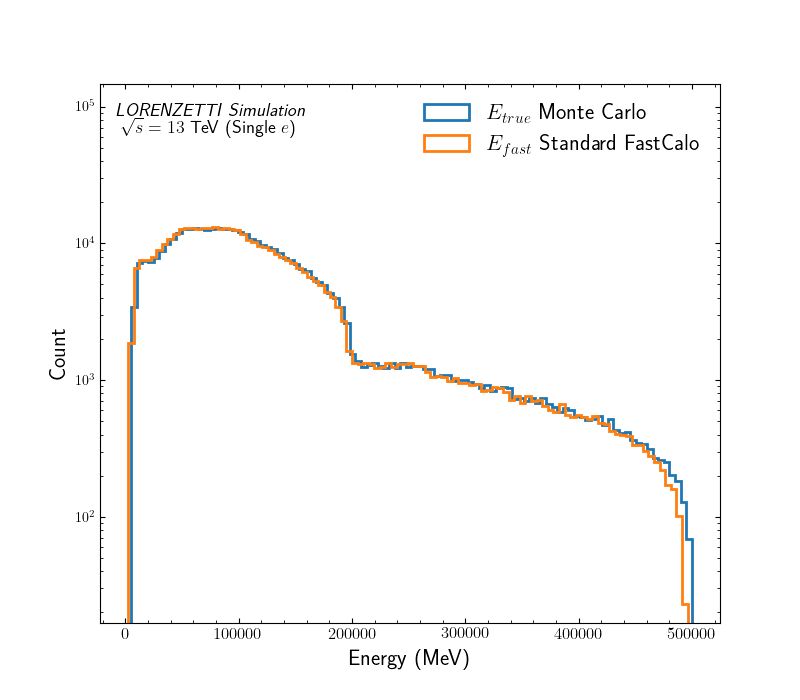

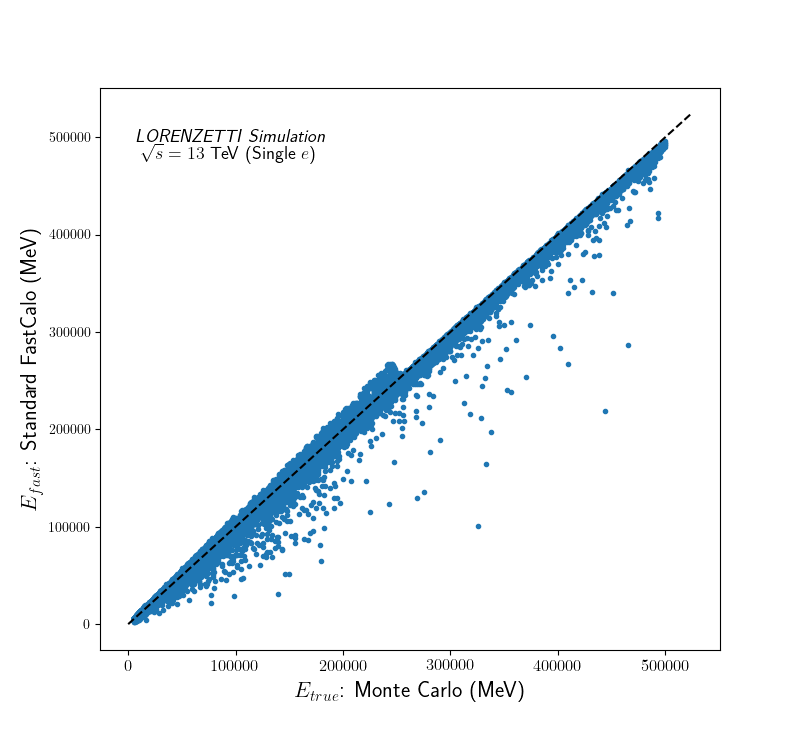

### Figure 6 — Standardized error and distribution goodness-of-fit

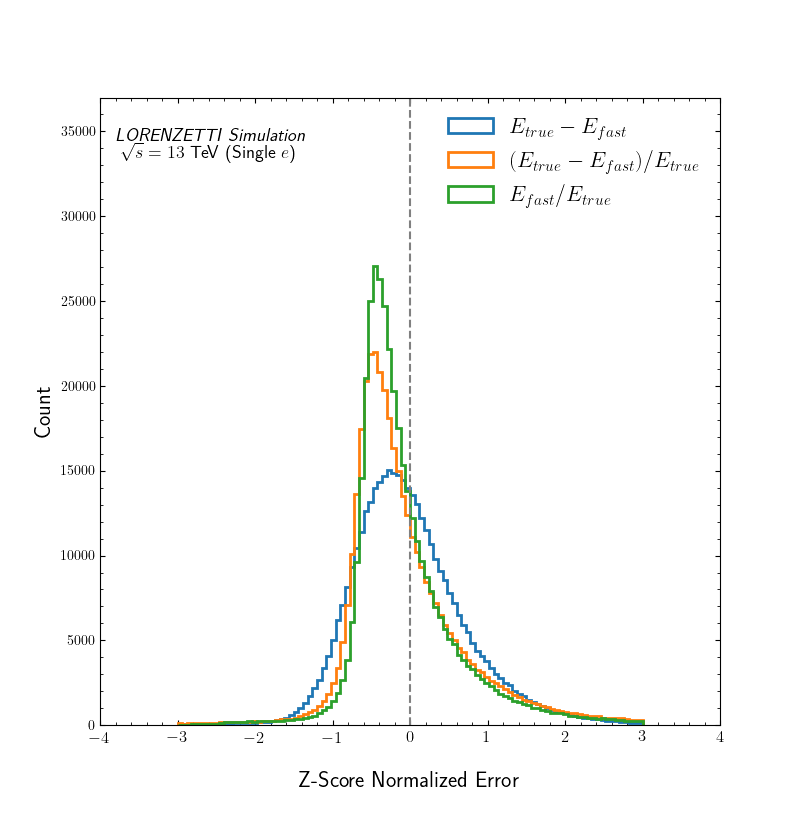

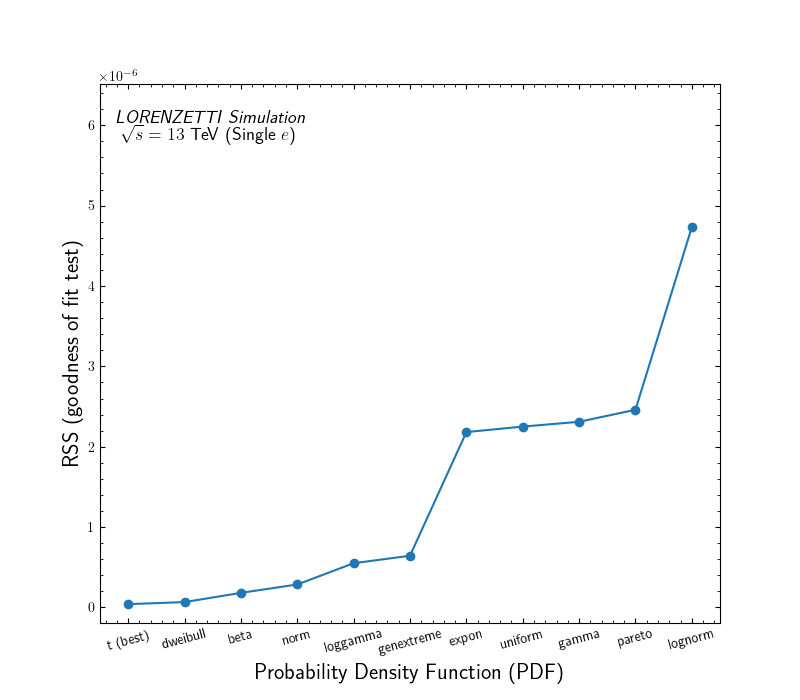

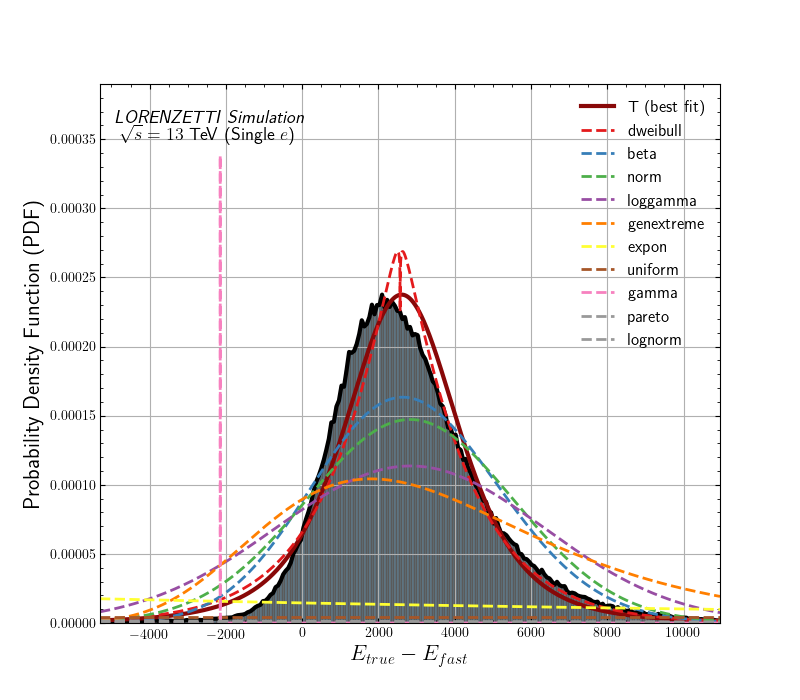

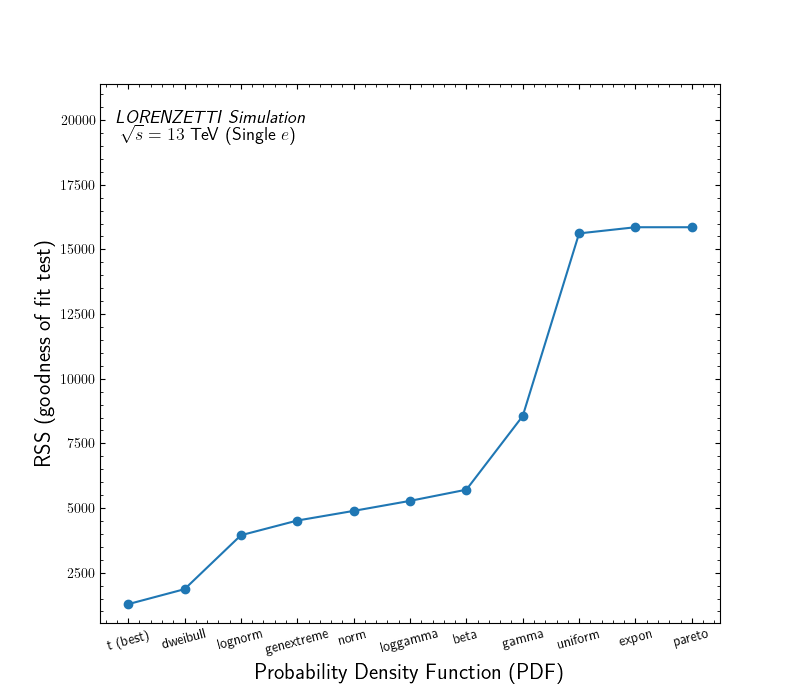

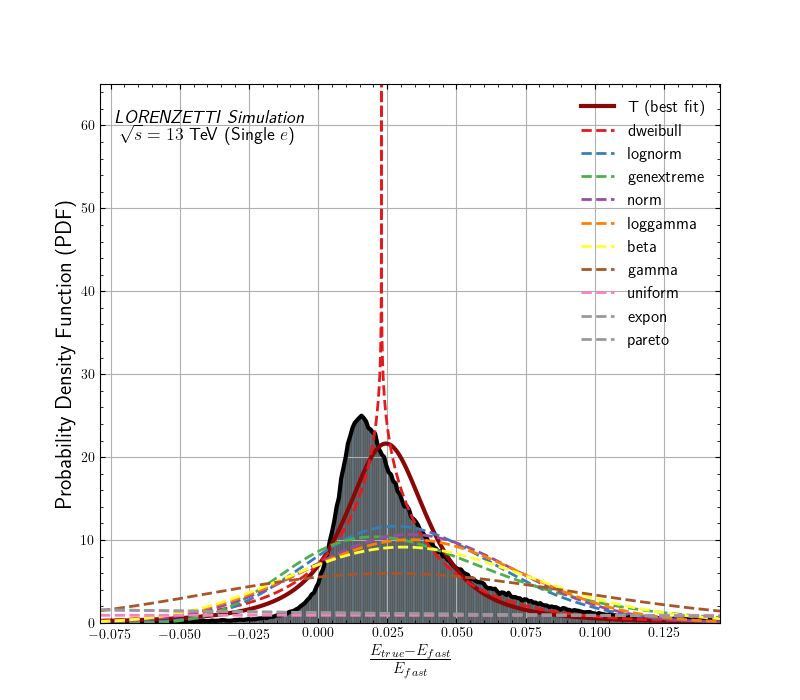

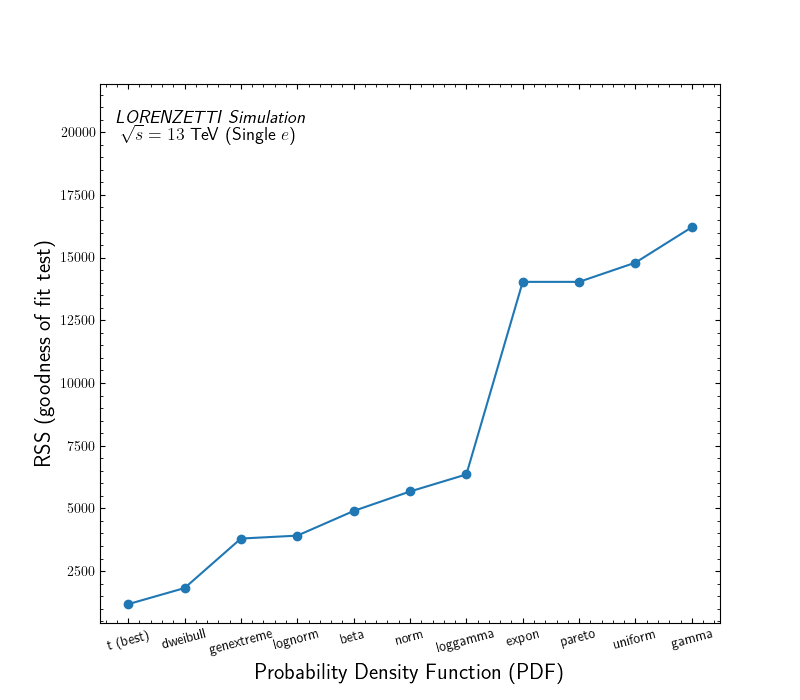

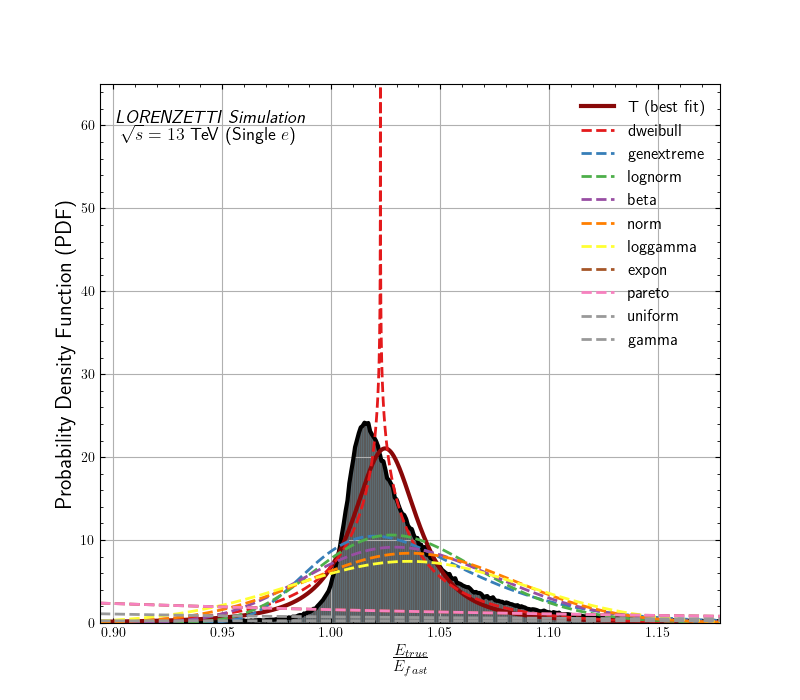

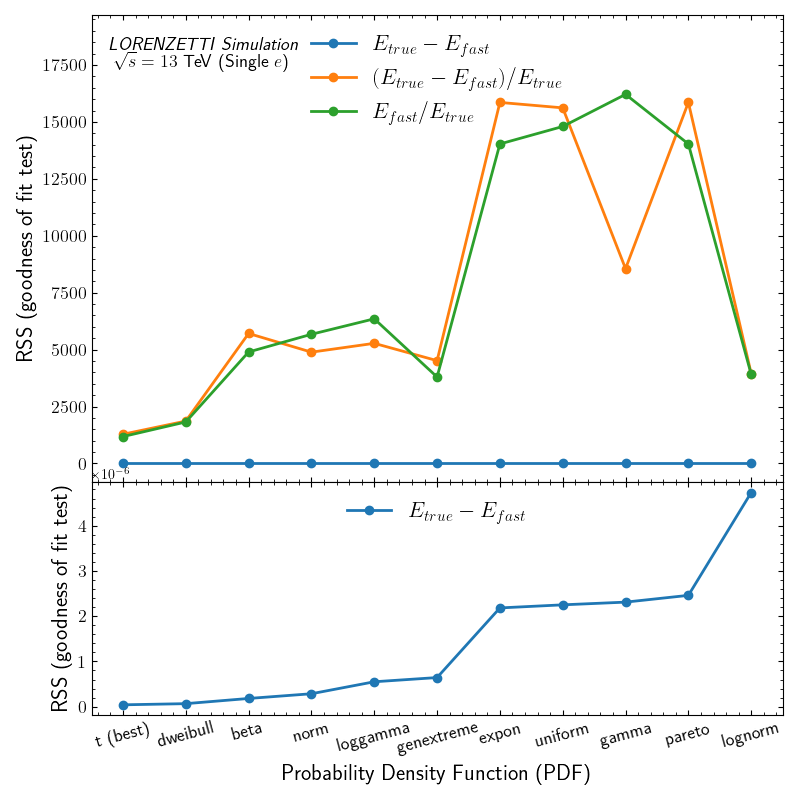

### Figure 7 — True calibration factor vs eta and ET

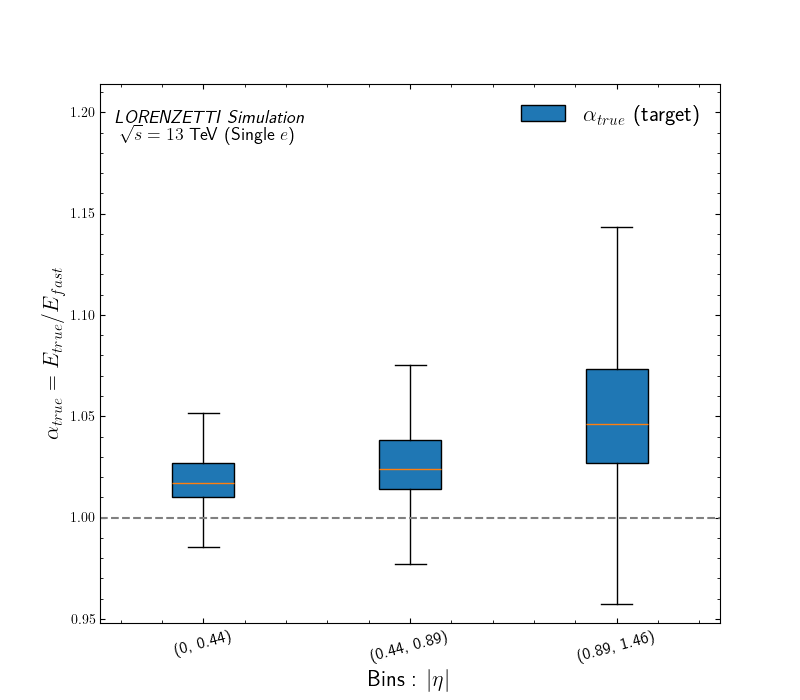

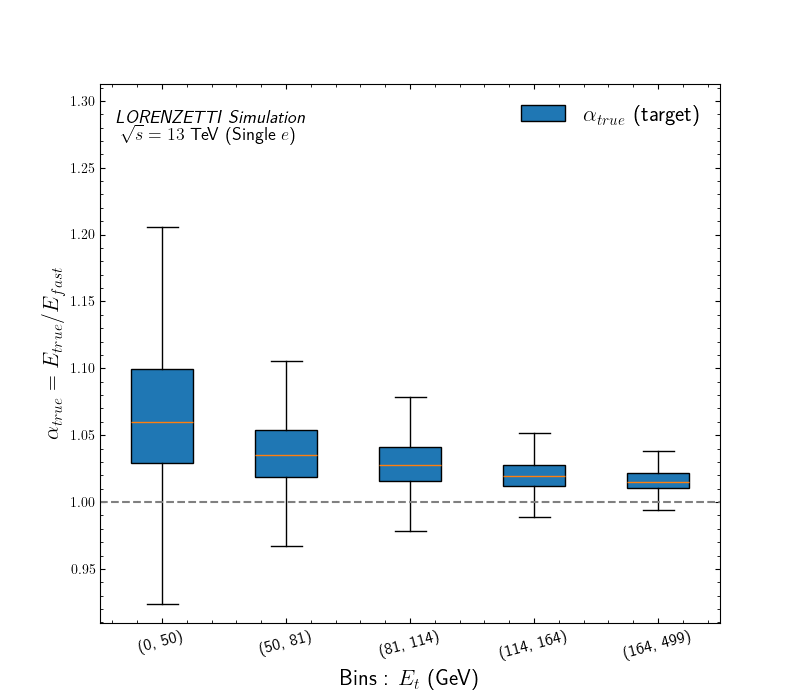

### Figure 8 — 100 ring distributions

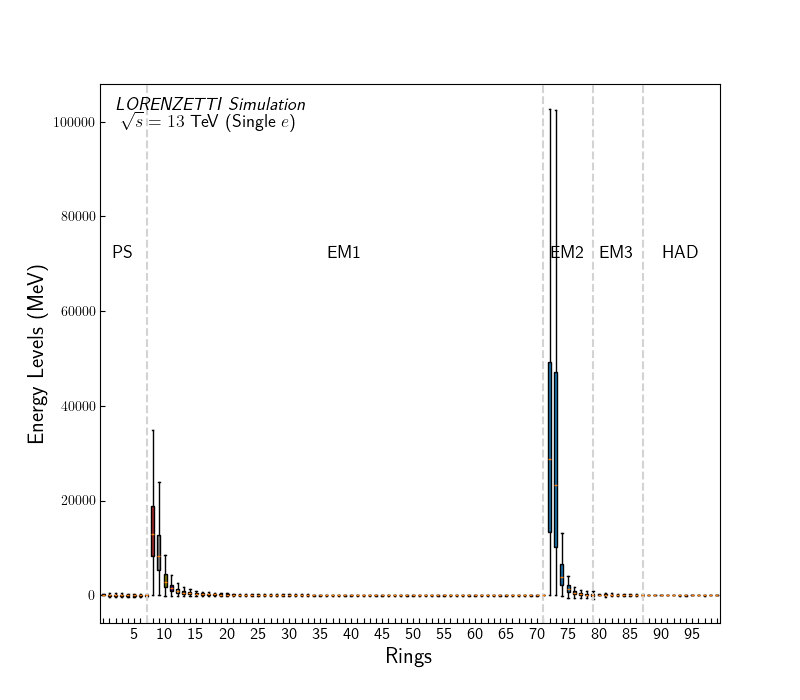

### Figure 9 — CORR, MI, PCA and ICA feature map

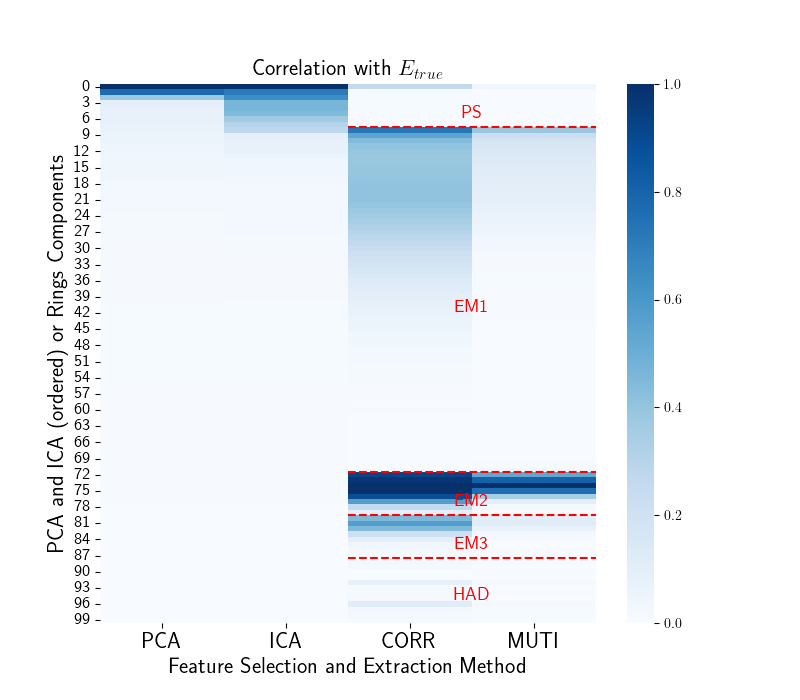

### Figure 10 — Calibration residual distributions by representation

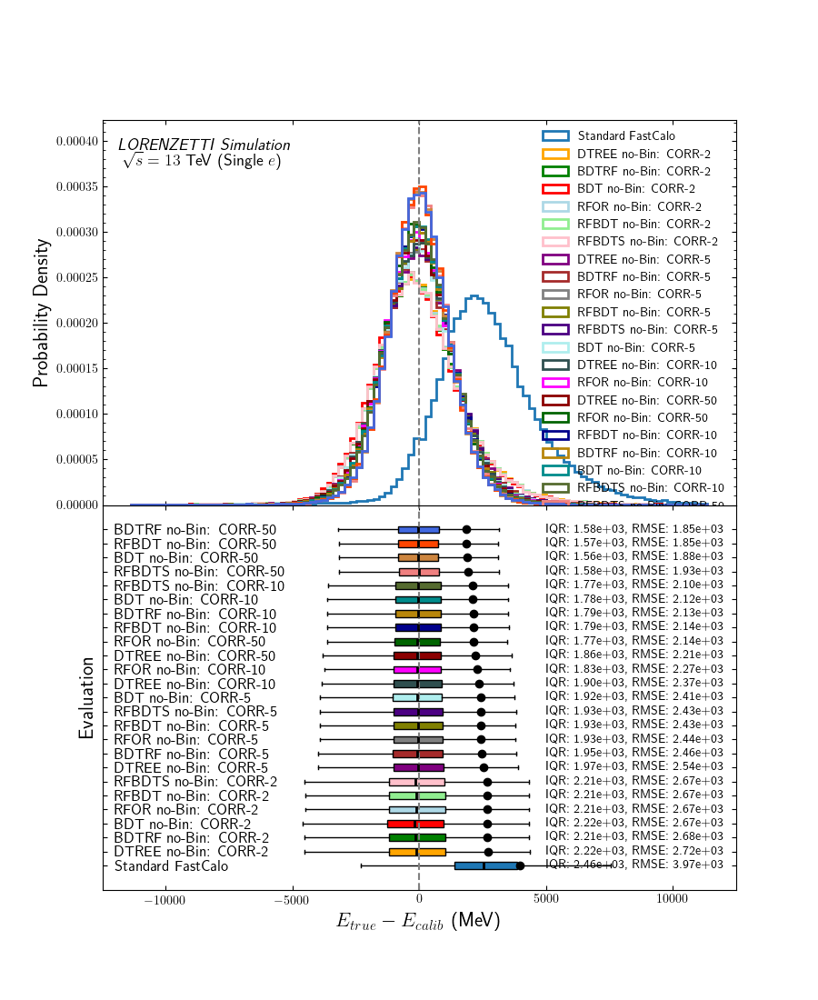

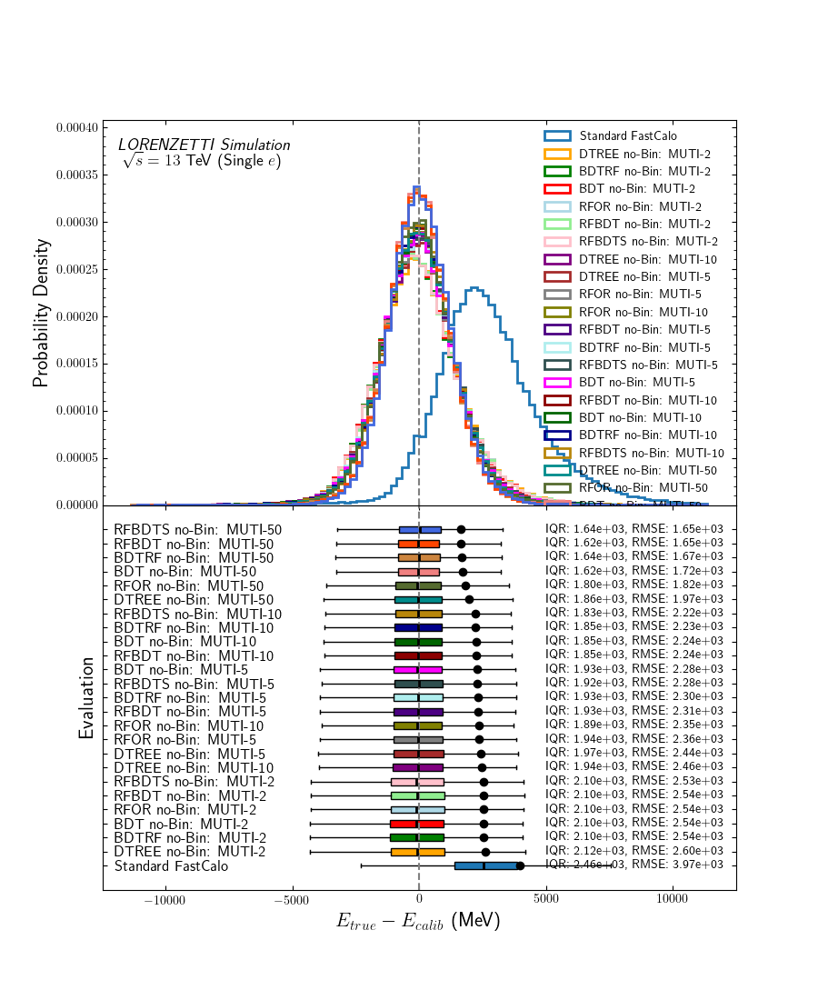

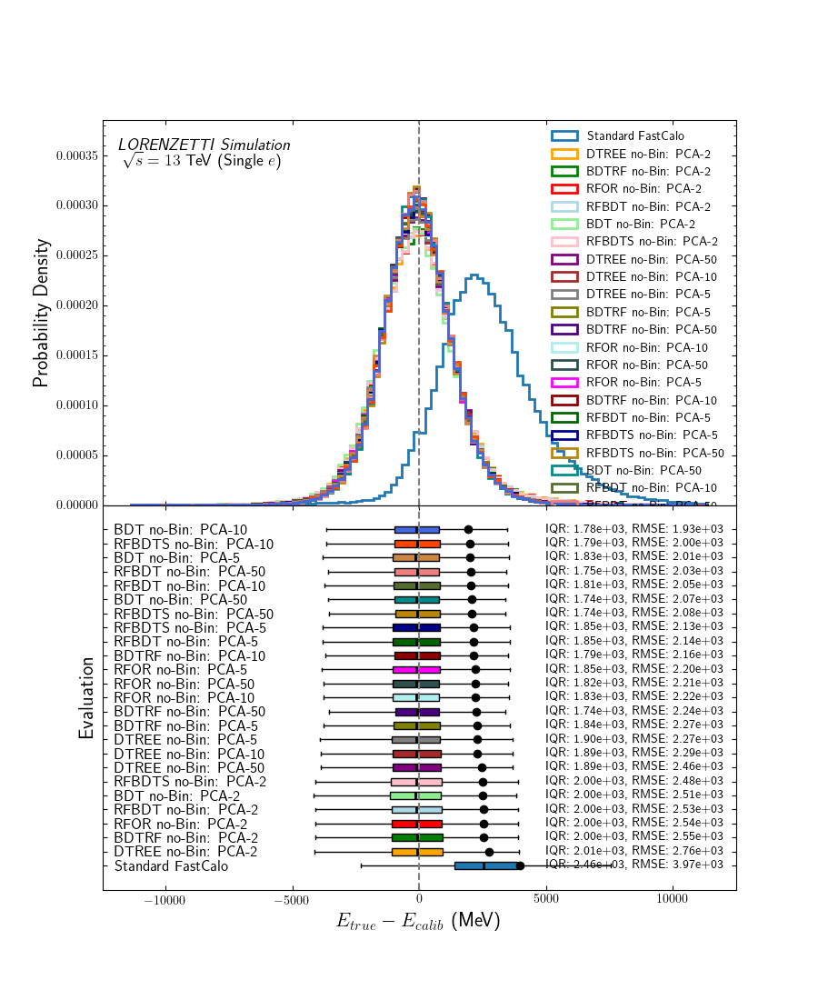

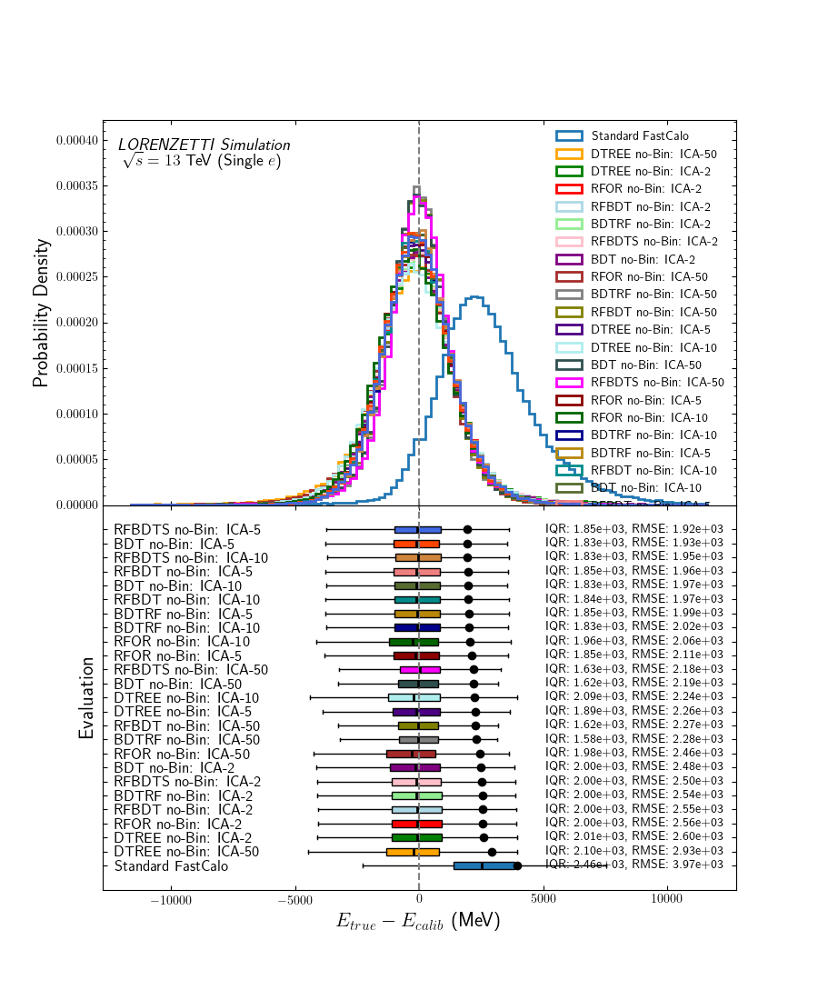

### Figure 11 — Joint error and complexity ranking

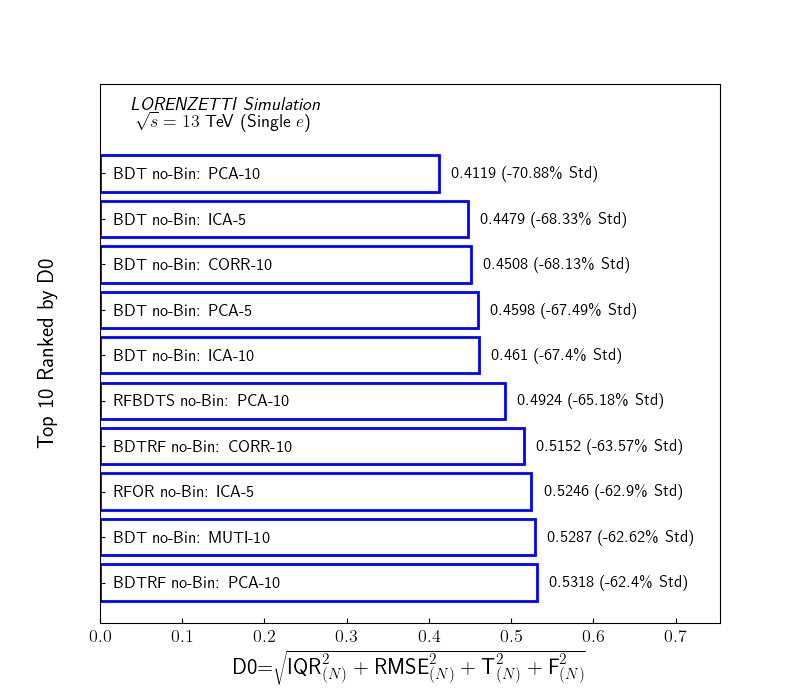

### Figure 12 — IQR in eta and energy regions

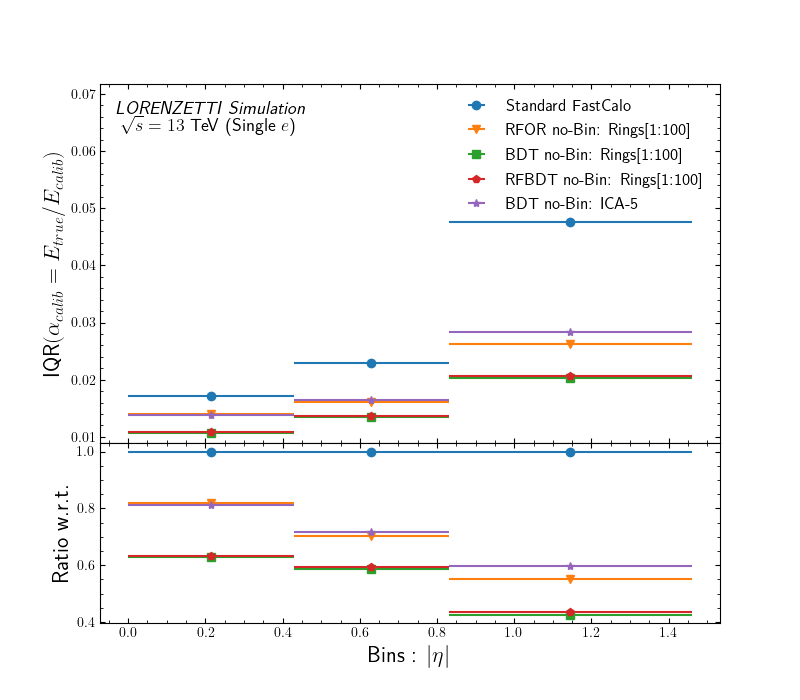

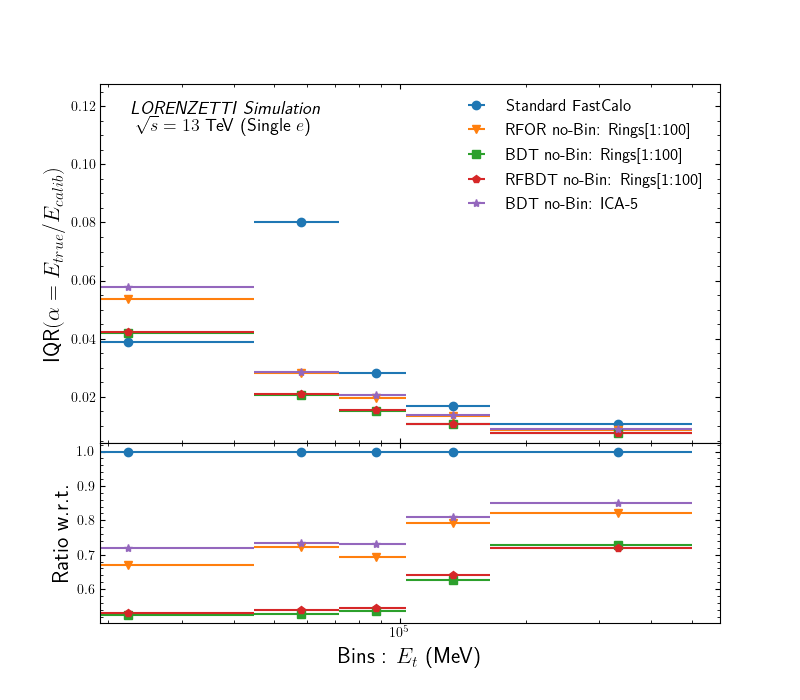

### Figure 13 — MAE and RMSE in eta and energy regions

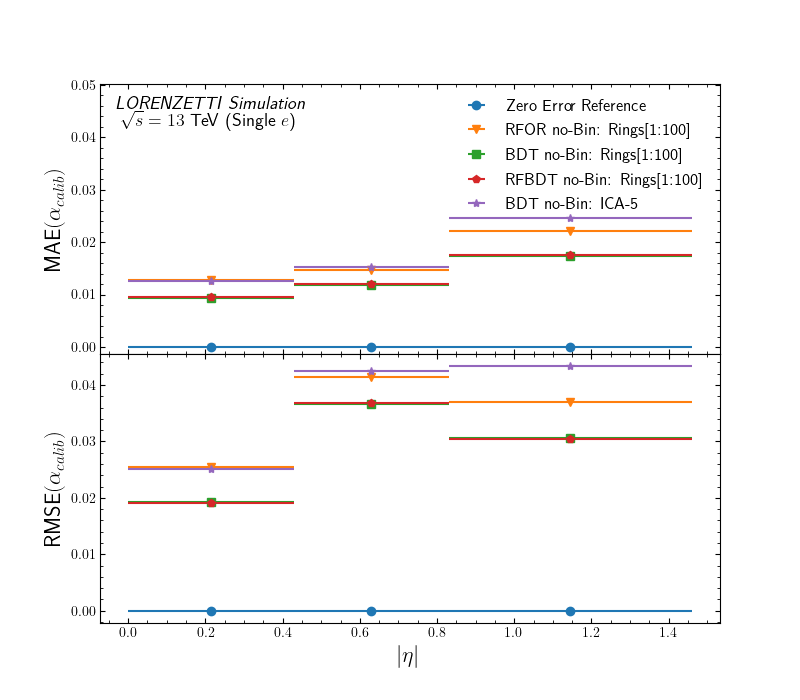

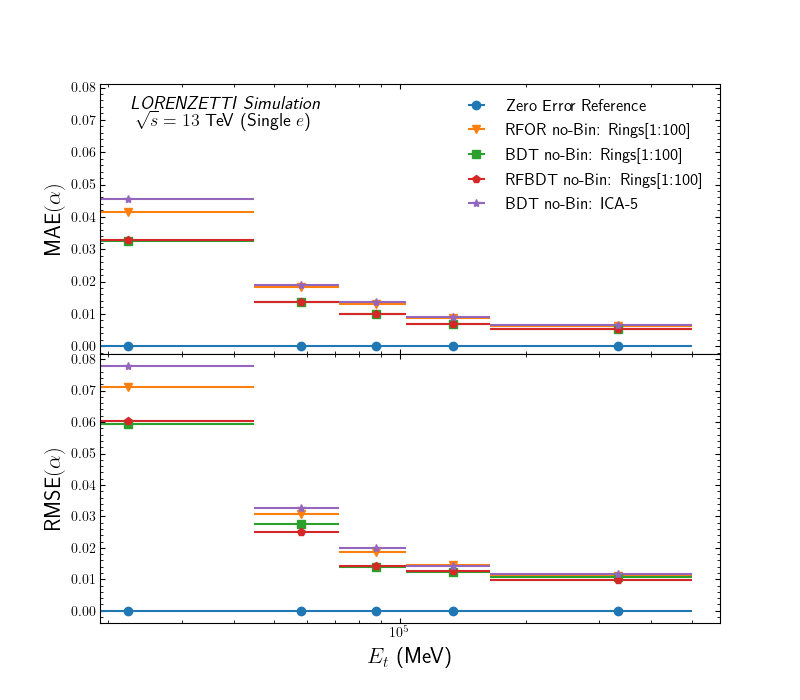

### Figure 14 — Calibration-factor regional boxplots

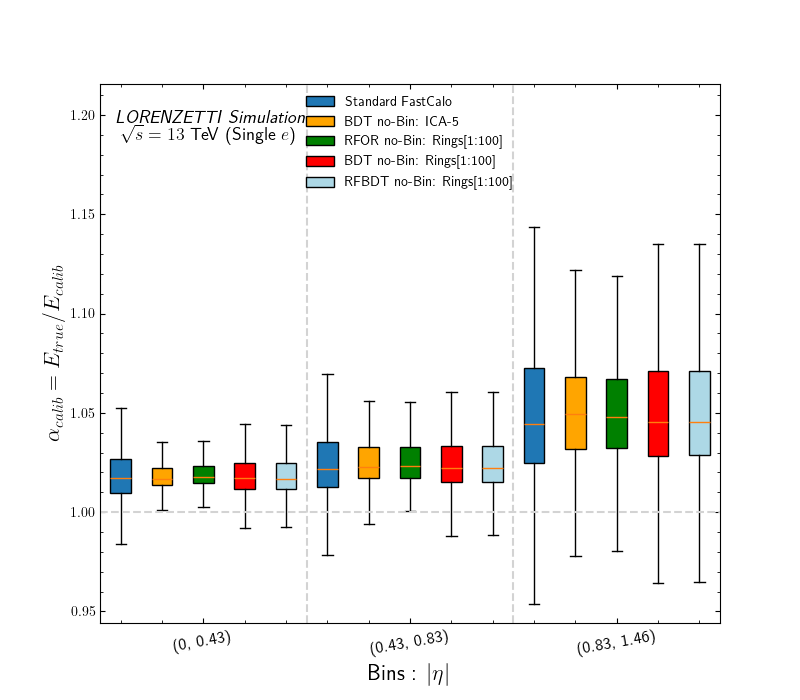

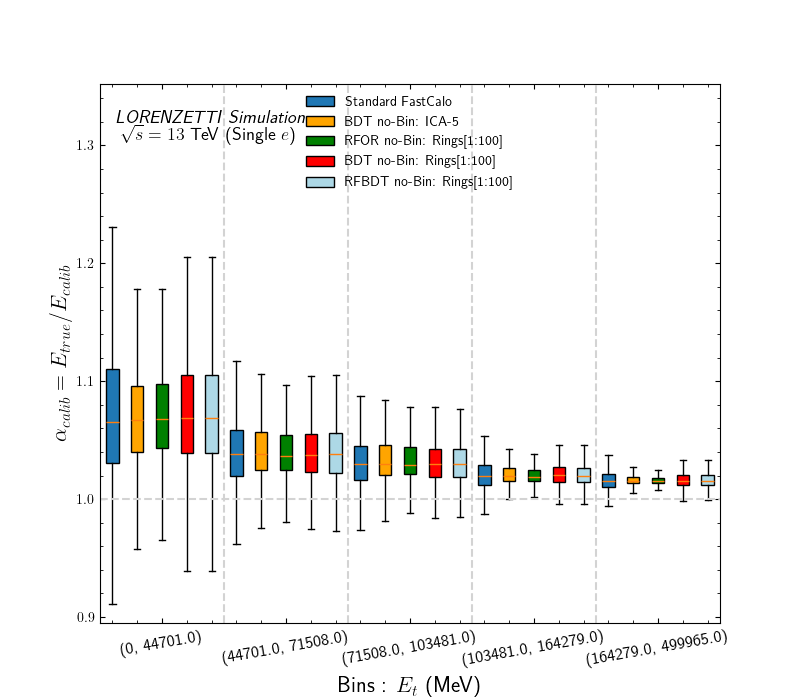

### Figure 15 — Relative energy resolution curves

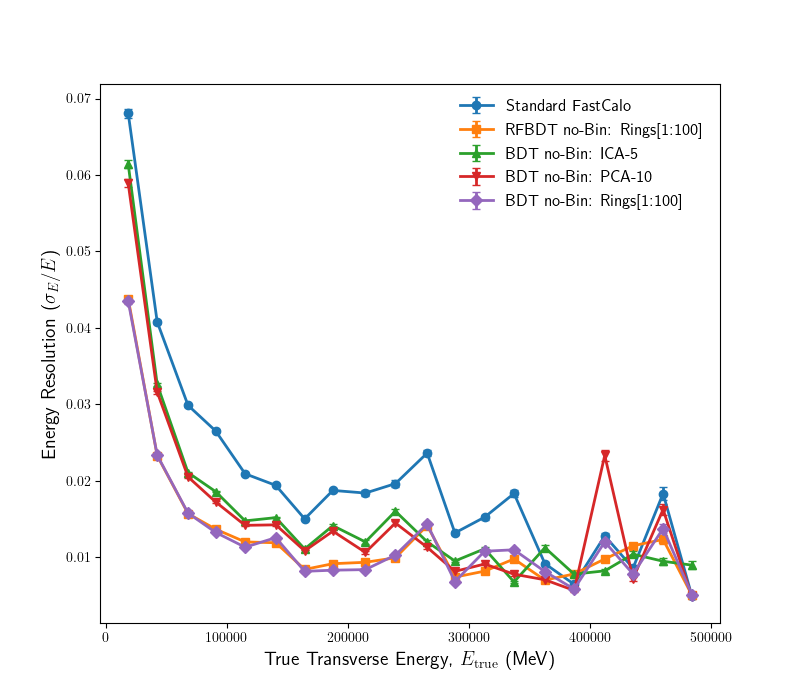

### Figure 16 — Threshold acceptance curves

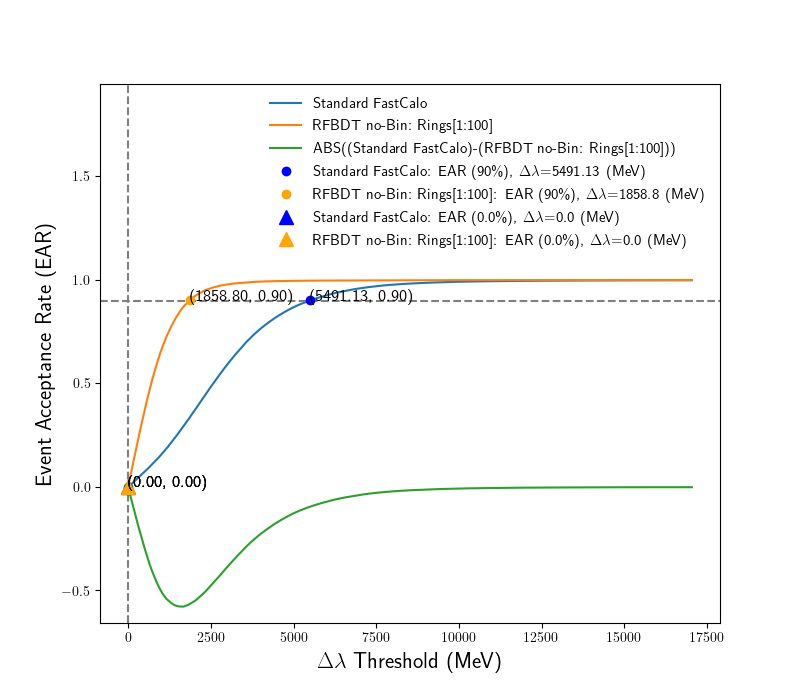

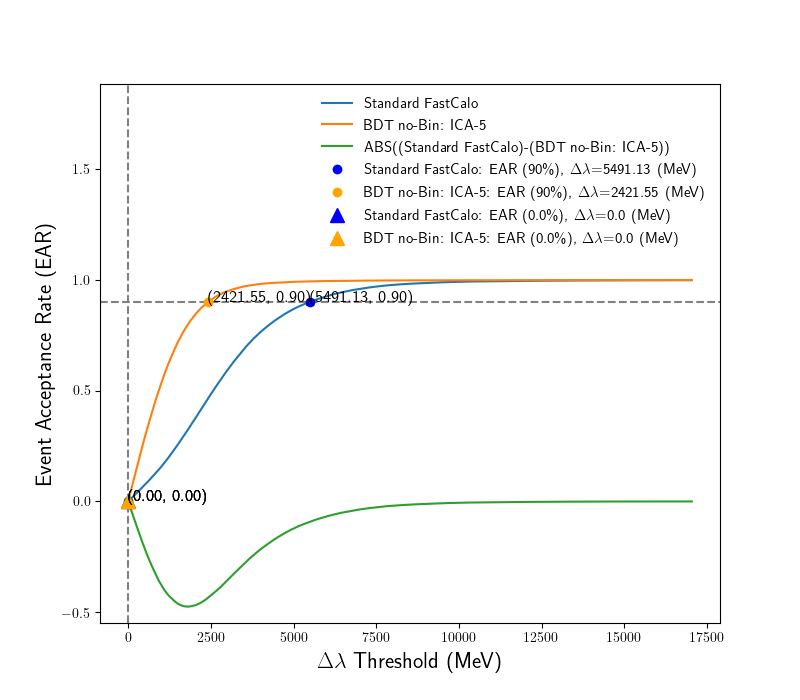

### Figure 17 — Fast versus calibrated energy scatter

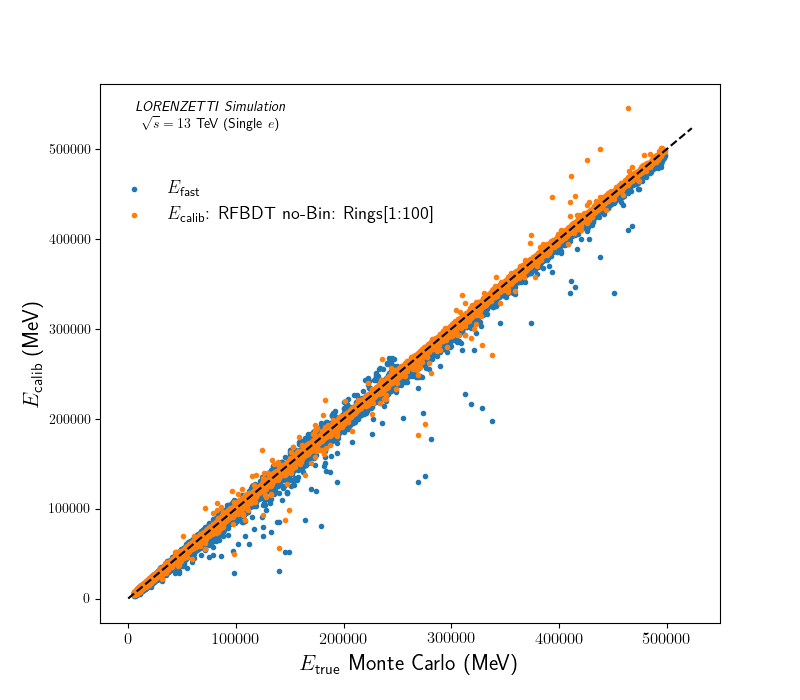

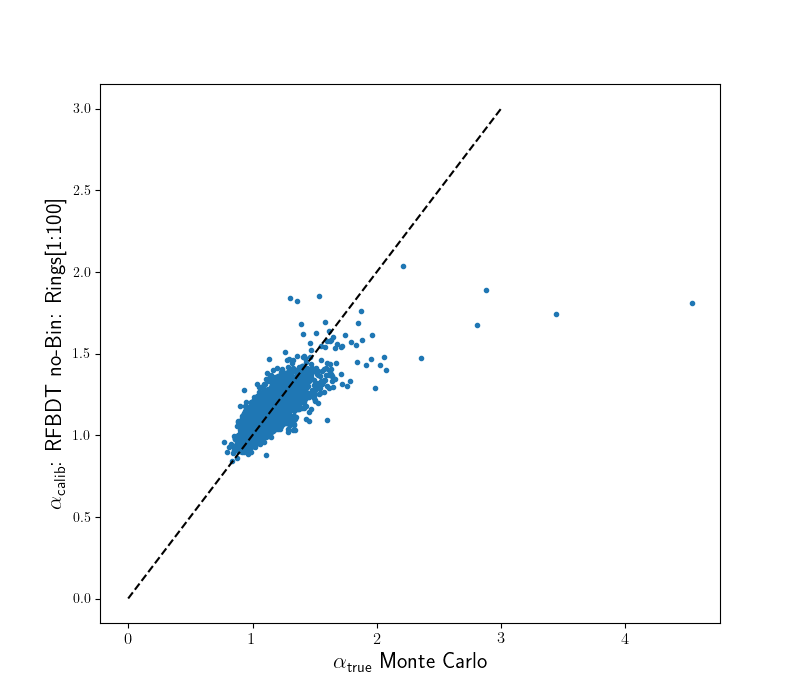

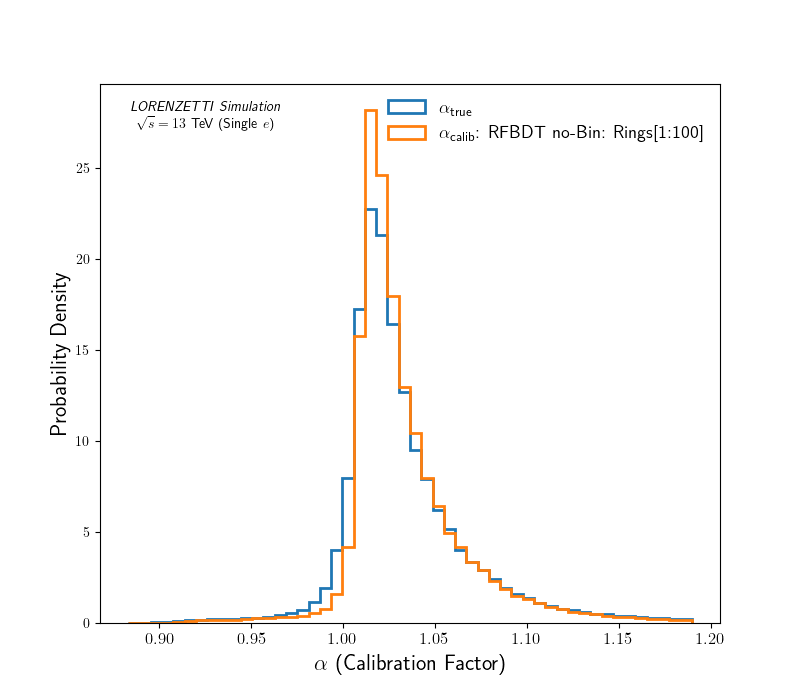

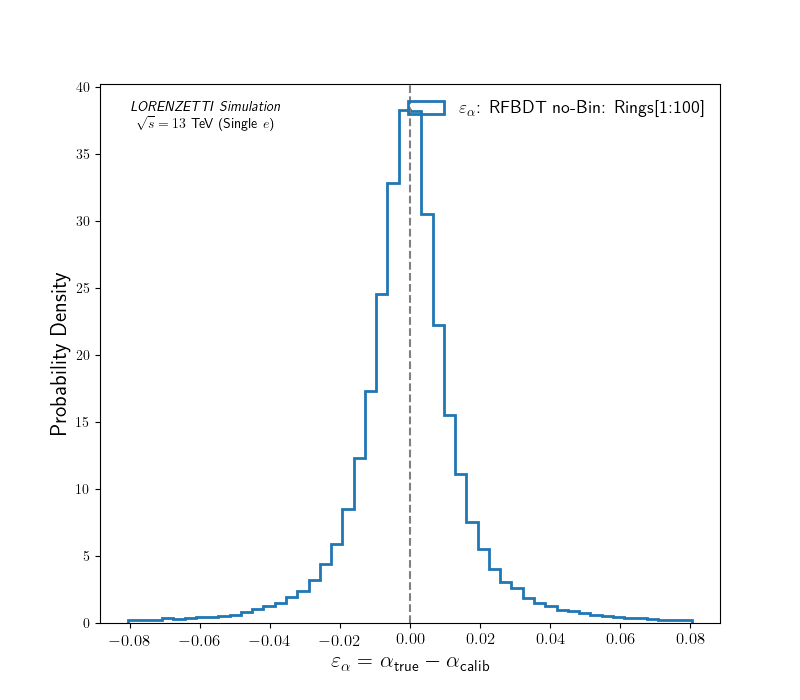

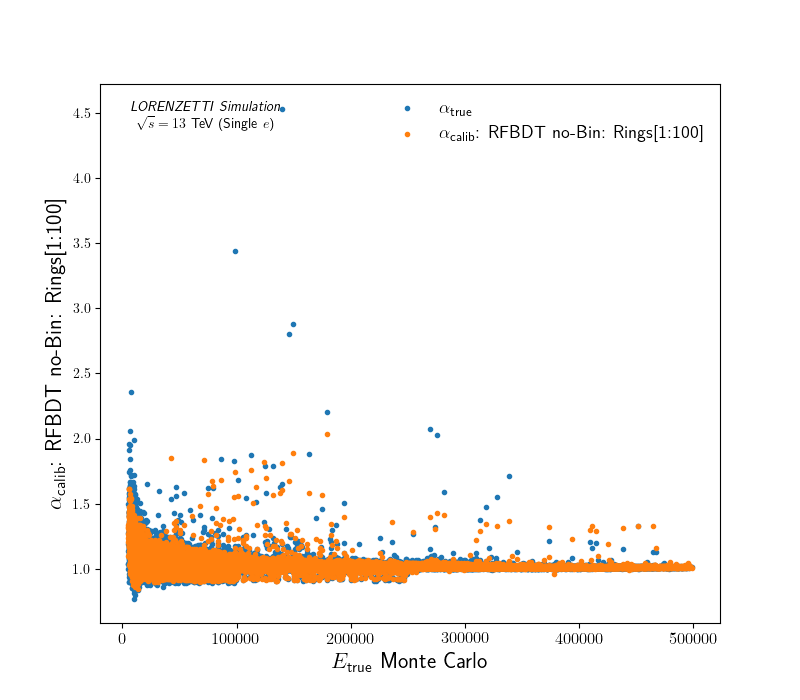

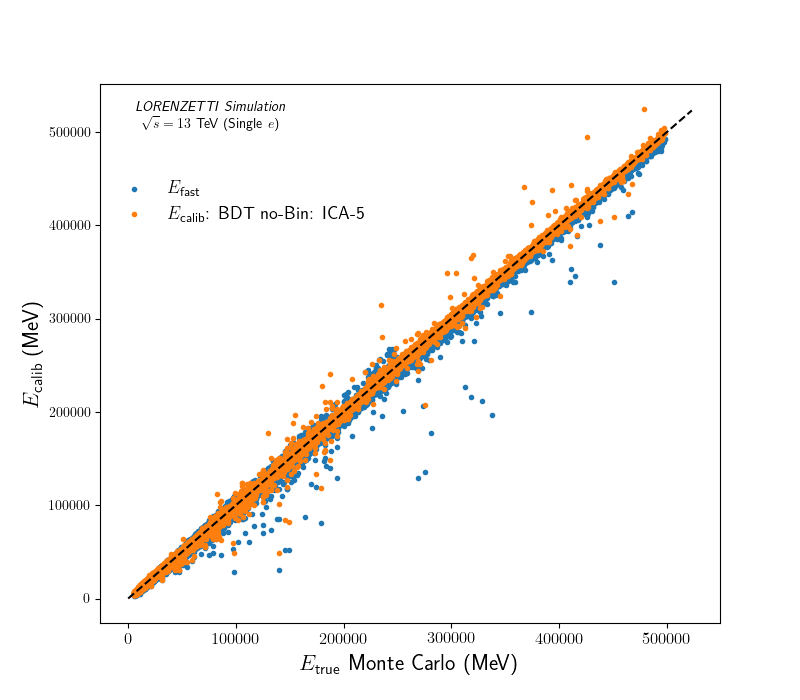

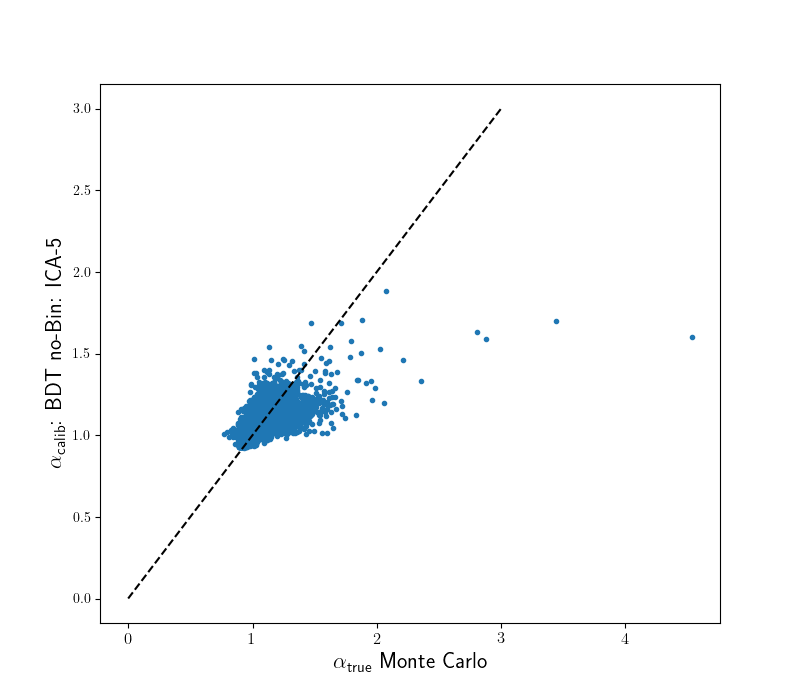

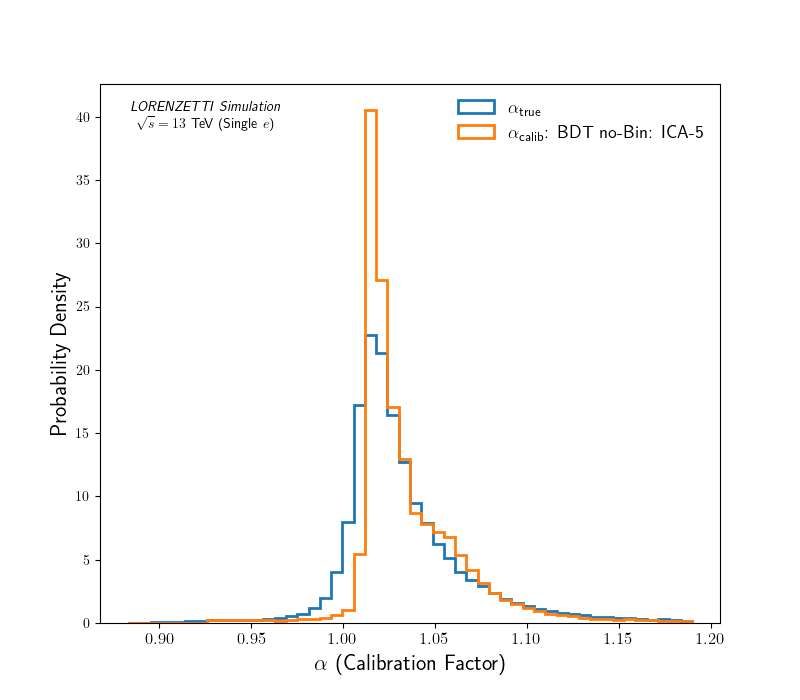

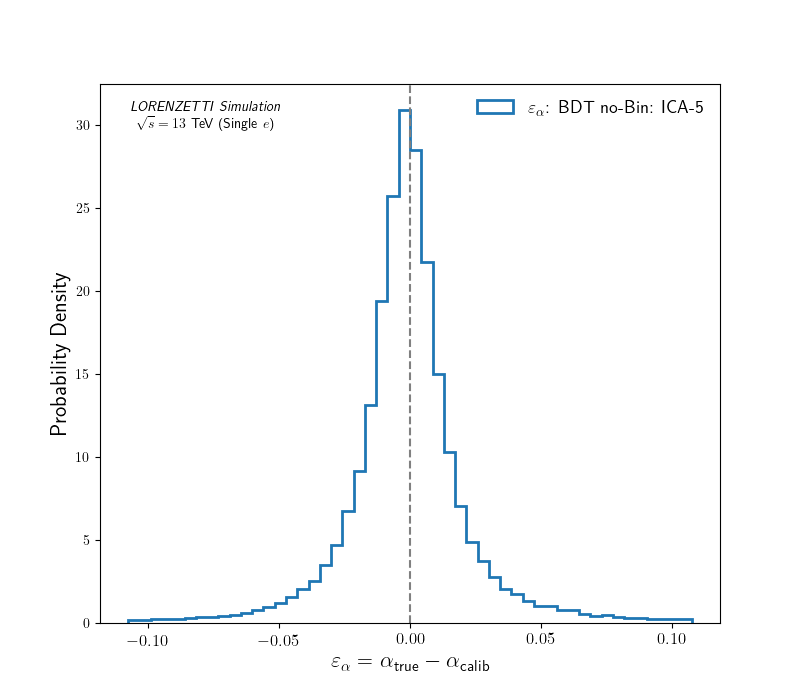

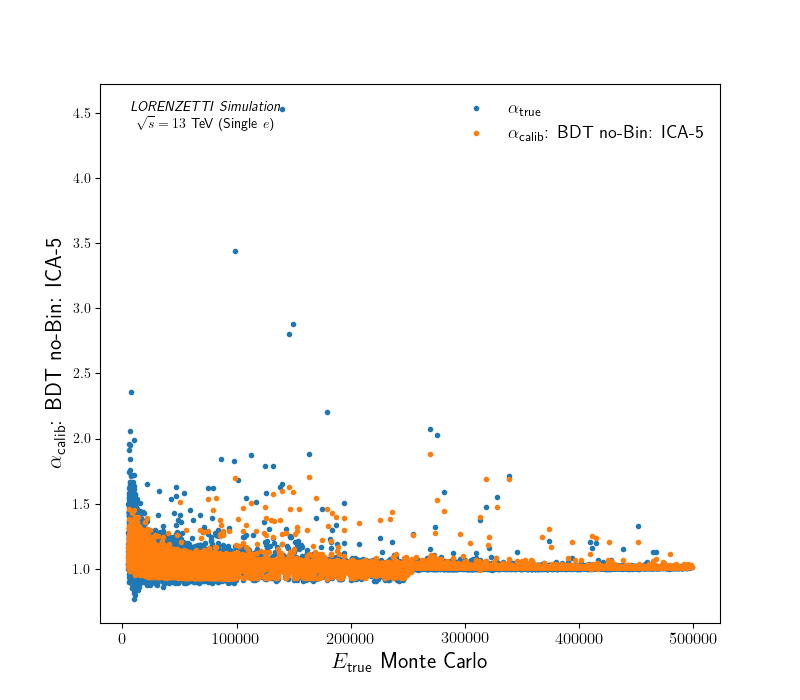

### Figure 18 — Compact performance summary

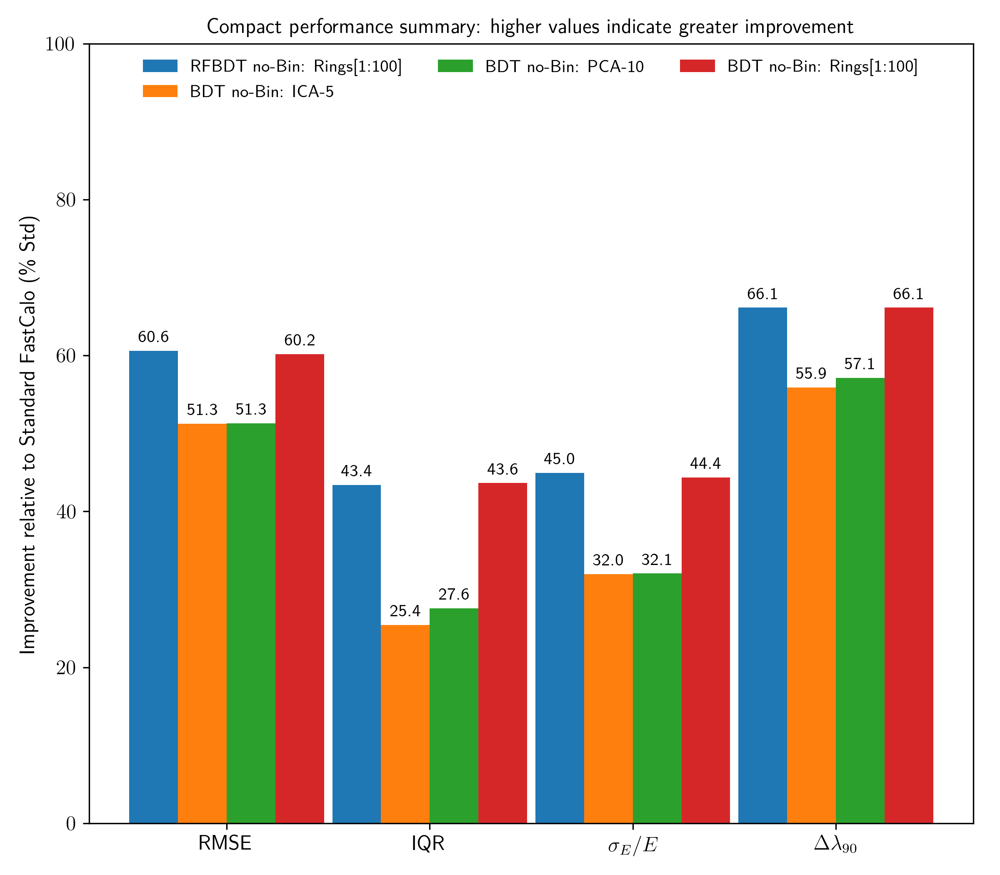

### Figure 19 — Accuracy and efficiency trade-off

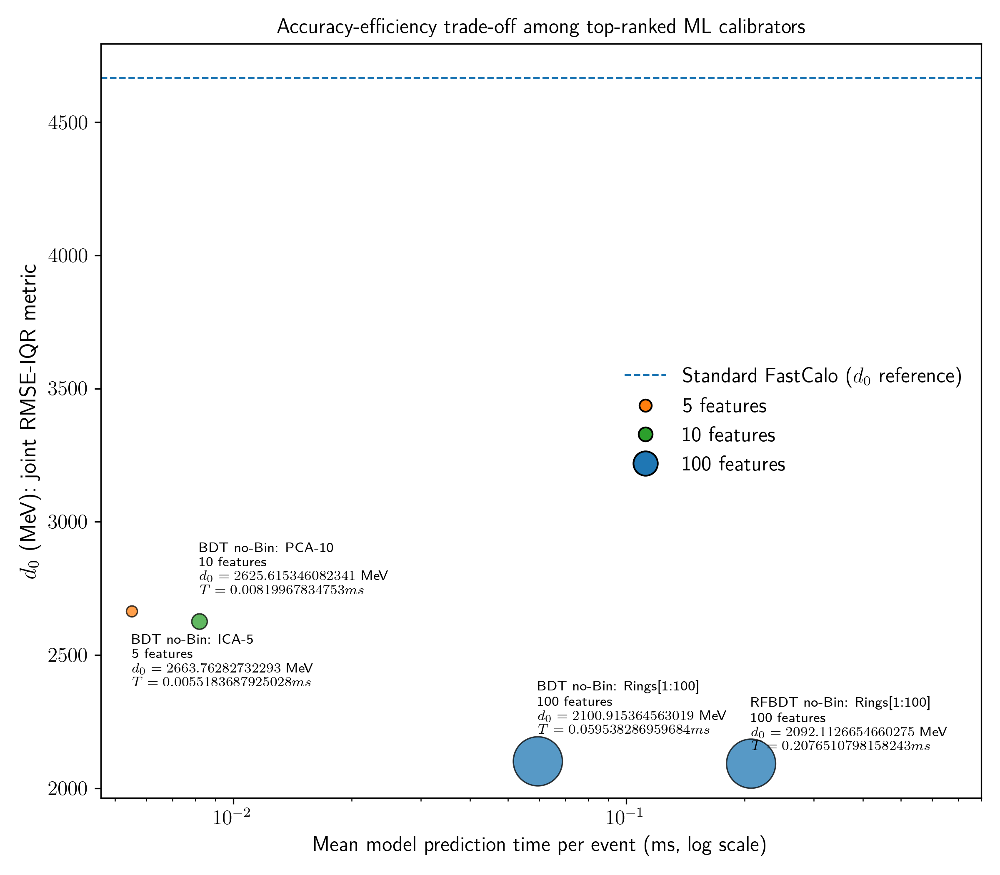

### Figure 20 — Error normal Q-Q comparison

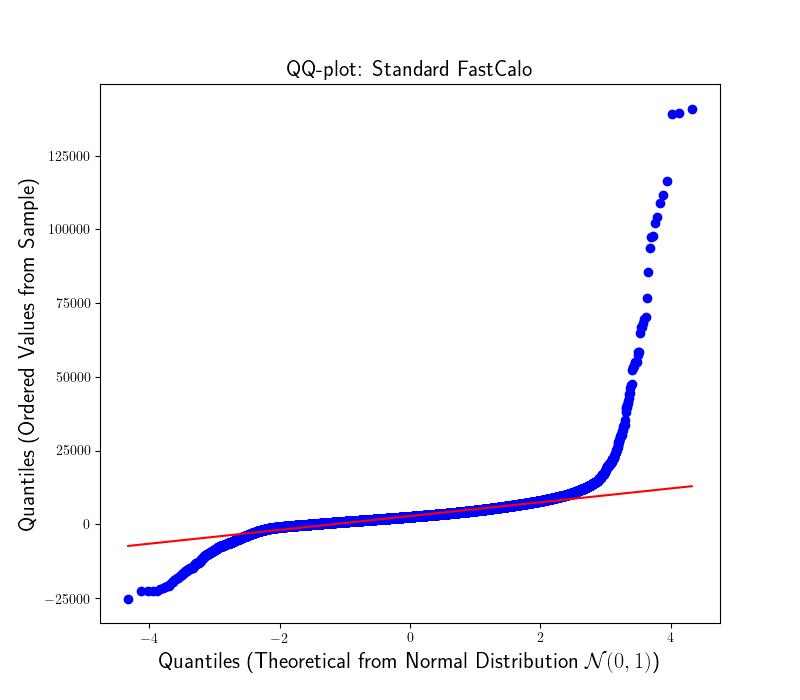

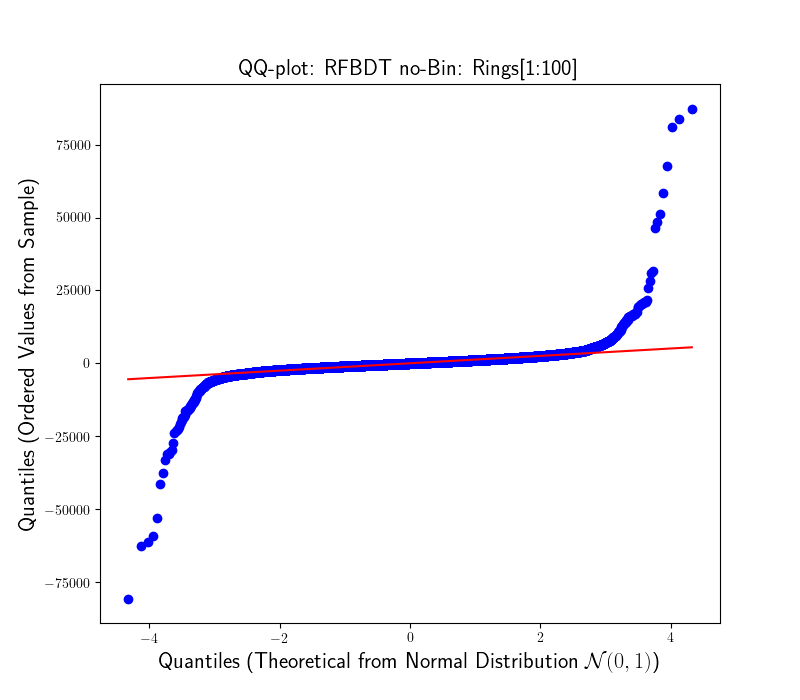

### Additional archived configurations

original_resolution_01.png


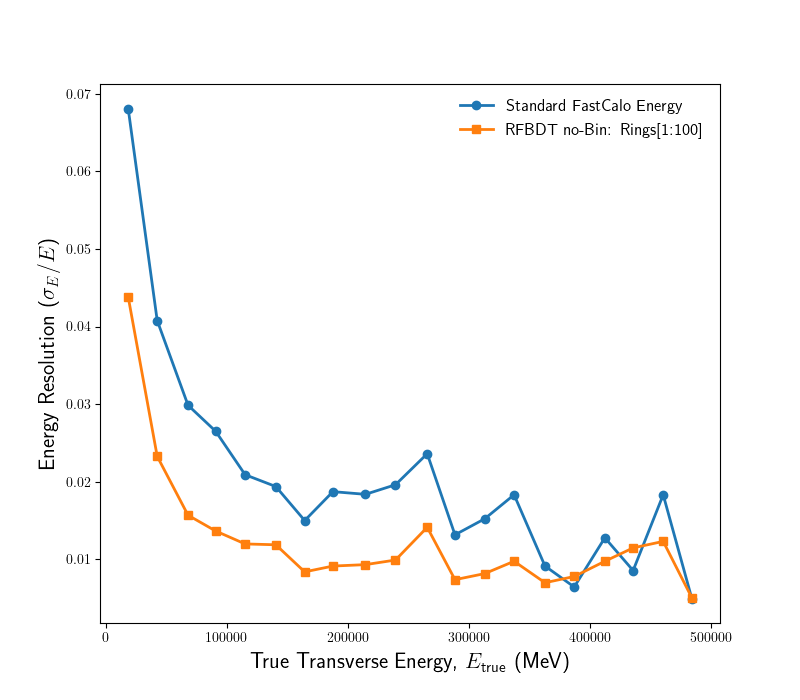

original_resolution_comparison_01_01.png


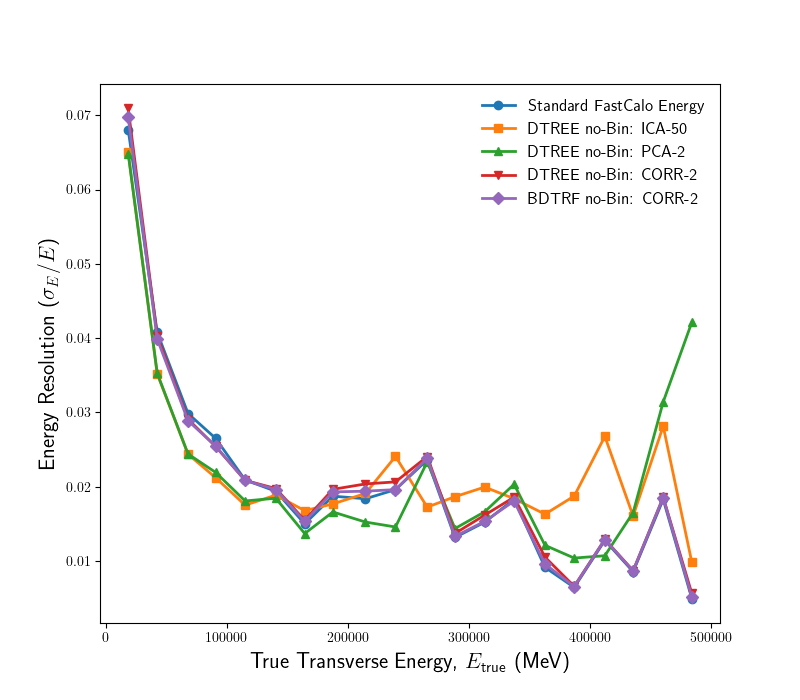

original_resolution_comparison_02_01.png


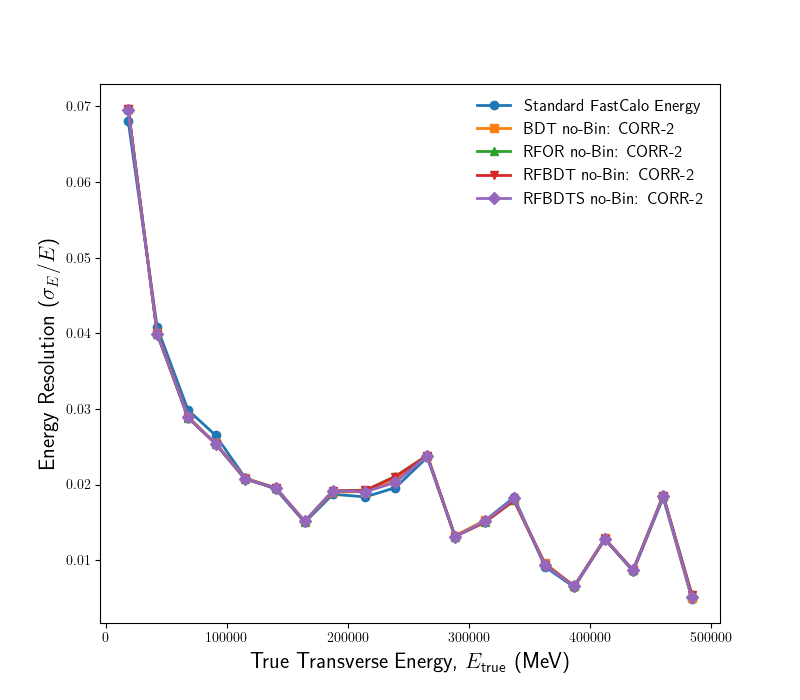

original_resolution_comparison_03_01.png


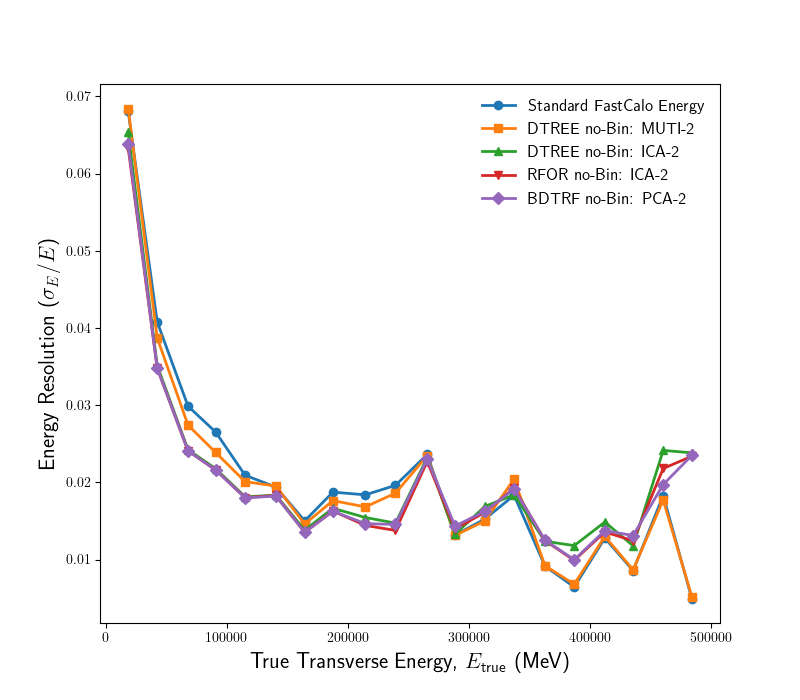

original_resolution_comparison_04_01.png


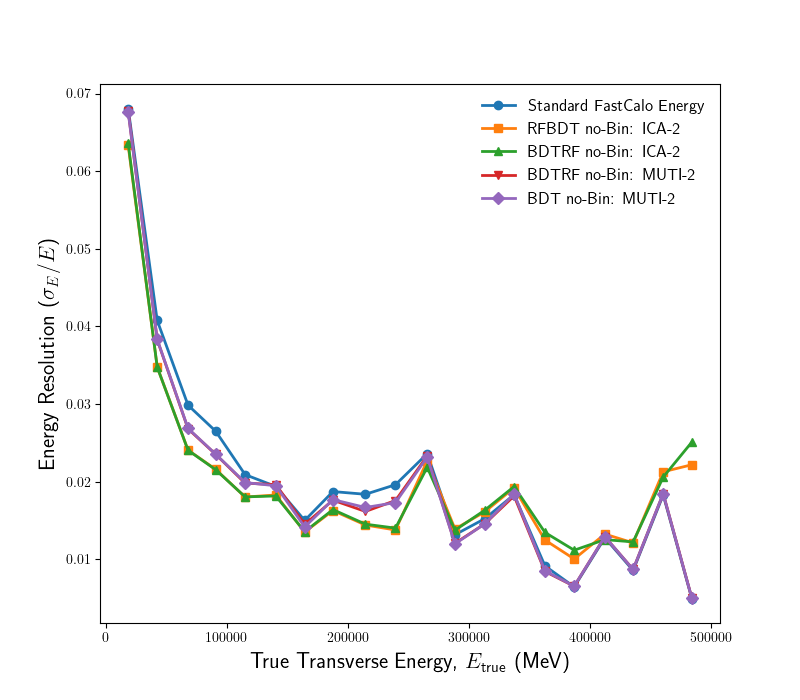

original_resolution_comparison_05_01.png


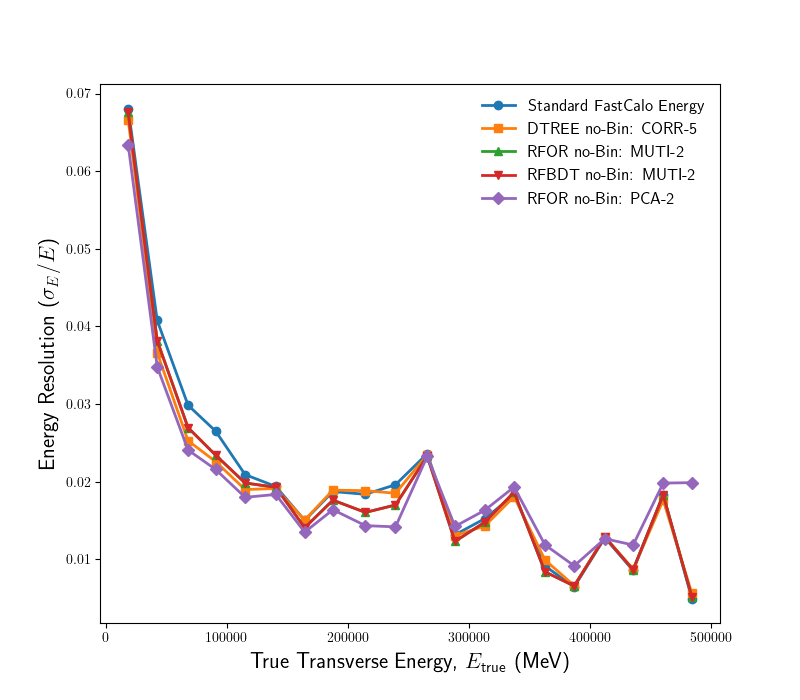

original_resolution_comparison_06_01.png


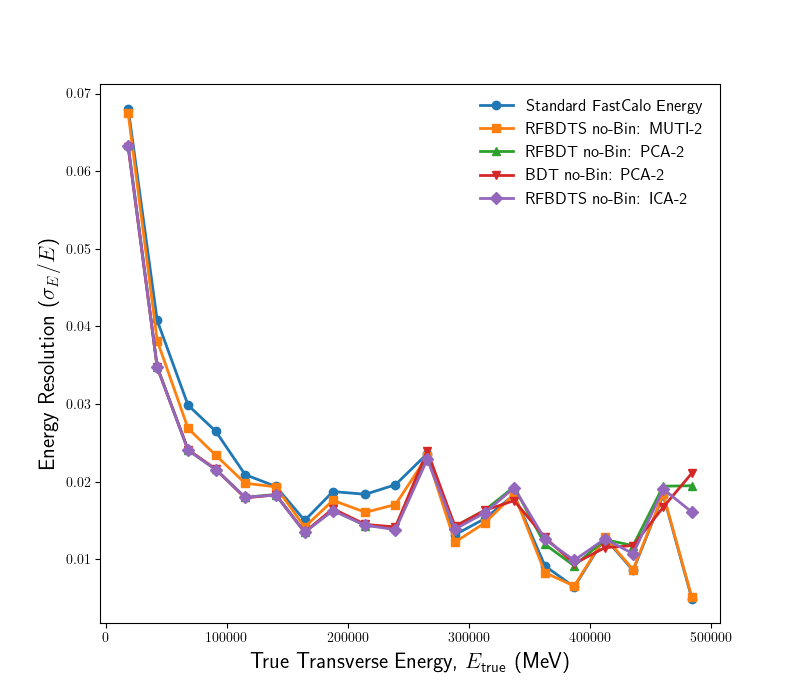

original_resolution_comparison_07_01.png


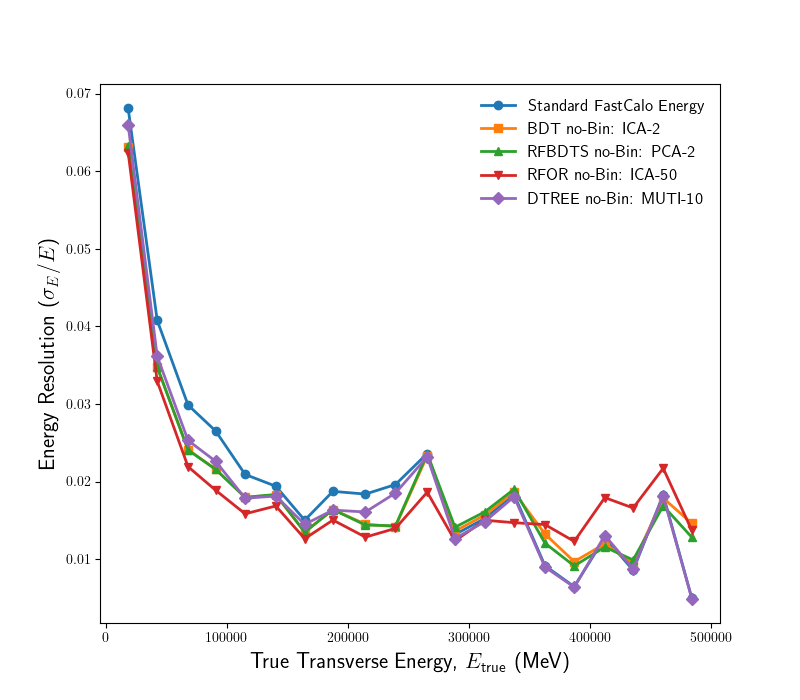

original_resolution_comparison_08_01.png


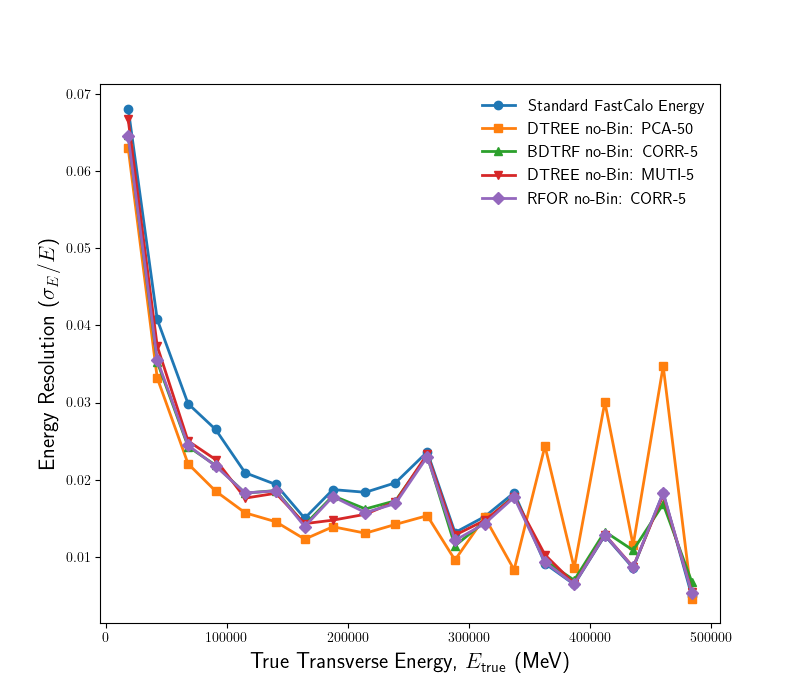

original_resolution_comparison_09_01.png


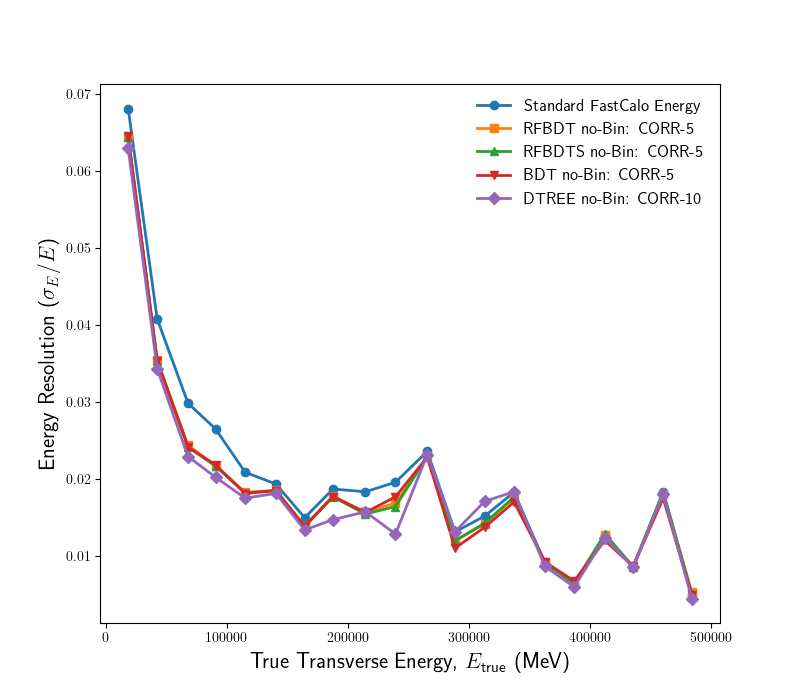

original_resolution_comparison_10_01.png


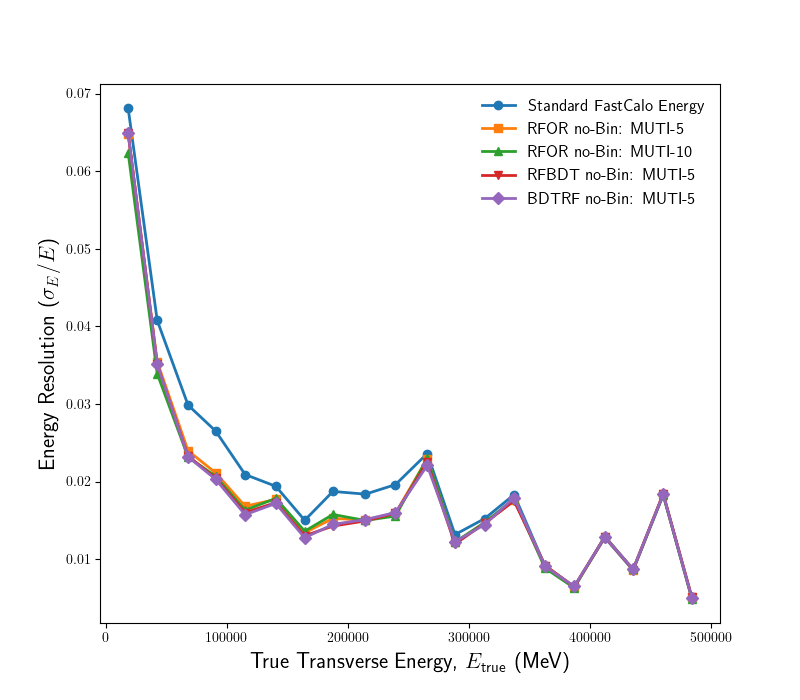

original_resolution_comparison_11_01.png


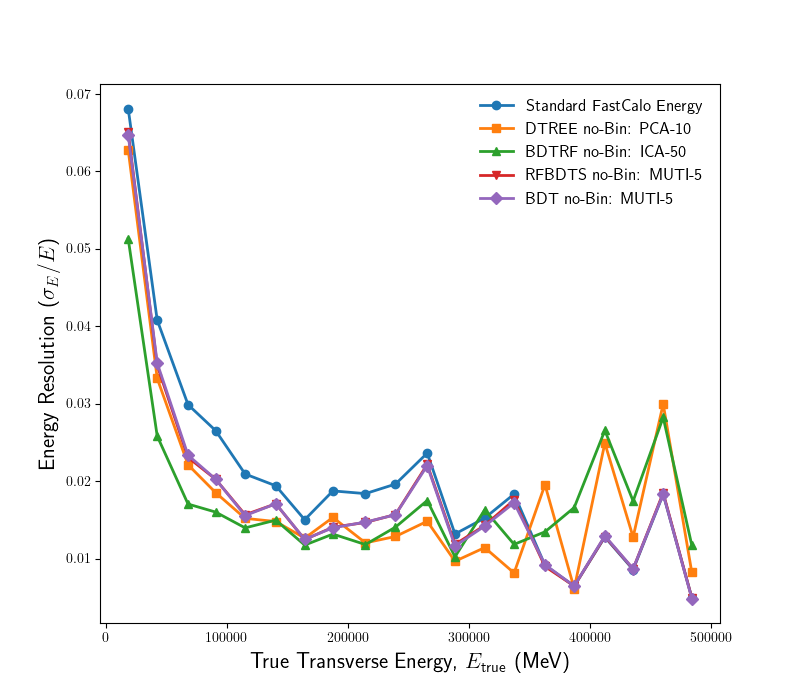

original_resolution_comparison_12_01.png


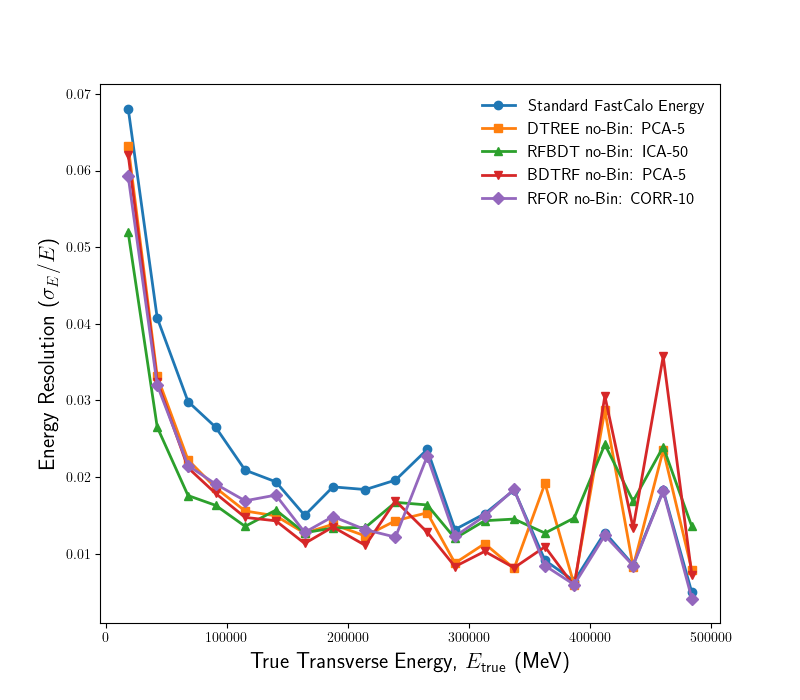

original_resolution_comparison_13_01.png


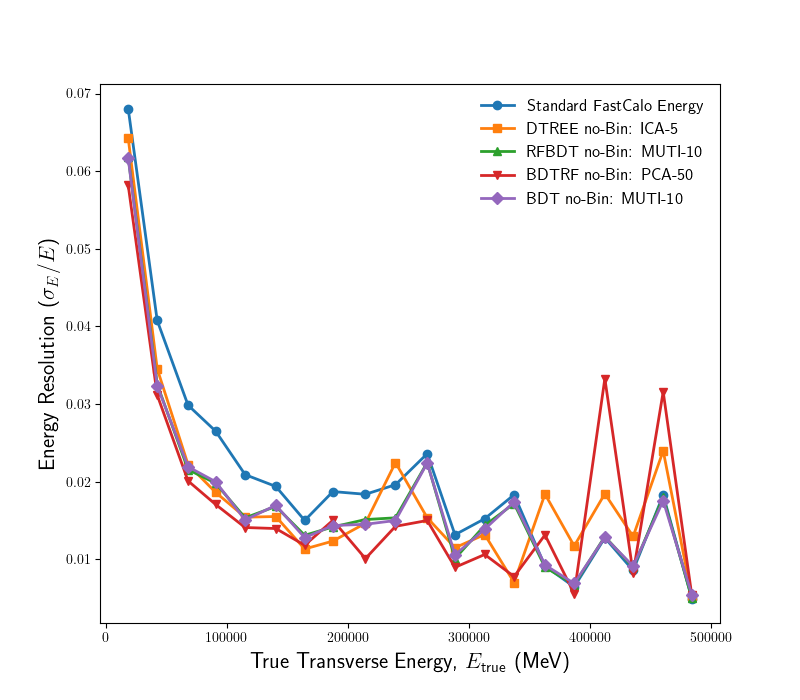

original_resolution_comparison_14_01.png


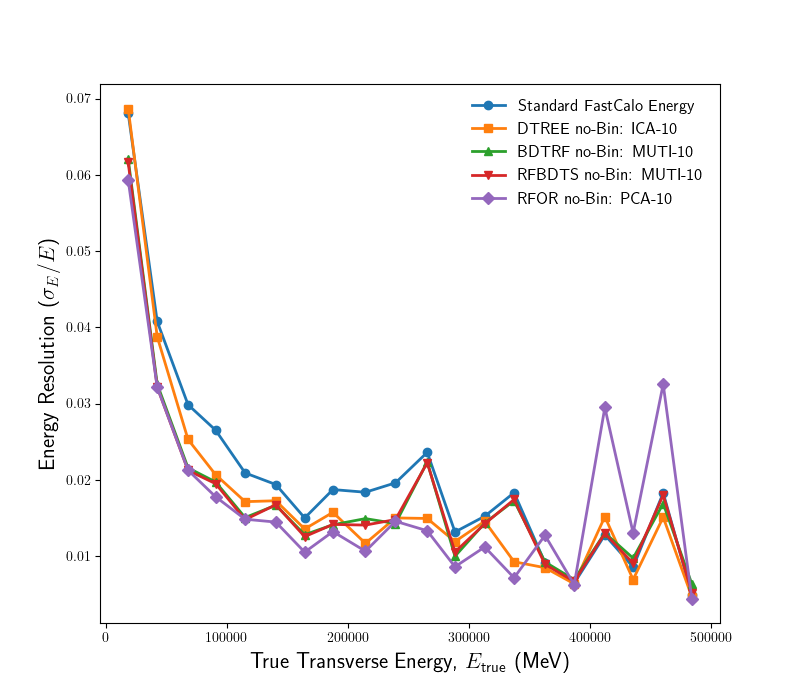

original_resolution_comparison_15_01.png


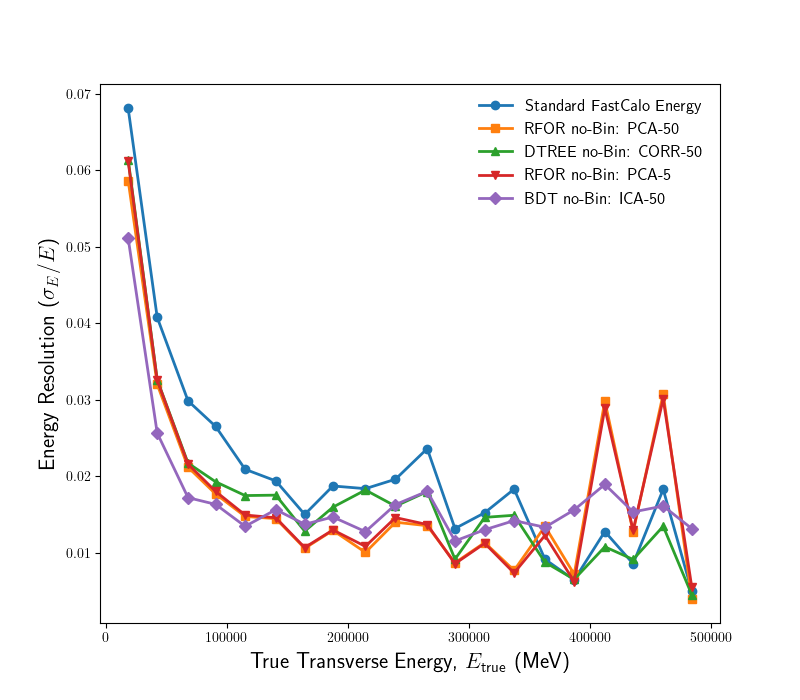

original_resolution_comparison_16_01.png


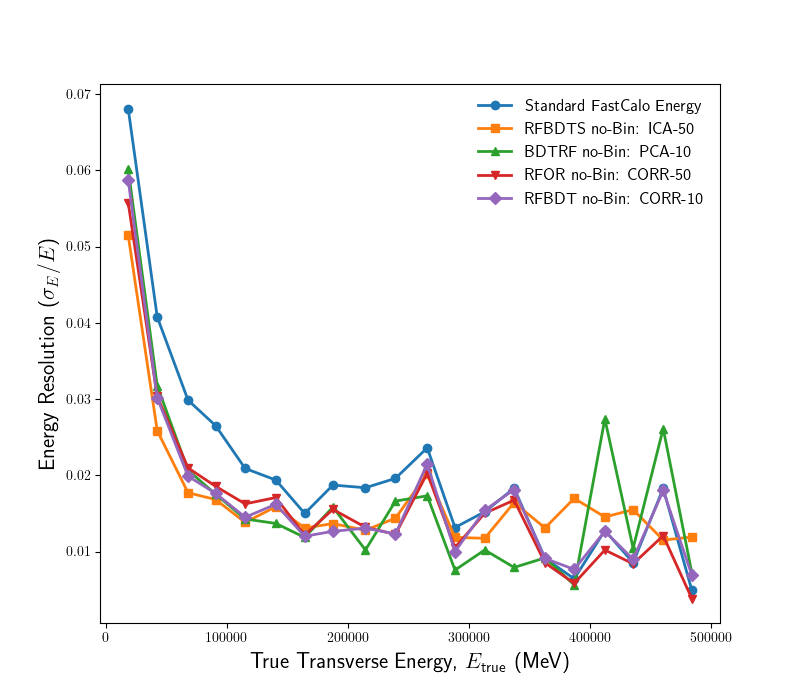

original_resolution_comparison_17_01.png


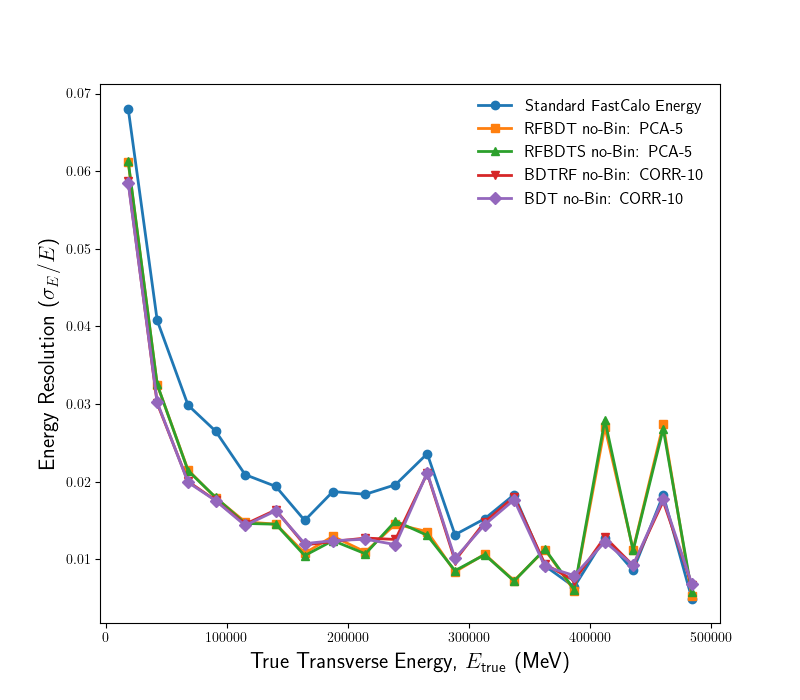

original_resolution_comparison_18_01.png


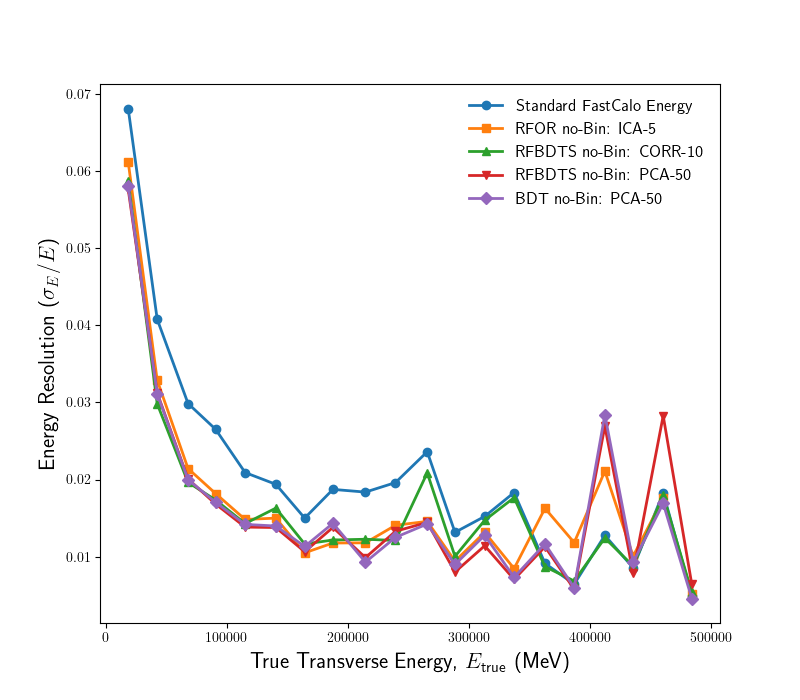

original_resolution_comparison_19_01.png


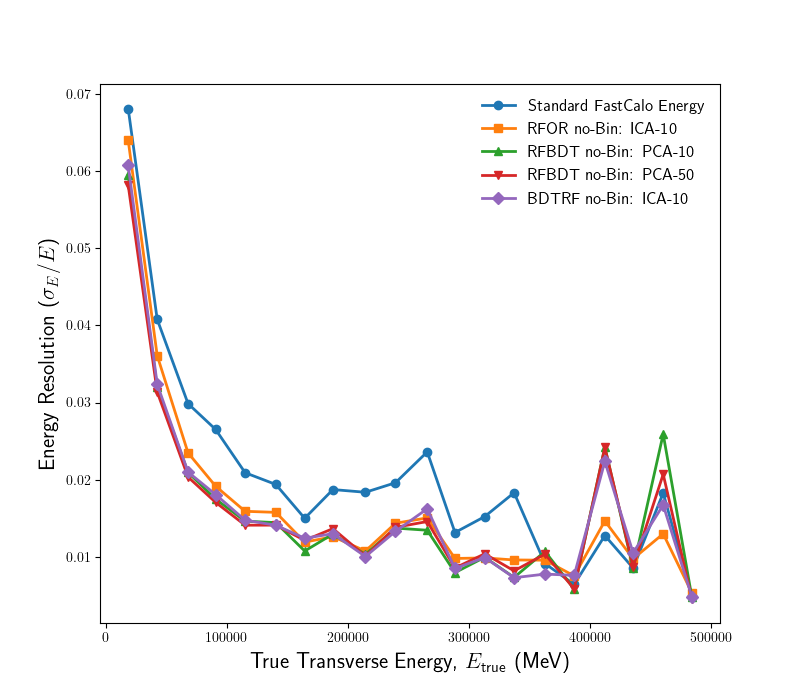

original_resolution_comparison_20_01.png


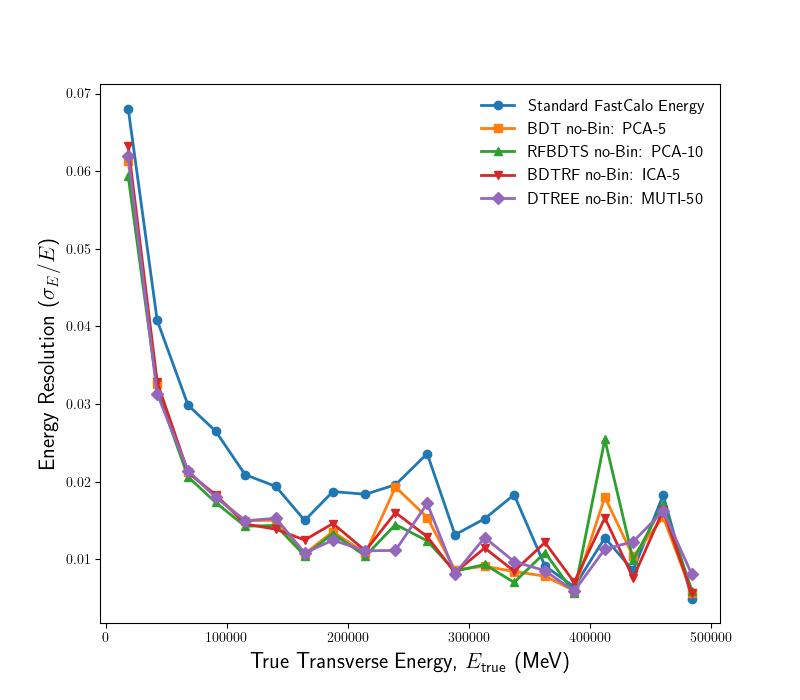

original_resolution_comparison_21_01.png


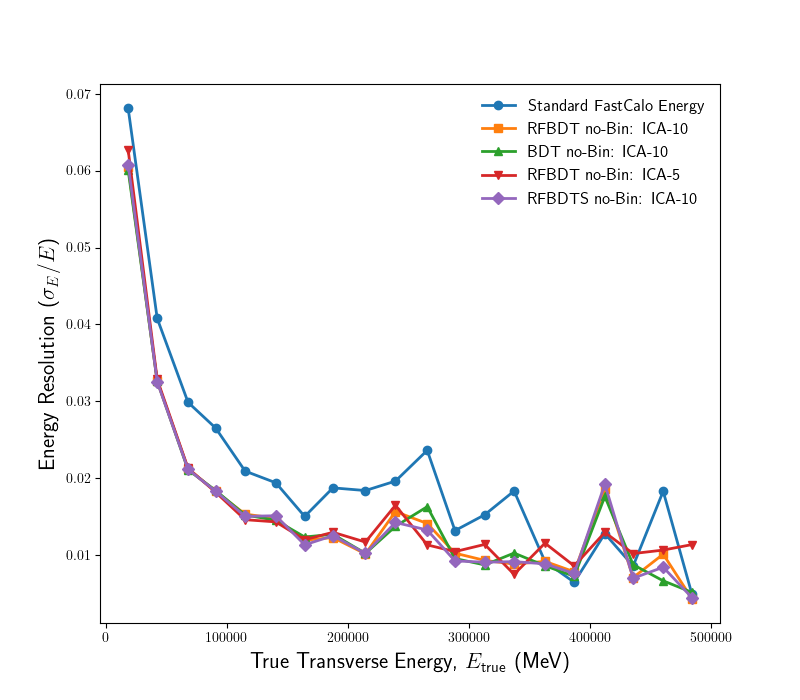

original_resolution_comparison_22_01.png


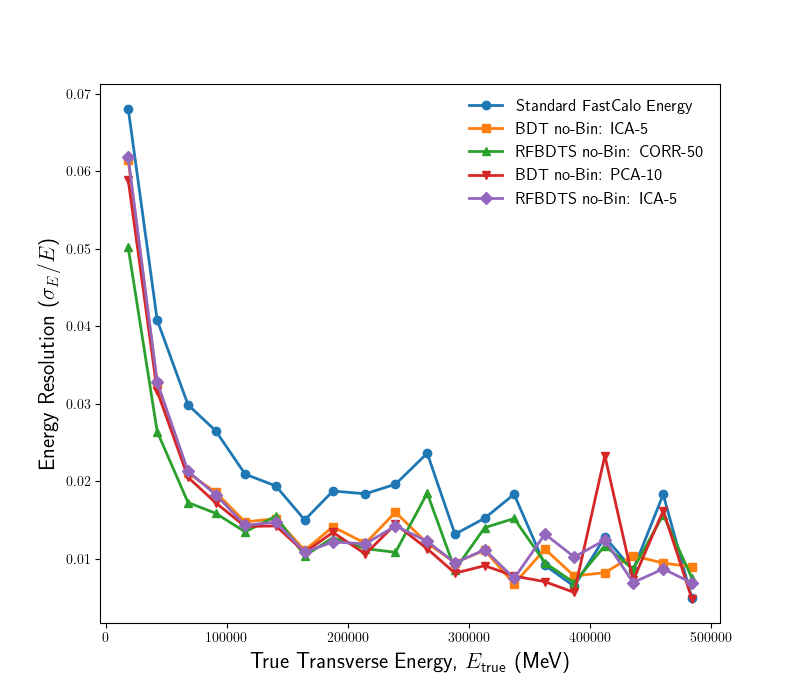

original_resolution_comparison_23_01.png


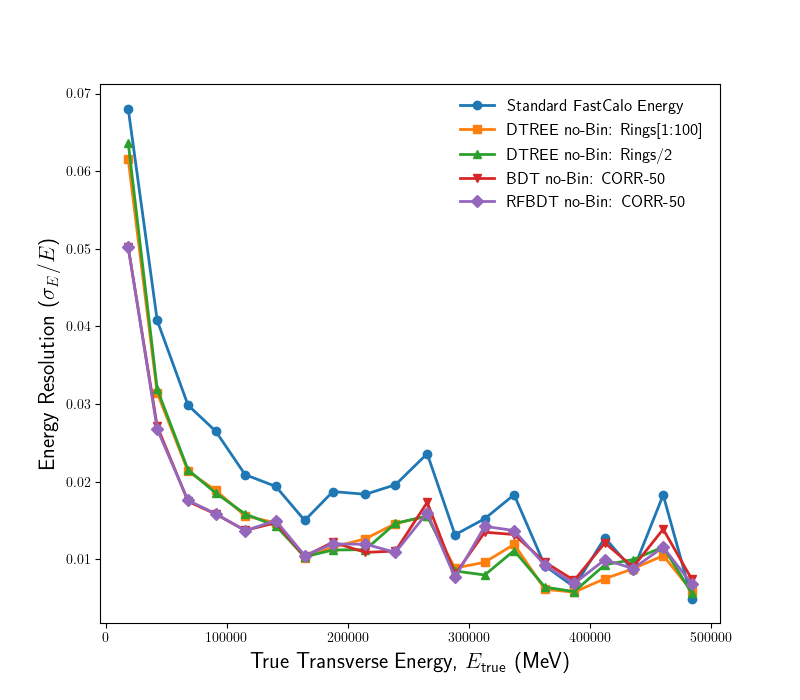

original_resolution_comparison_24_01.png


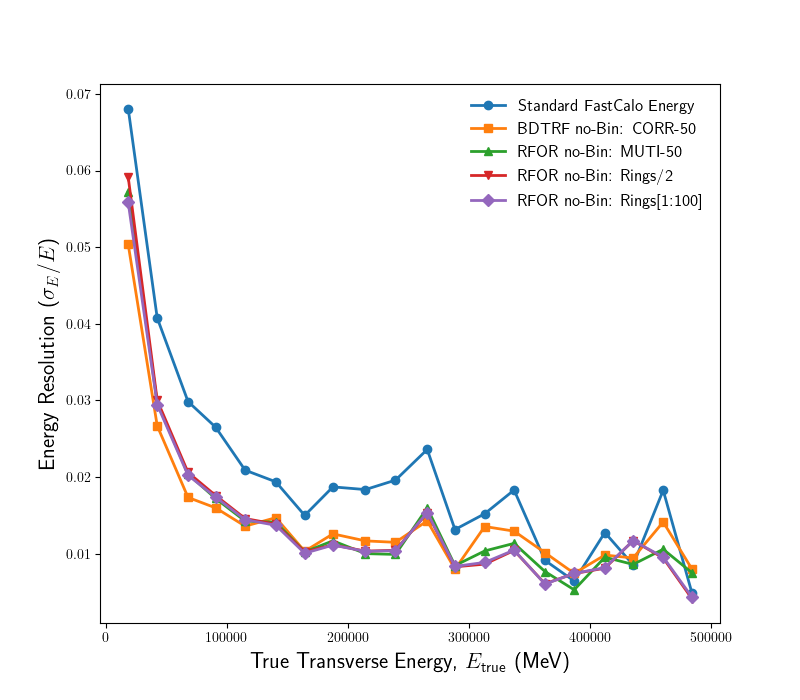

original_resolution_comparison_25_01.png


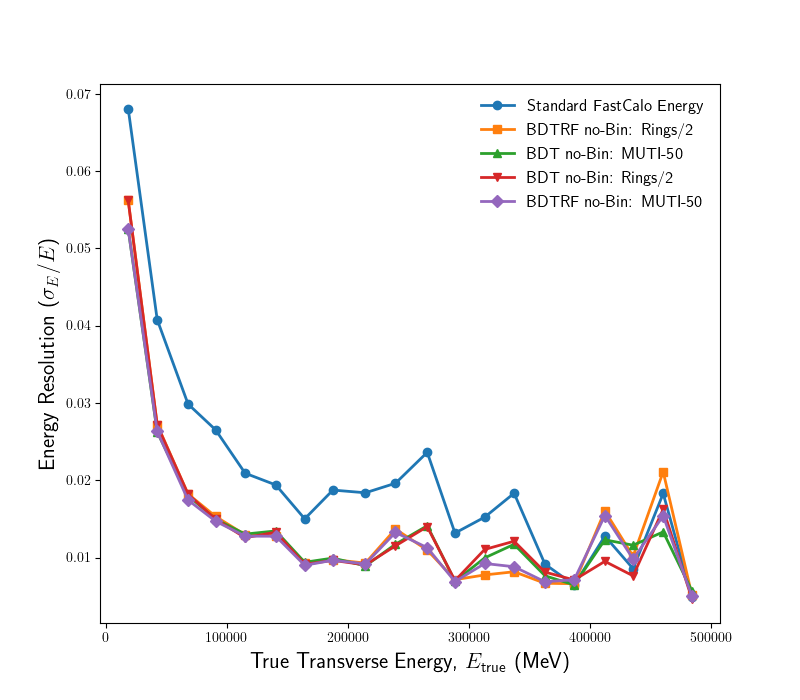

original_resolution_comparison_26_01.png


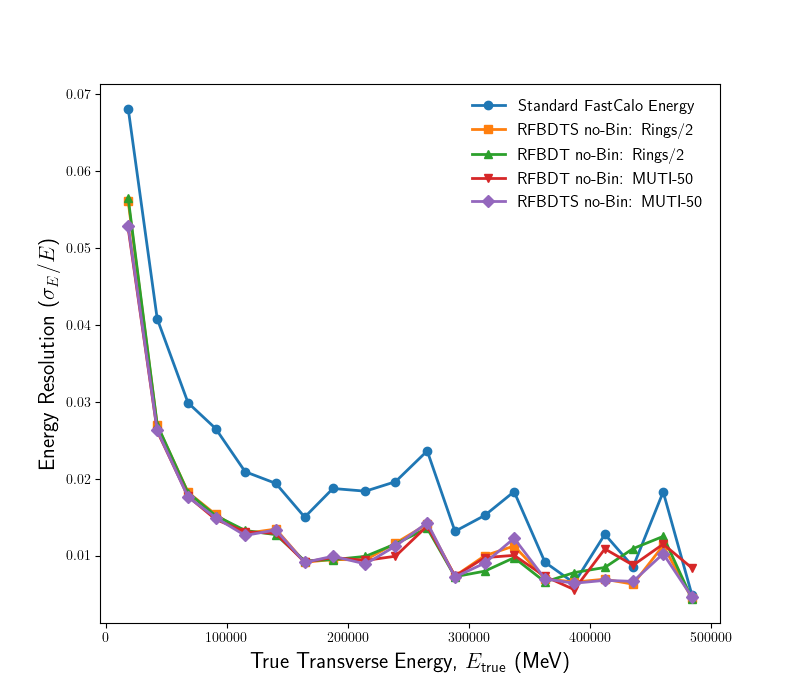

original_resolution_comparison_27_01.png


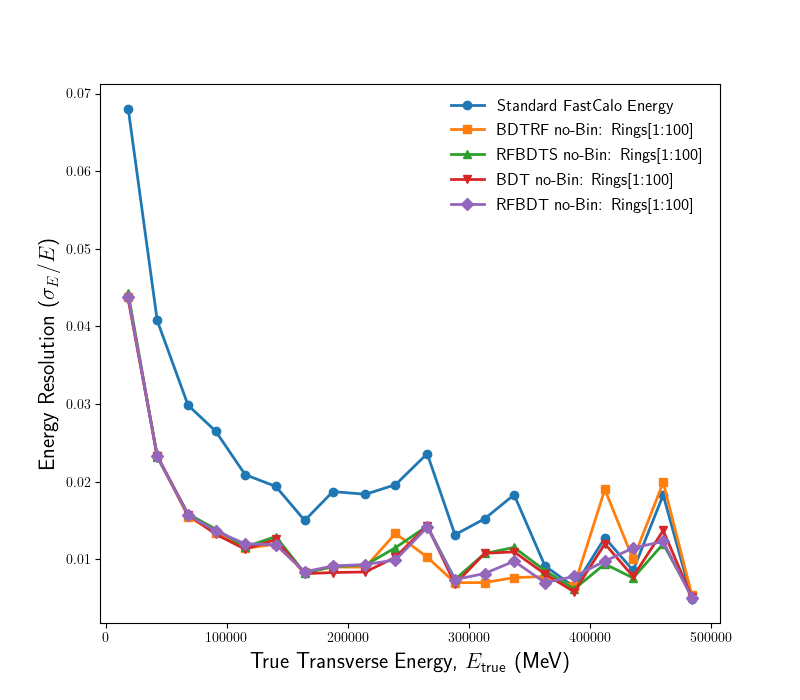

original_resolution_BDT_no-Bin__ICA-5_01.png


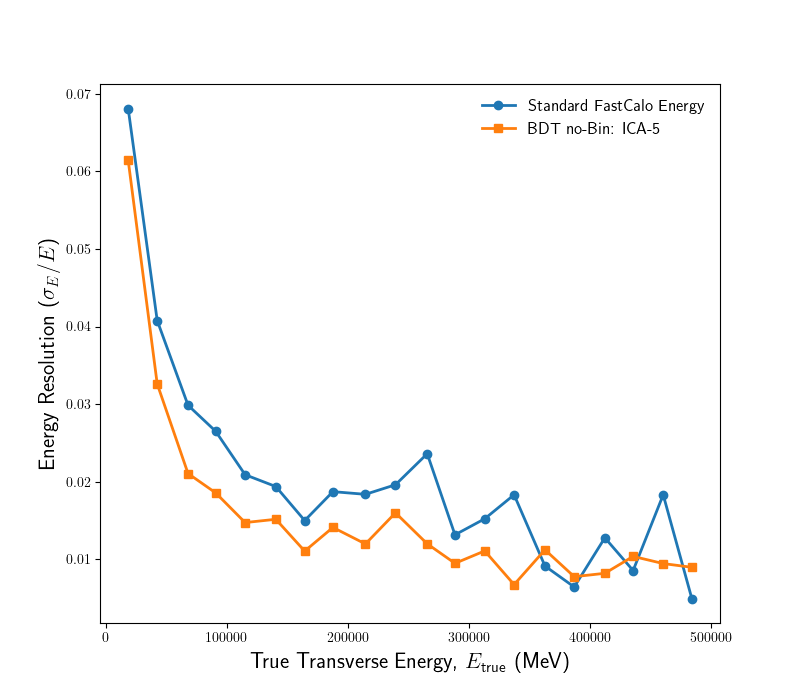

original_qq_BDT_no-Bin__ICA-5_01.png


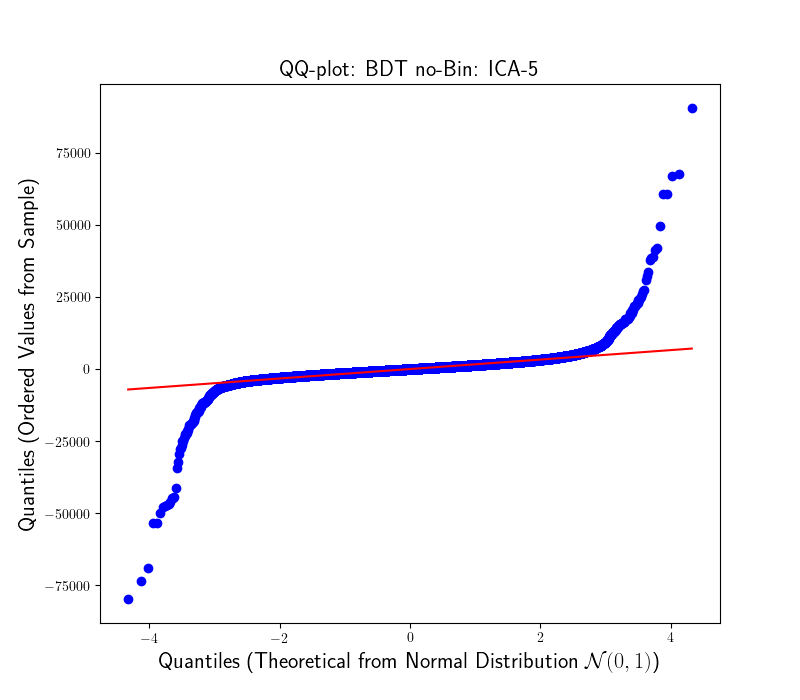

original_segmented_02.png


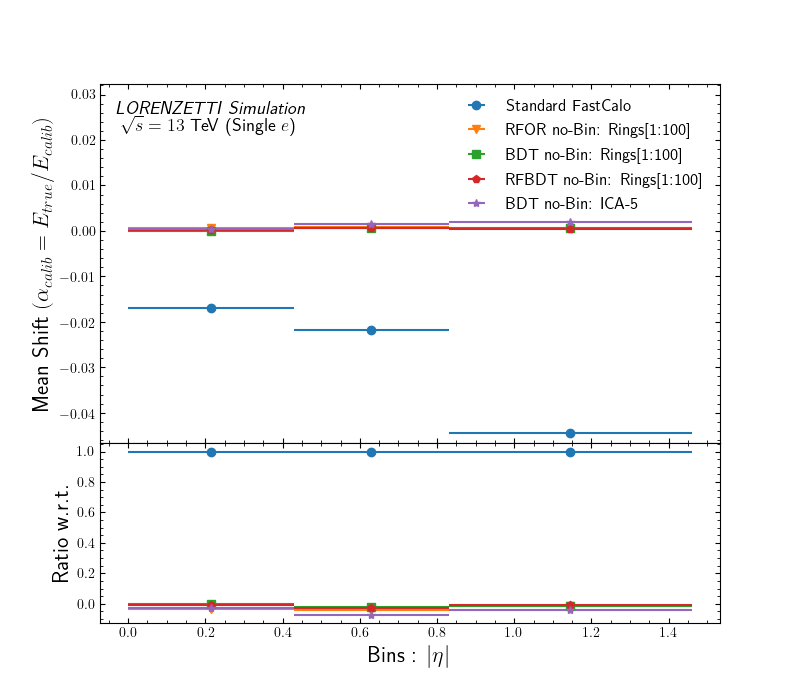

original_segmented_04.png


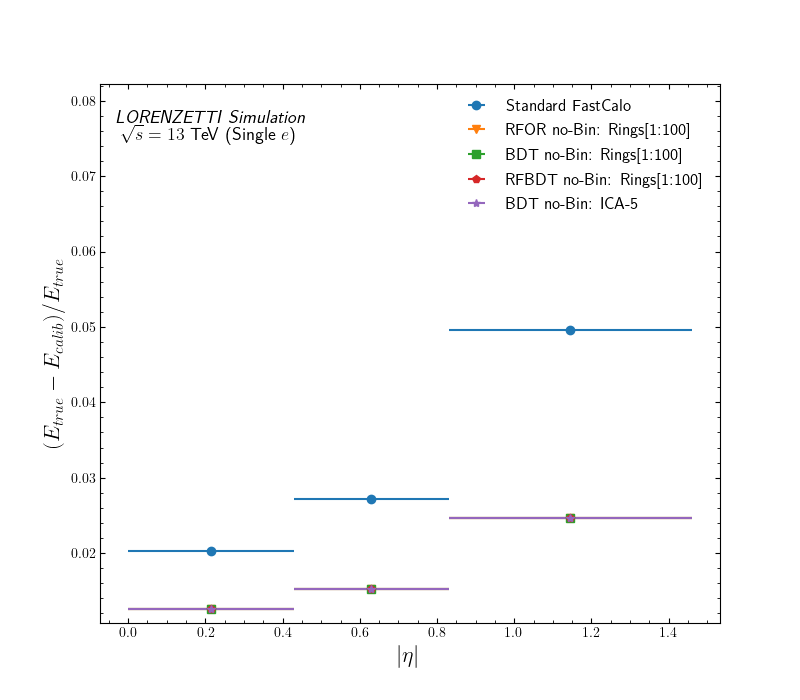

original_segmented_05.png


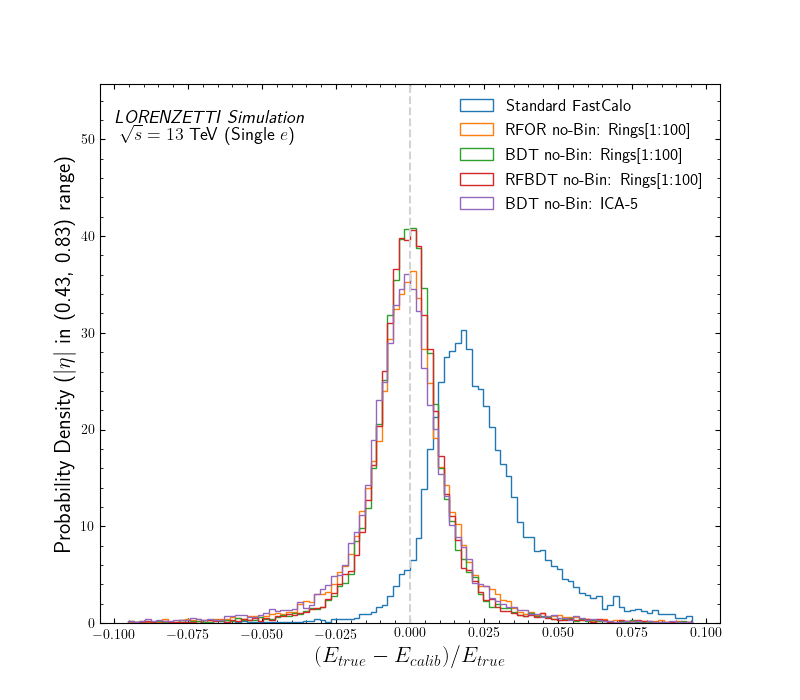

original_segmented_06.png


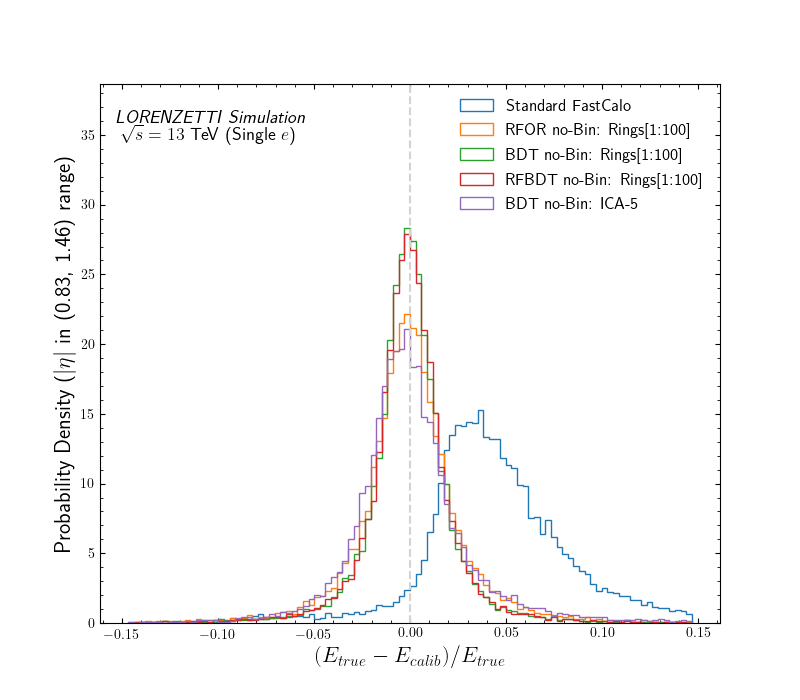

original_segmented_07.png


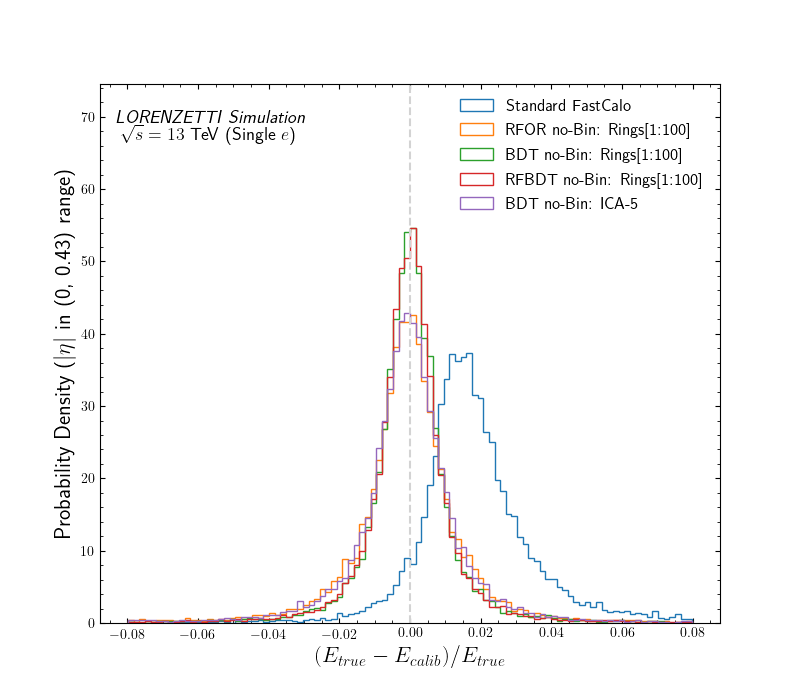

original_segmented_09.png


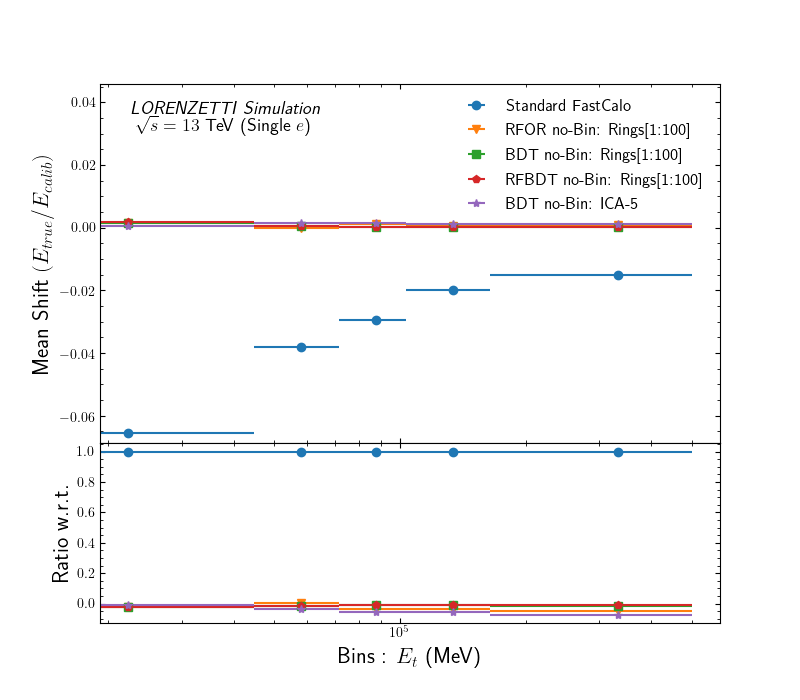

original_segmented_11.png


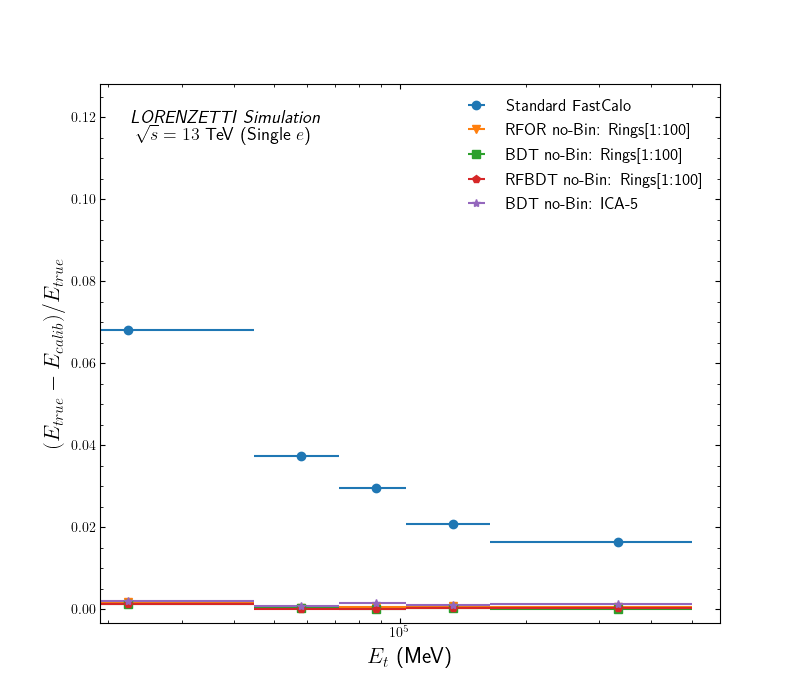

original_segmented_12.png


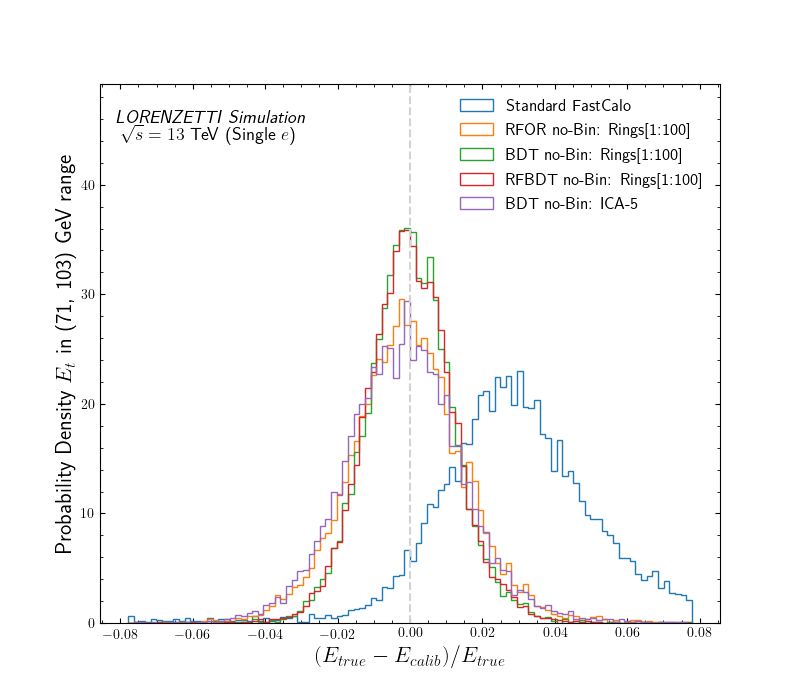

original_segmented_13.png


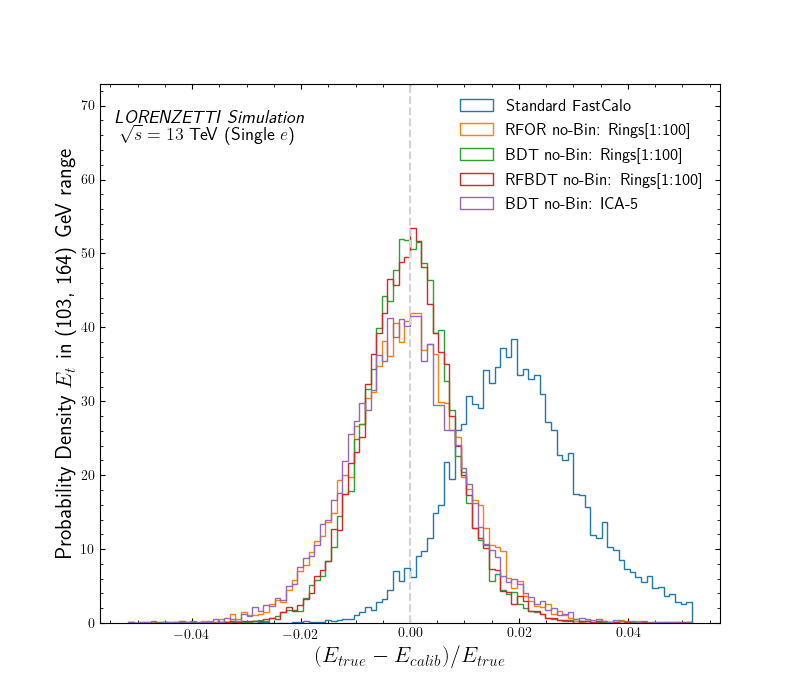

original_segmented_14.png


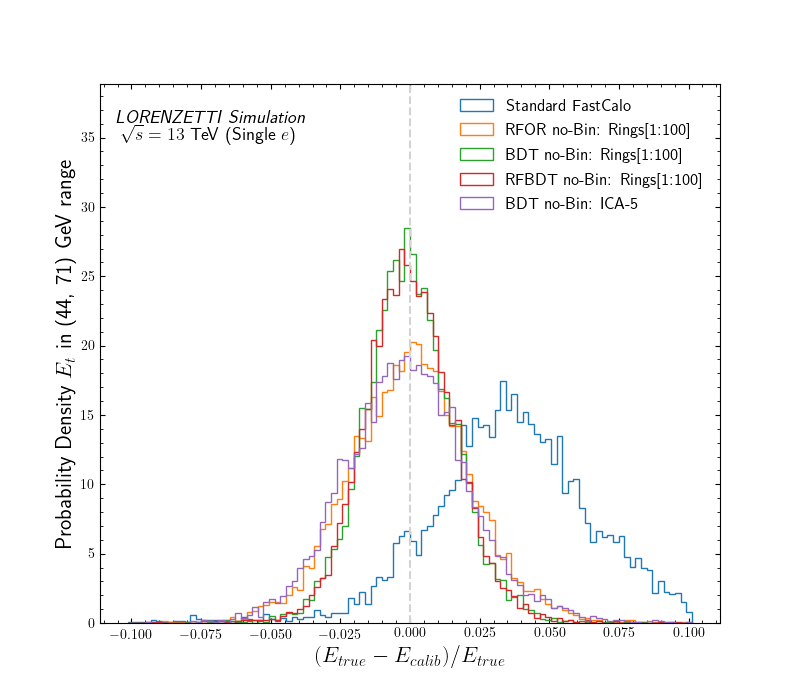

original_segmented_15.png


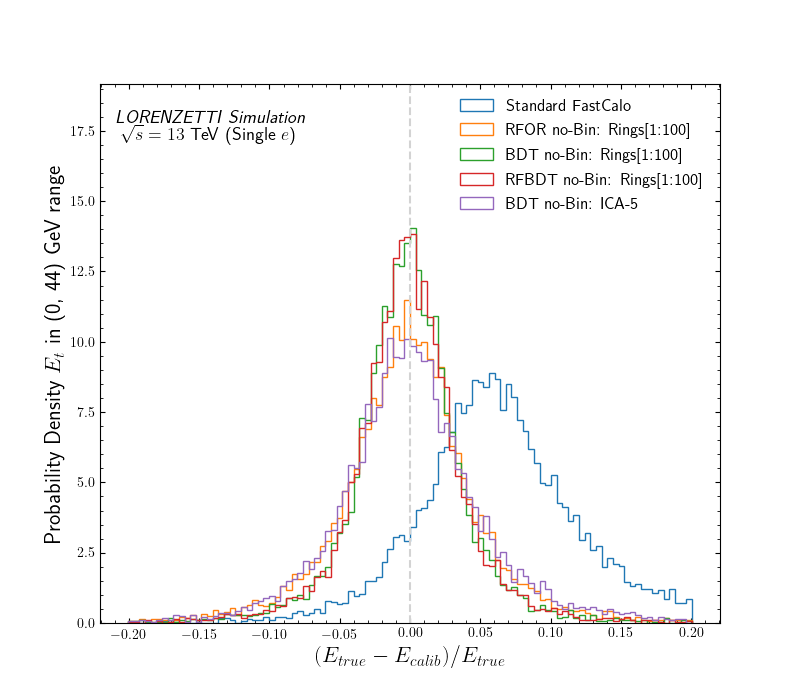

original_segmented_16.png


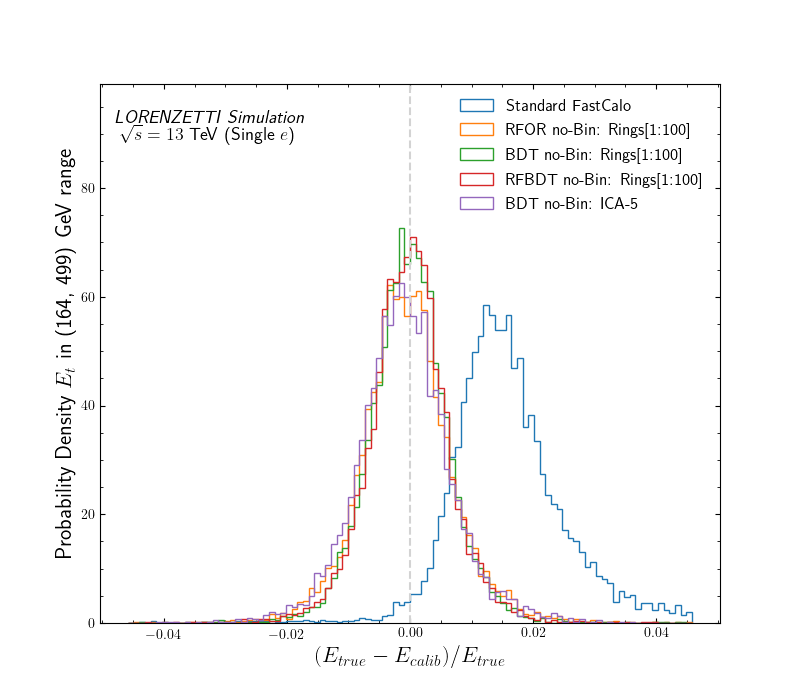

original_segmented_17.png


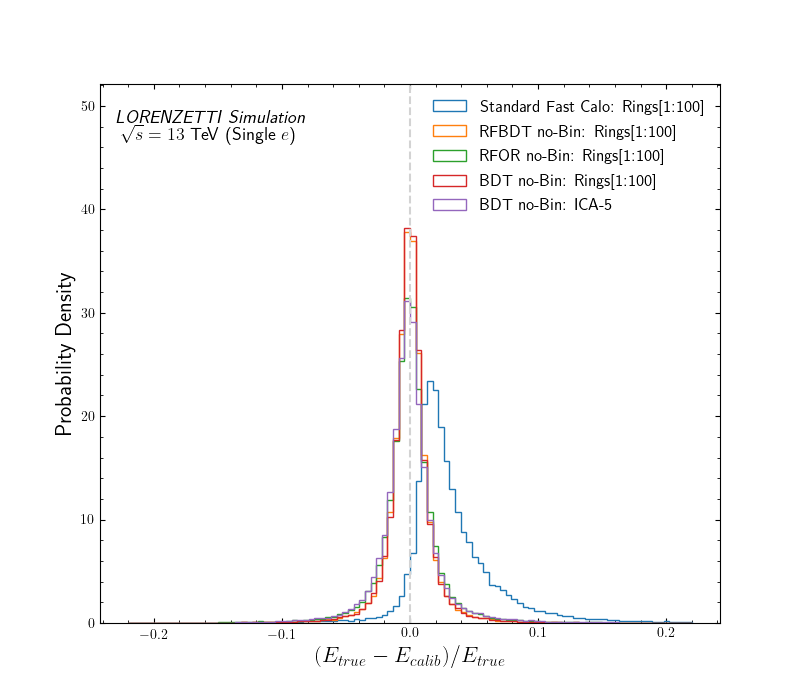

original_segmented_18.png


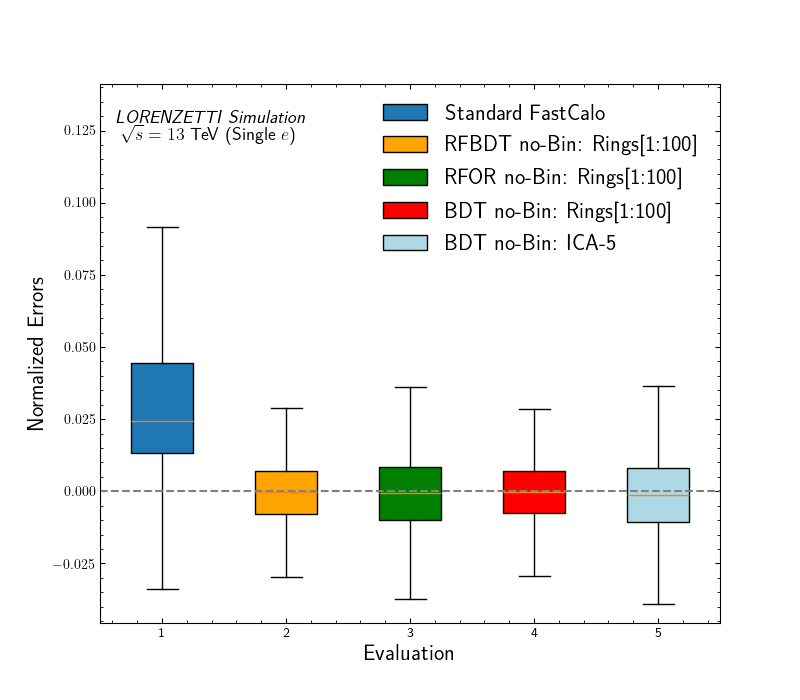

original_top10_residual_hist_box_01.png


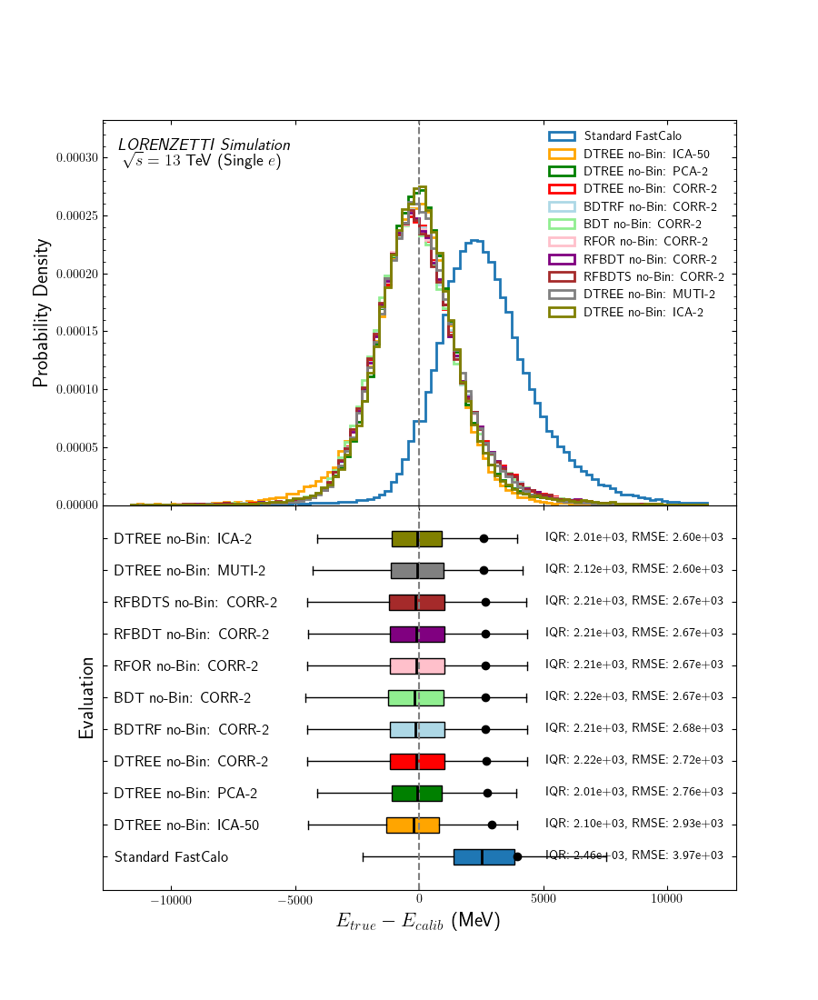

original_top10_boxplot_01.png


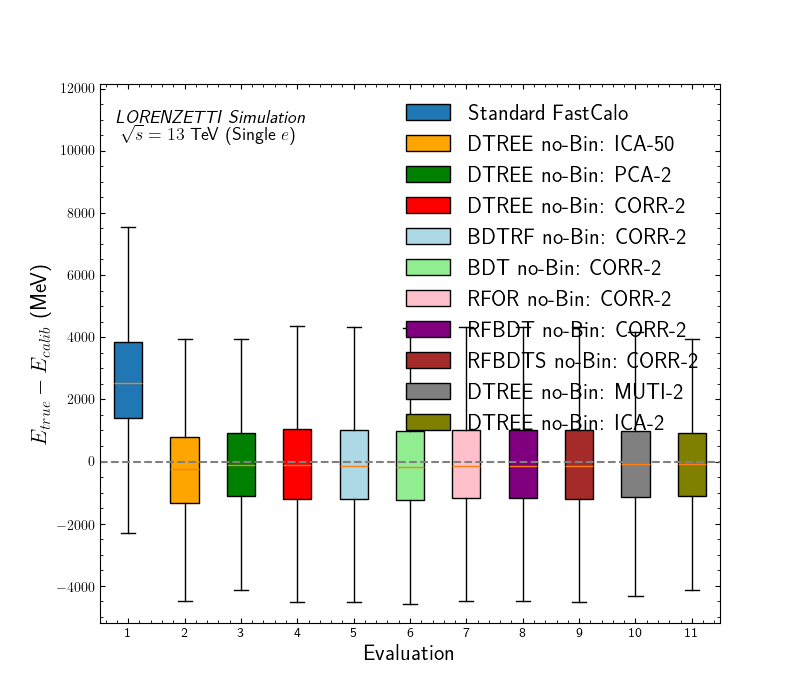

original_resolution_errorbars_01.png


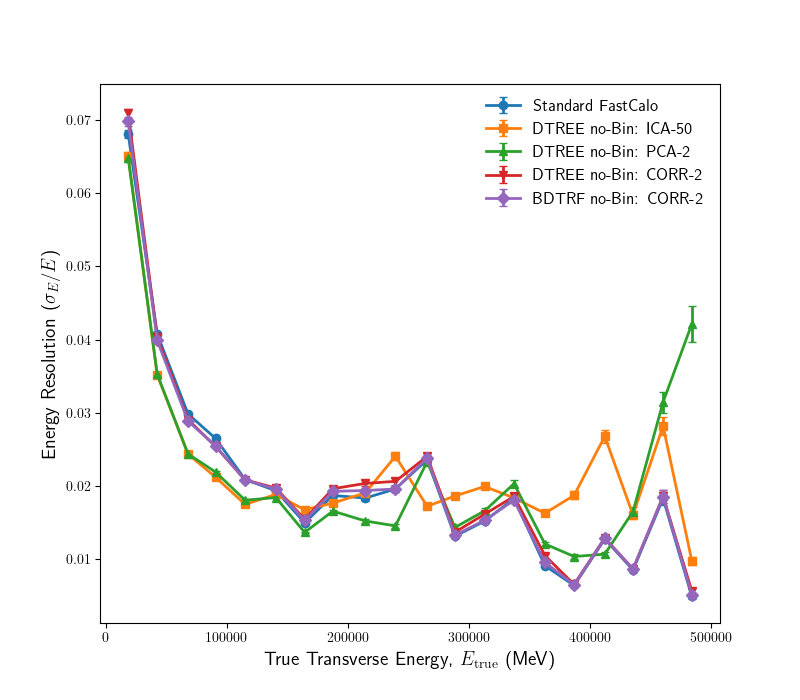

original_ranked_histogram_01.png


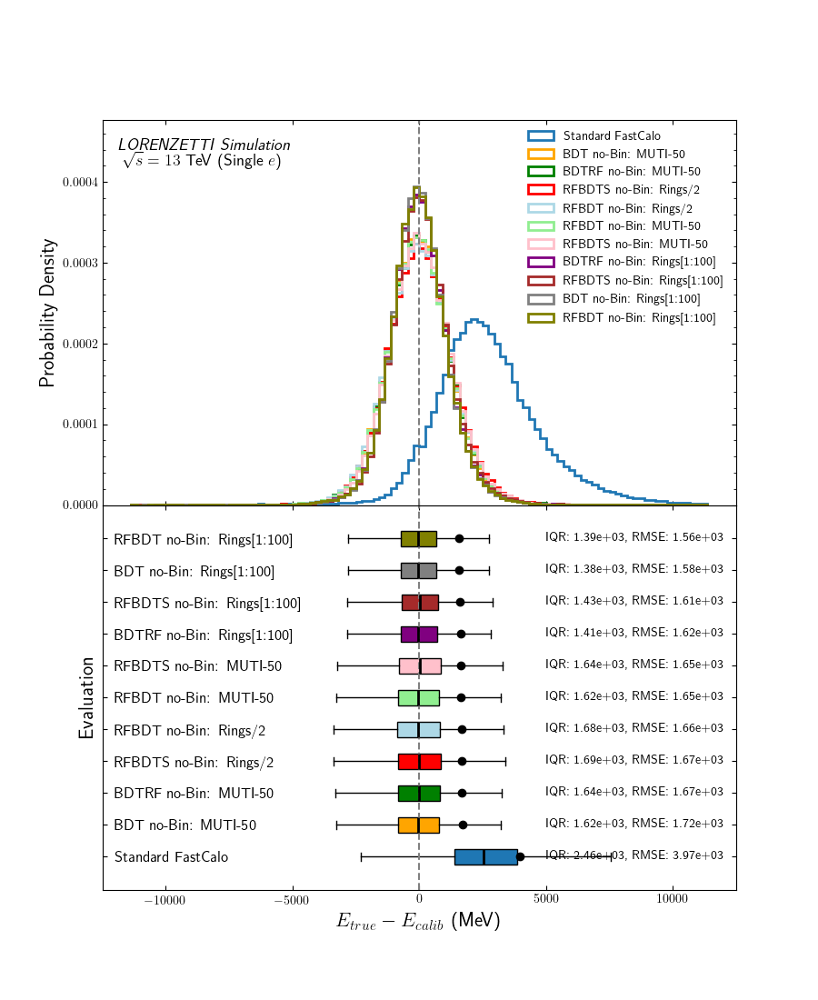

original_D0_ranked_d0_01.png


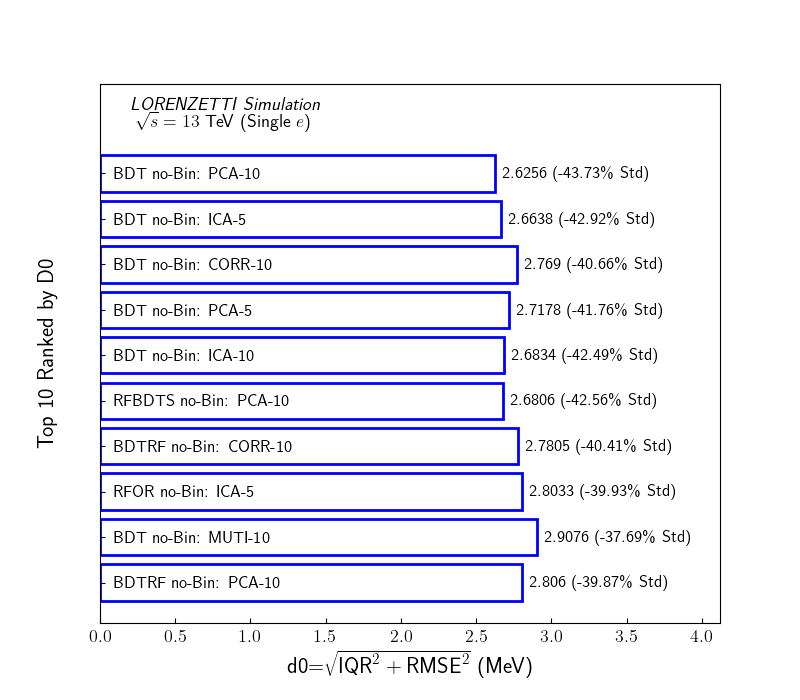

original_all_d0_comparison_01.png


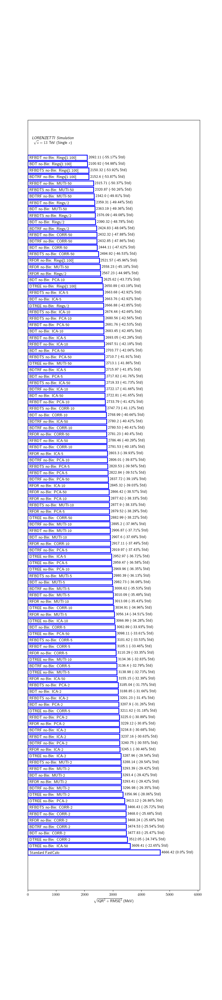

original_all_prediction_times_01.png


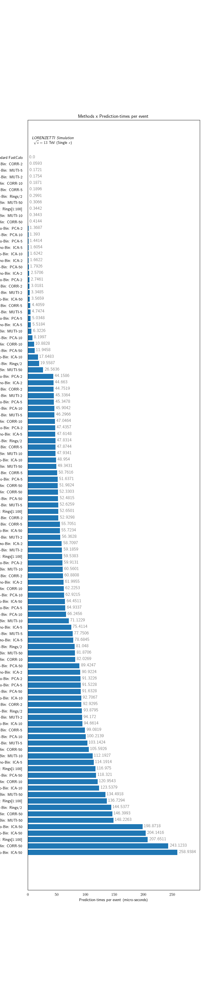

original_statistics_intervals_vertical_01.png


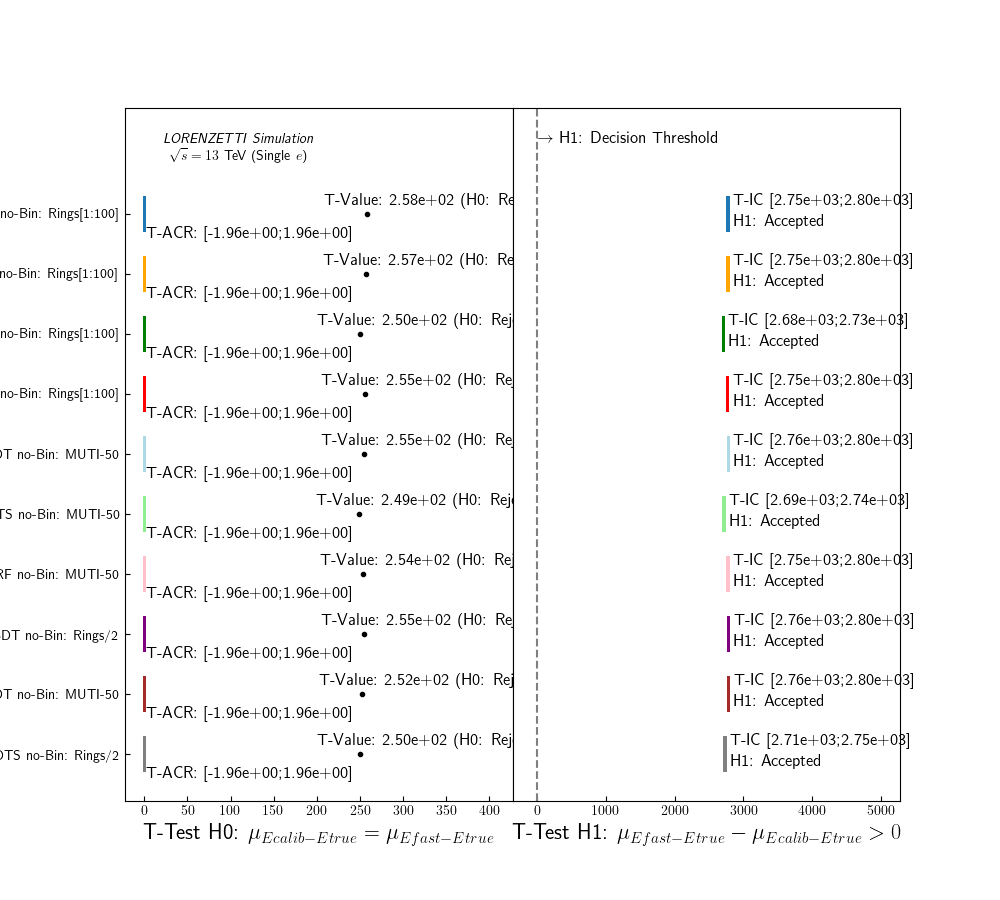

original_statistics_intervals_vertical_02.png


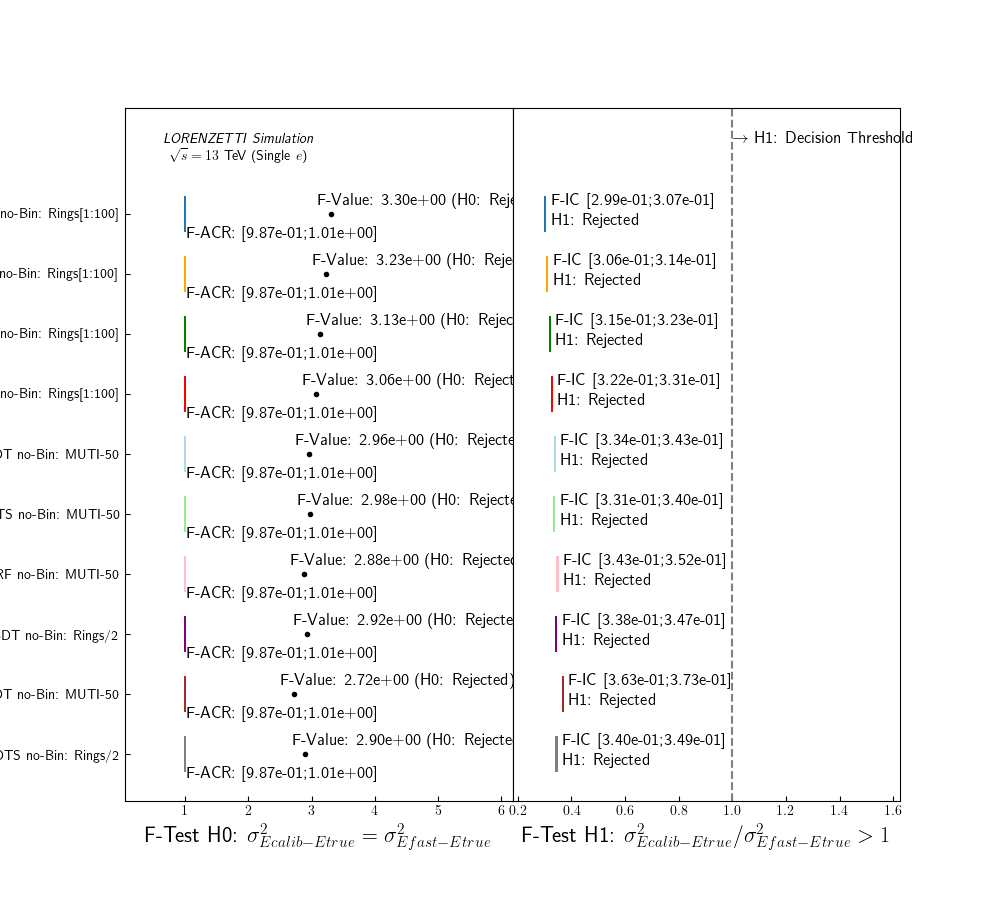

original_statistics_intervals_horizontal_01.png


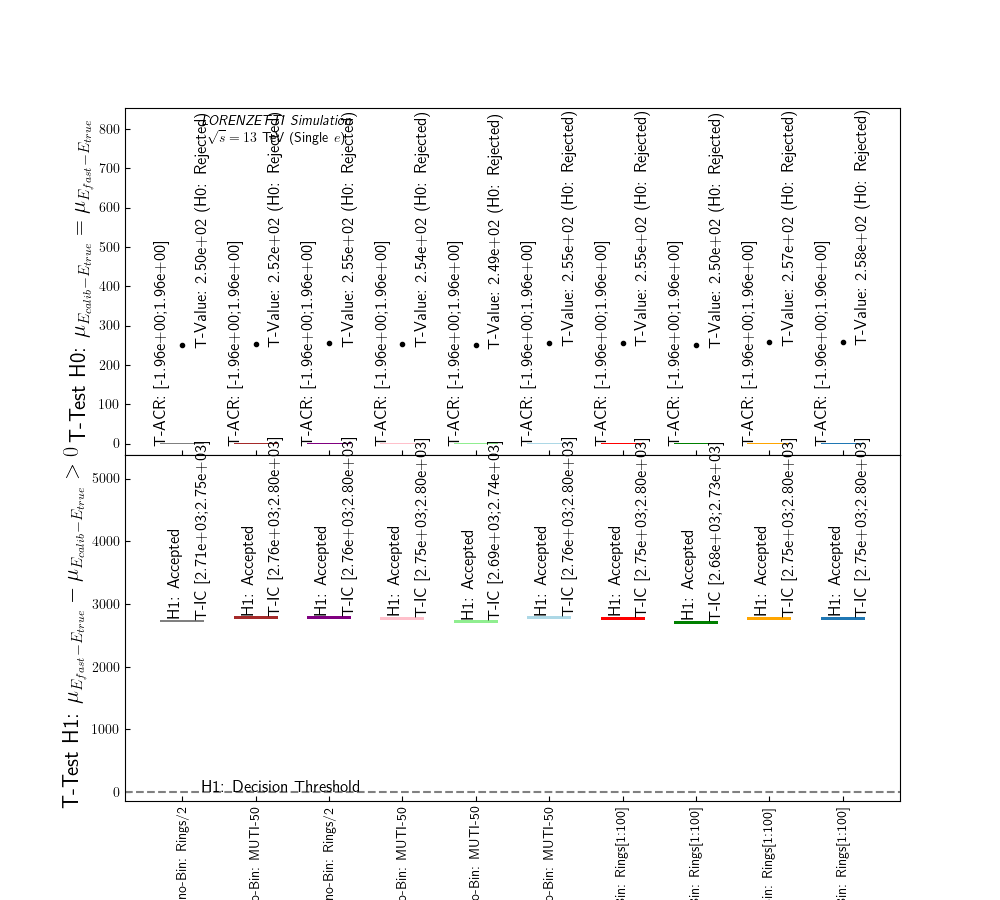

original_statistics_intervals_horizontal_02.png


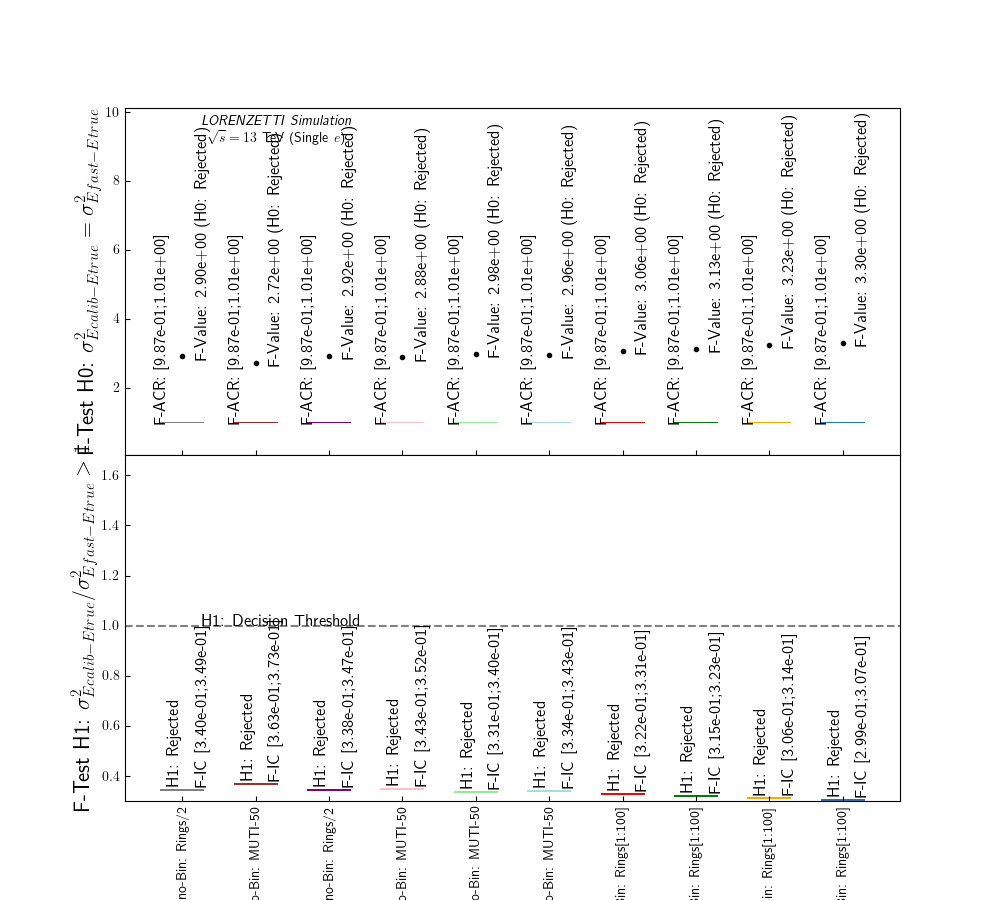

comparison_metric_cell702_01.png


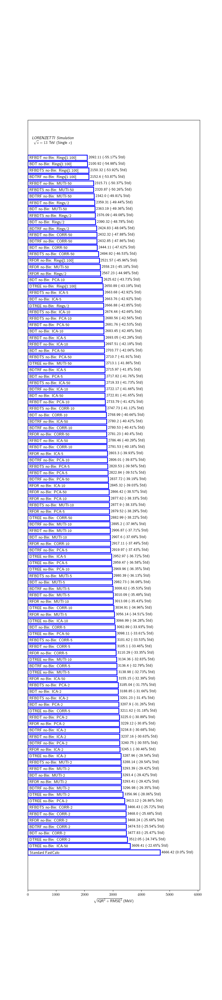

comparison_metric_all_cell705_01.png


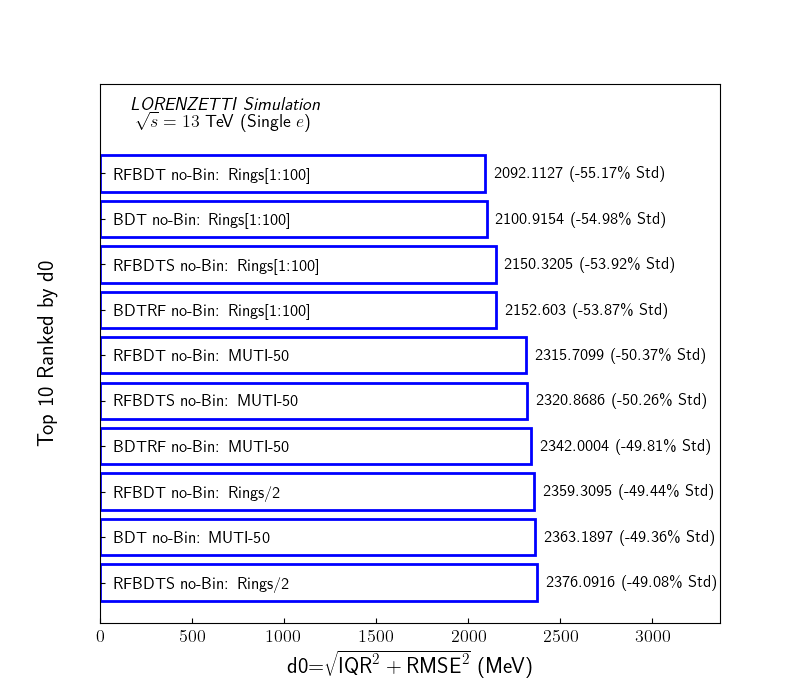

top_ten_residuals_cell749_01.png


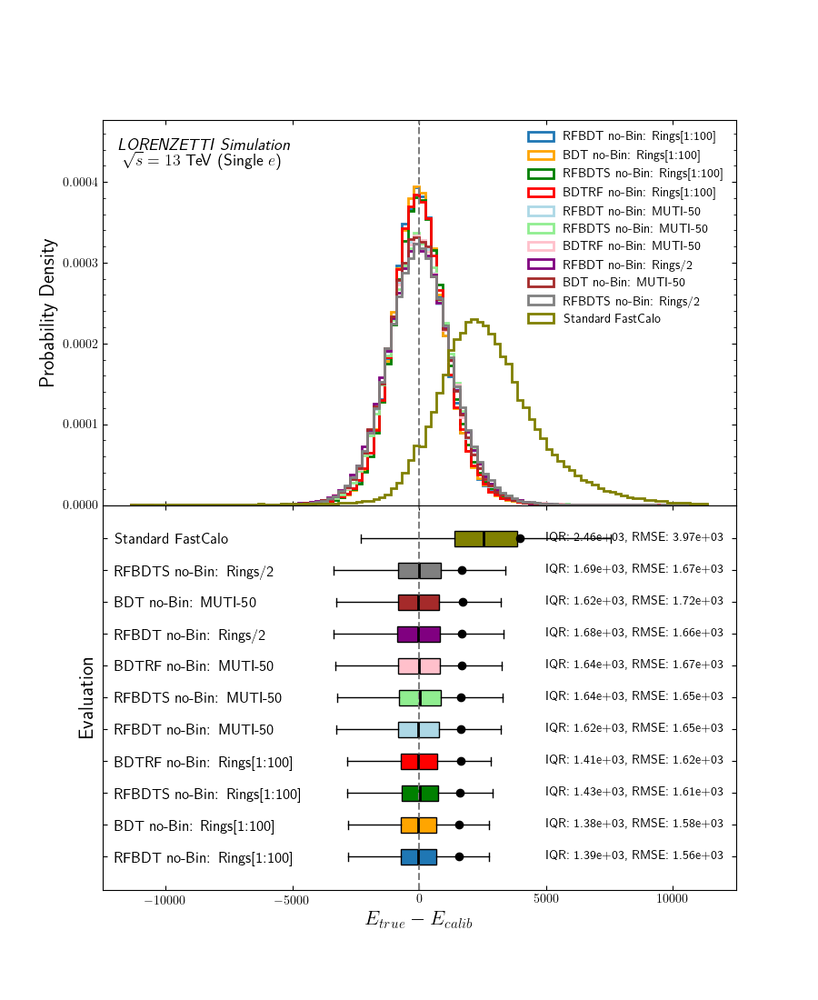

rmse_iqr_quadrant_cell767_01.png


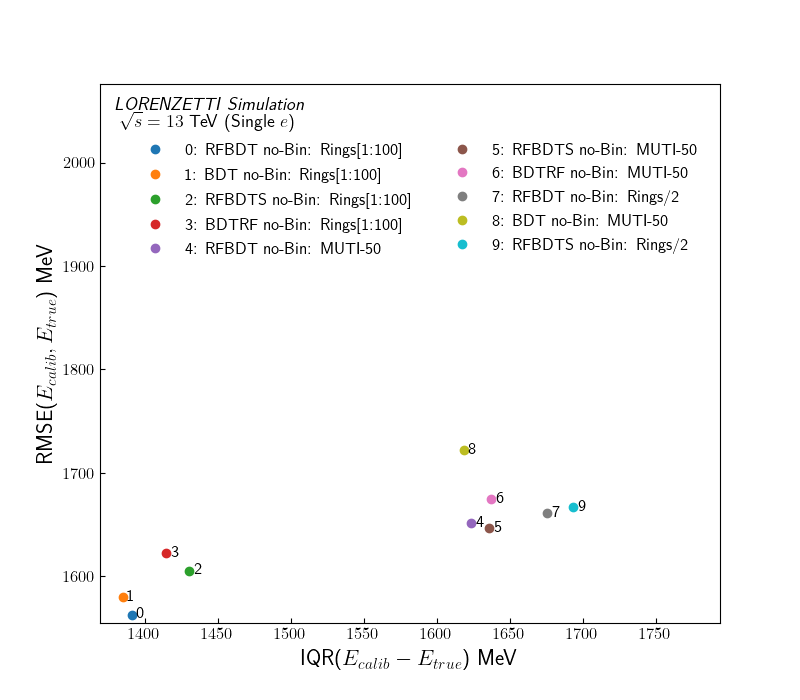

comparison_by_representation_CORR_10_01.png


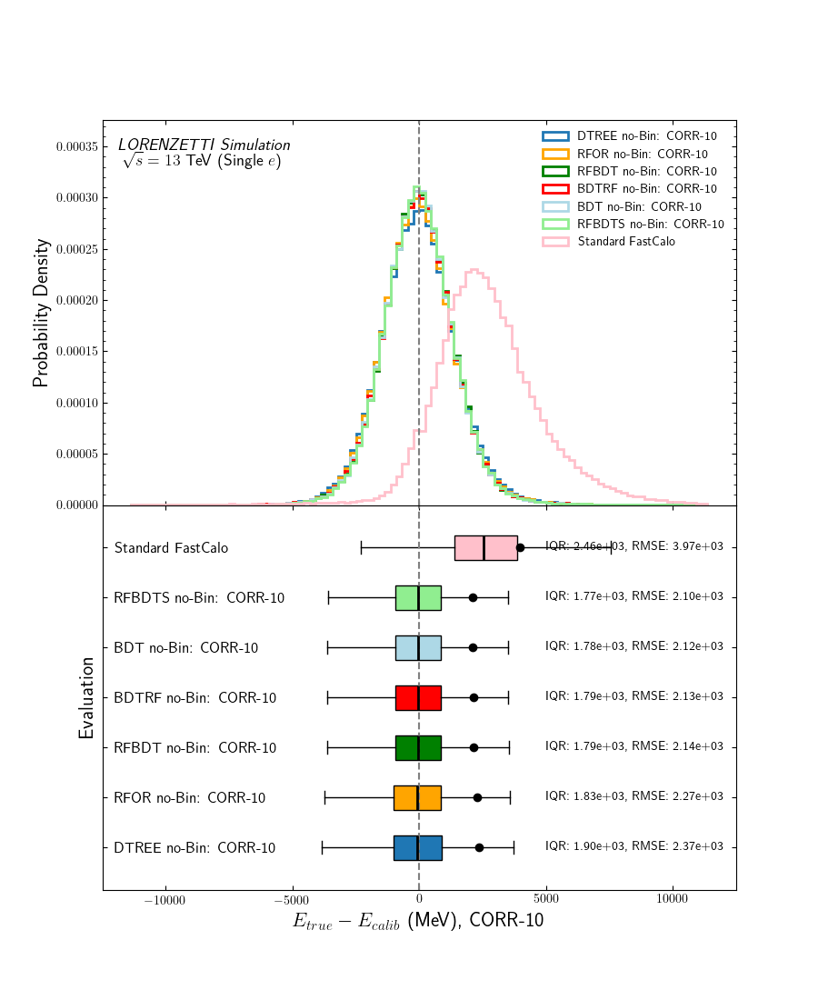

comparison_by_representation_CORR_2_01.png


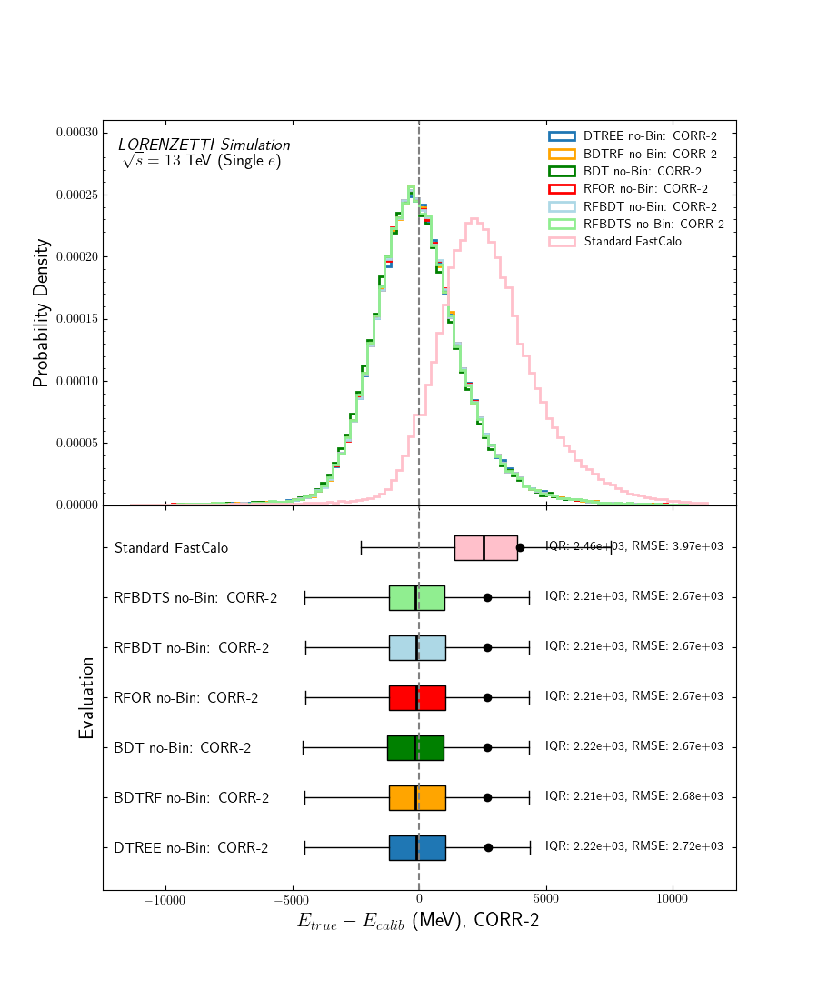

comparison_by_representation_CORR_5_01.png


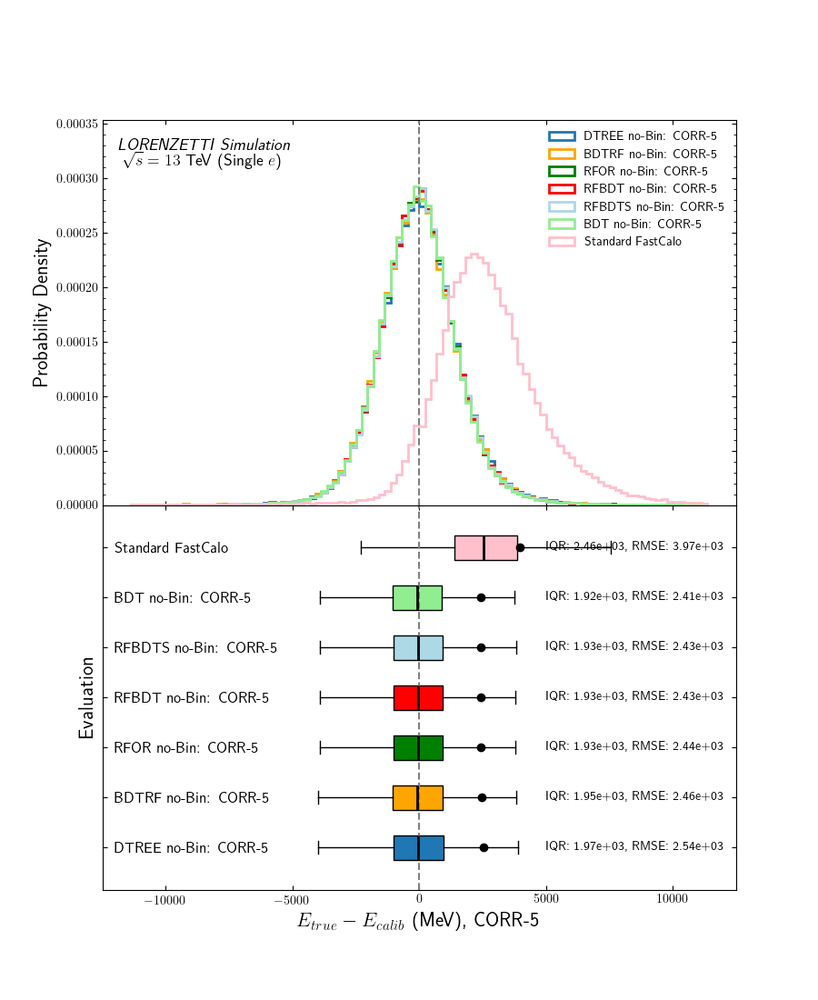

comparison_by_representation_CORR_50_01.png


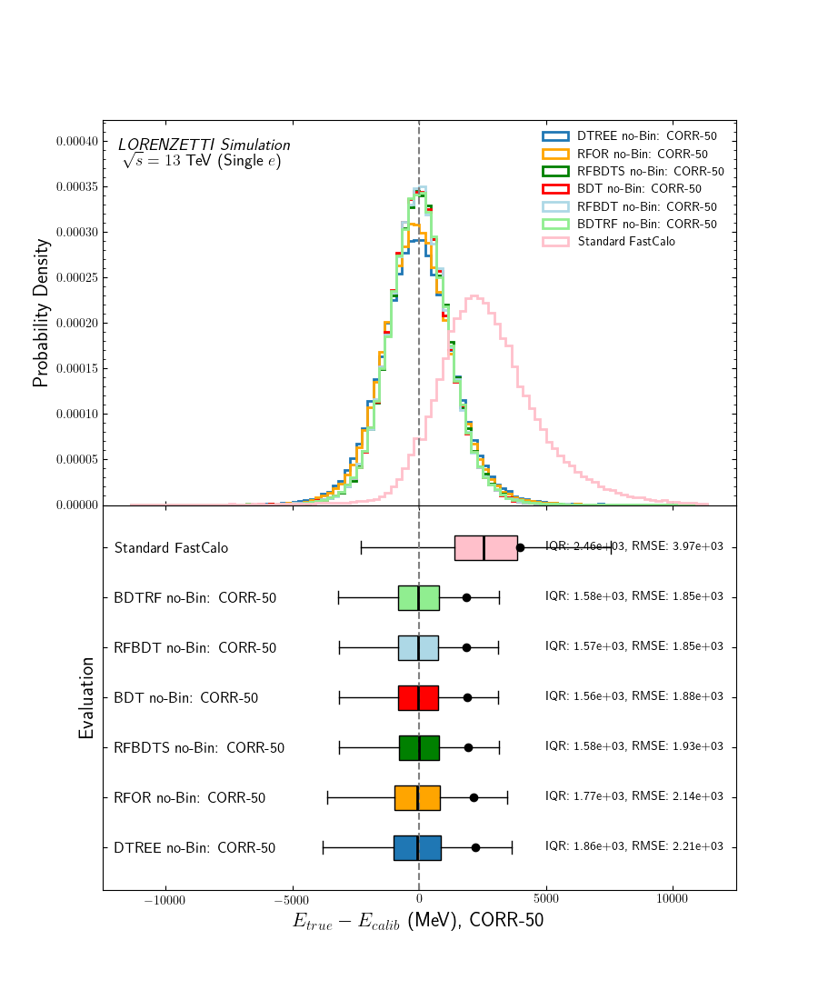

comparison_by_representation_ICA_10_01.png


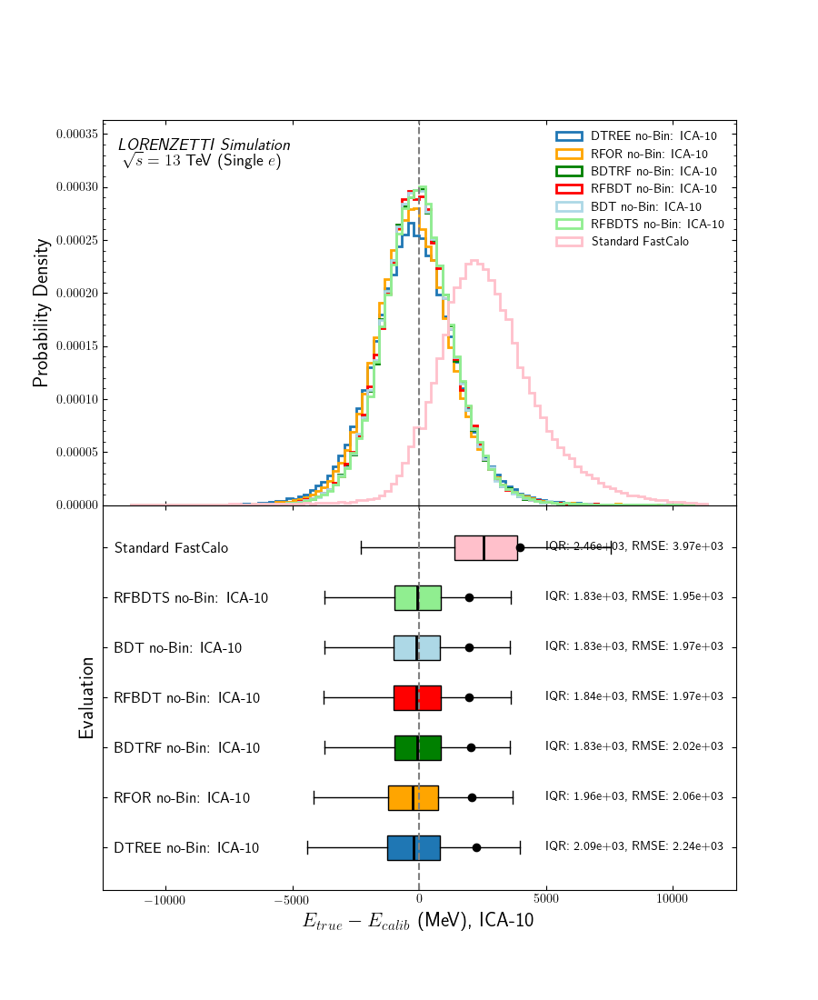

comparison_by_representation_ICA_2_01.png


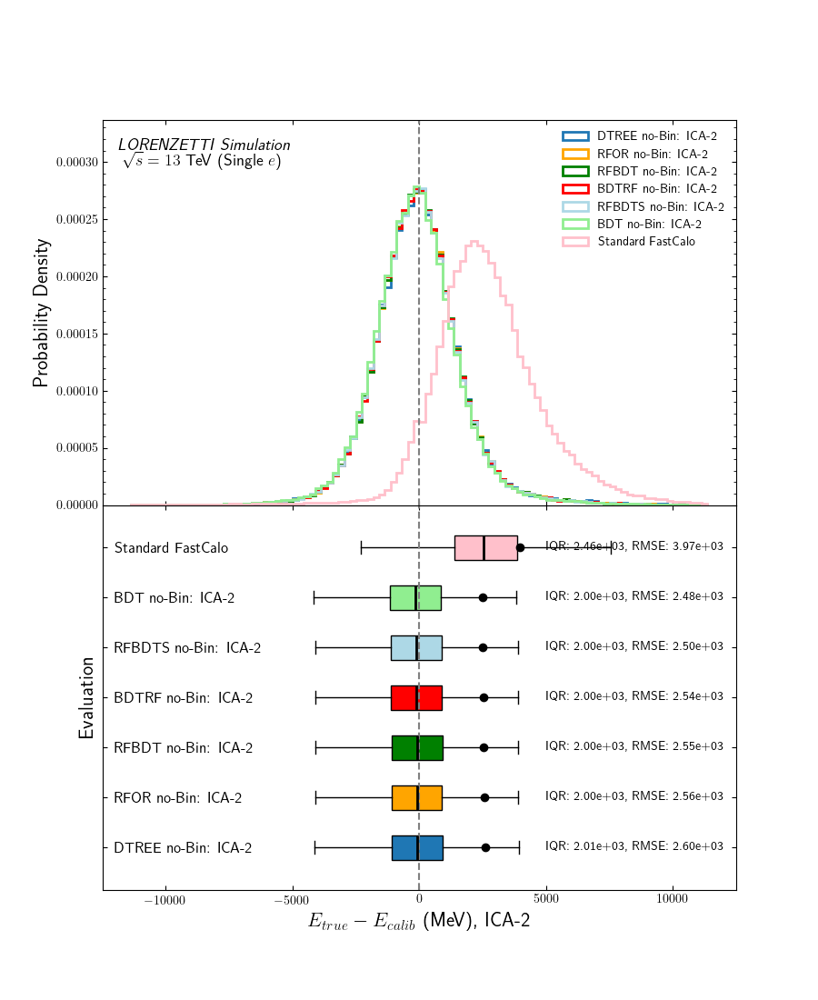

comparison_by_representation_ICA_5_01.png


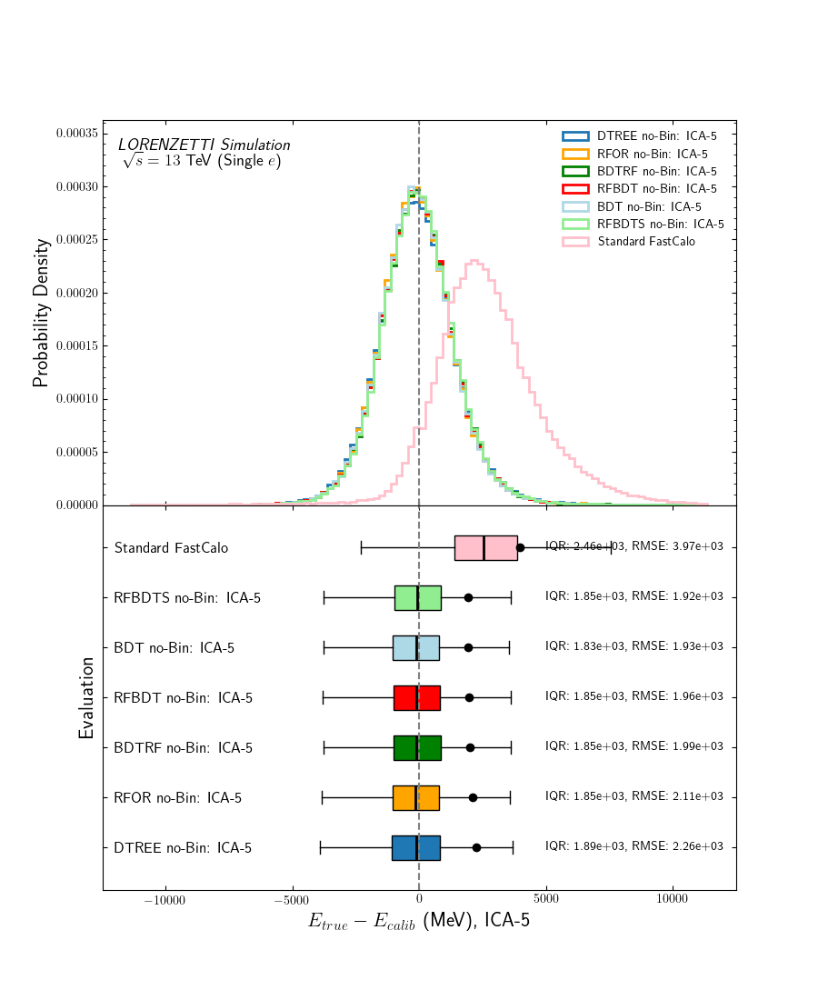

comparison_by_representation_ICA_50_01.png


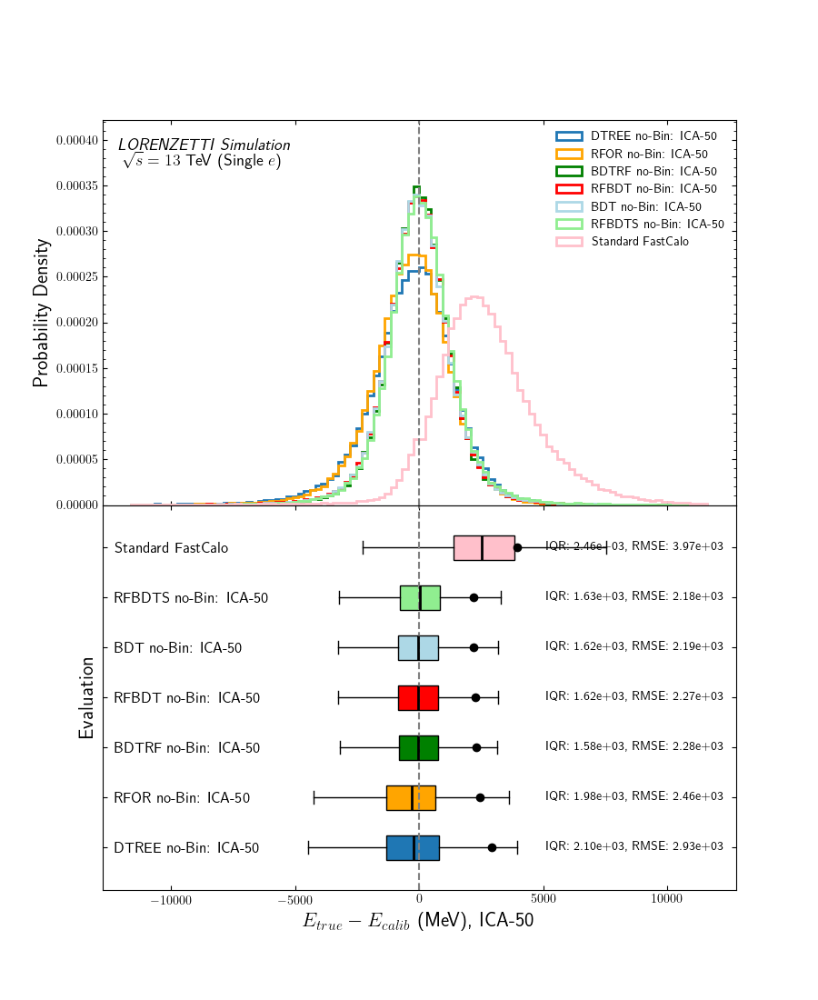

comparison_by_representation_MUTI_10_01.png


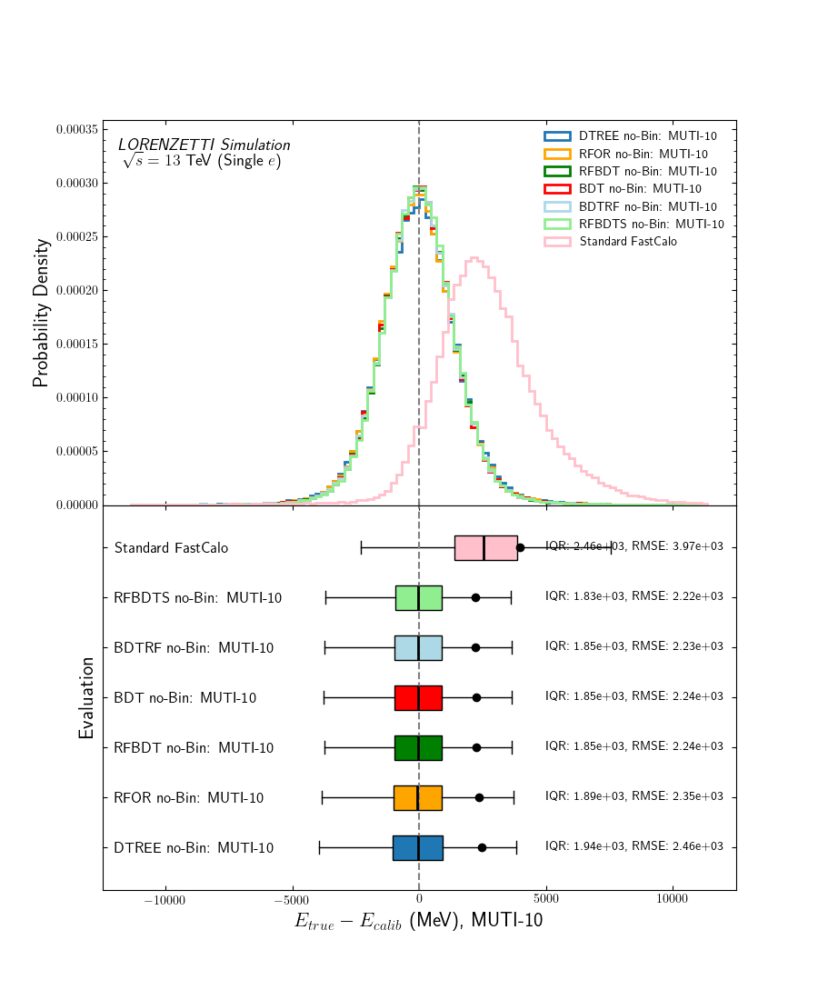

comparison_by_representation_MUTI_2_01.png


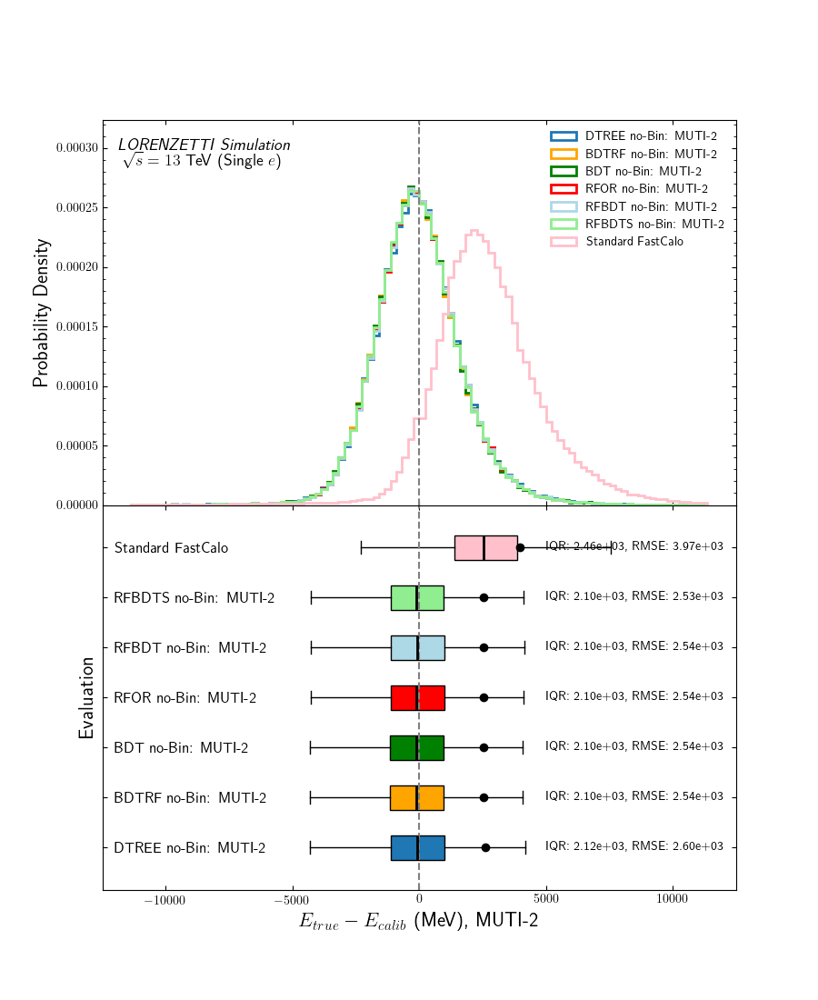

comparison_by_representation_MUTI_5_01.png


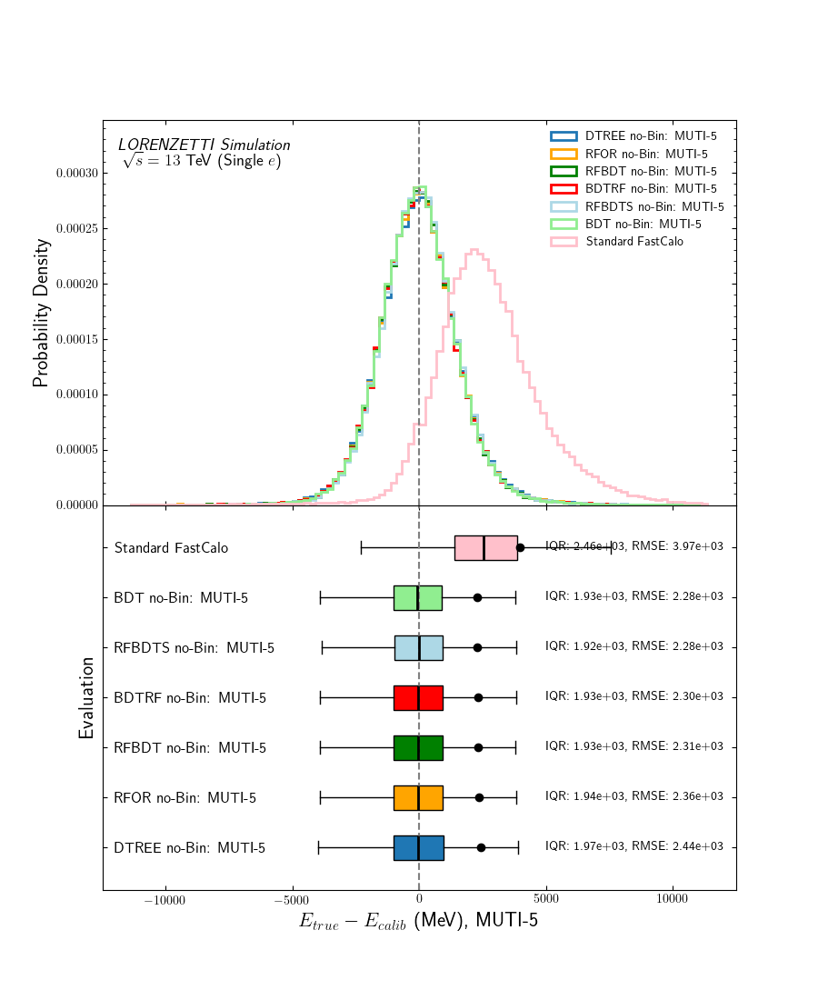

comparison_by_representation_MUTI_50_01.png


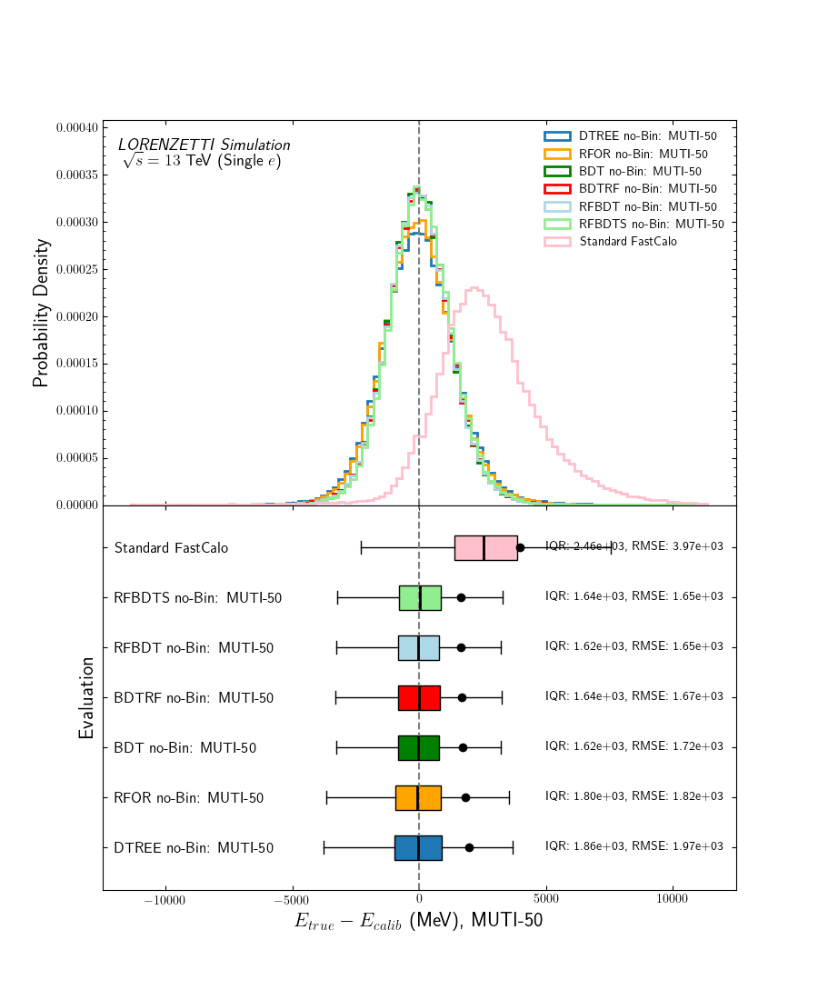

comparison_by_representation_PCA_10_01.png


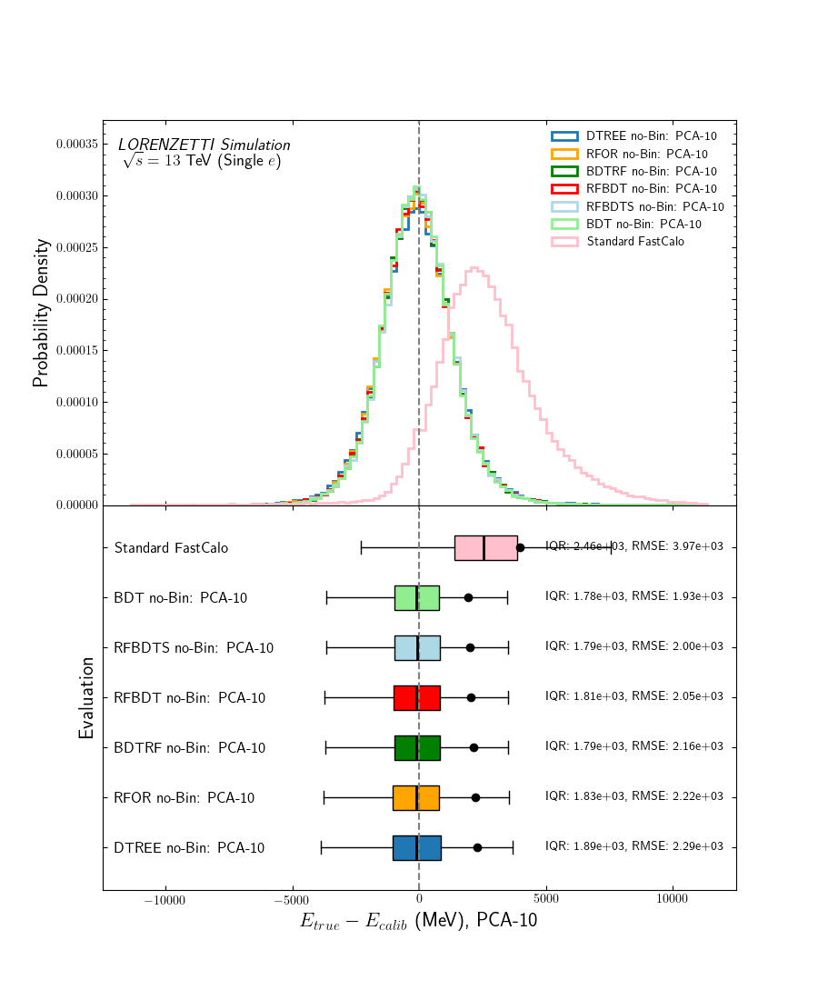

comparison_by_representation_PCA_2_01.png


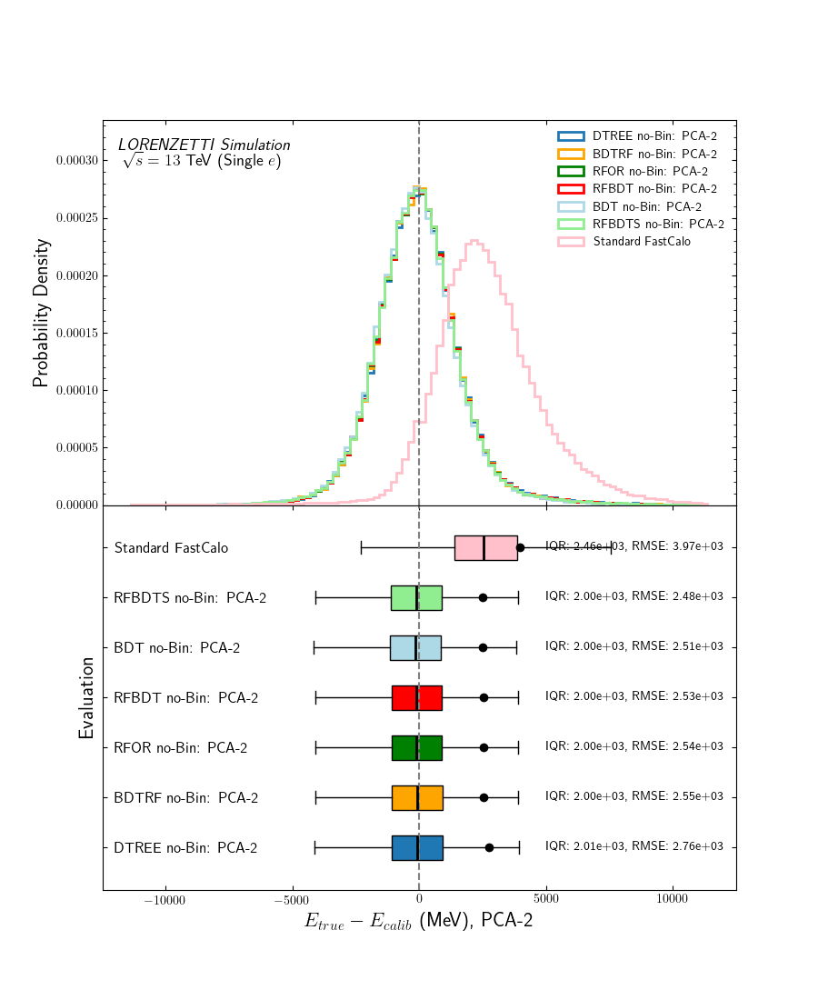

comparison_by_representation_PCA_5_01.png


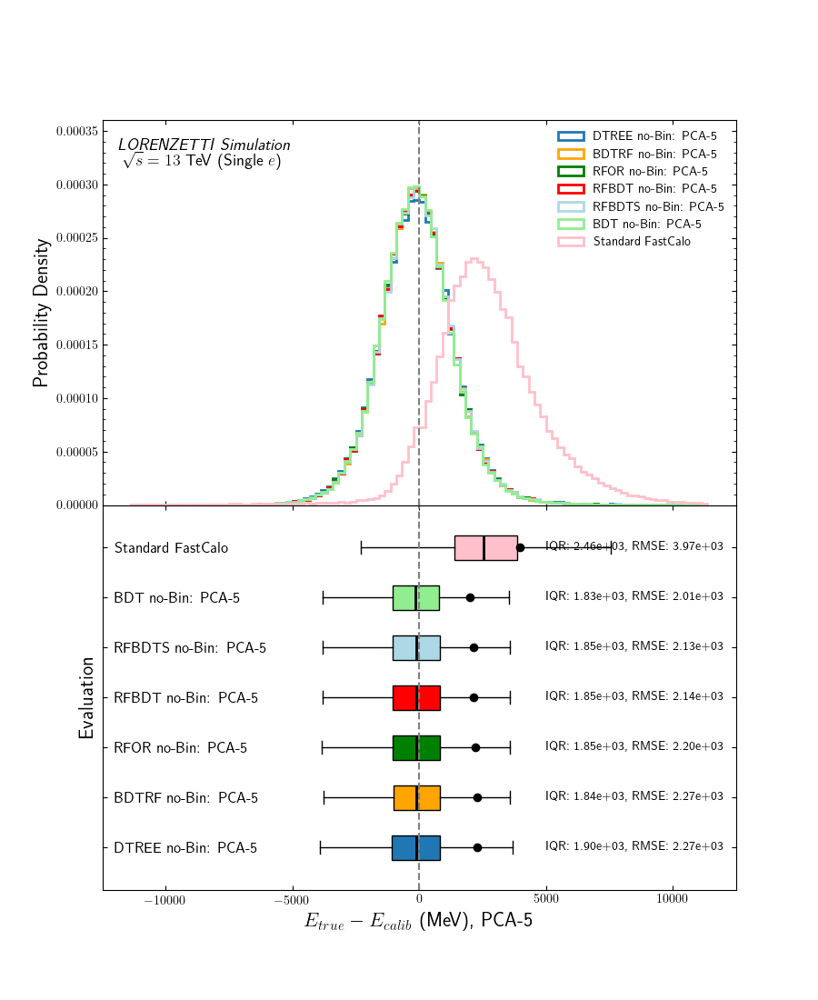

comparison_by_representation_PCA_50_01.png


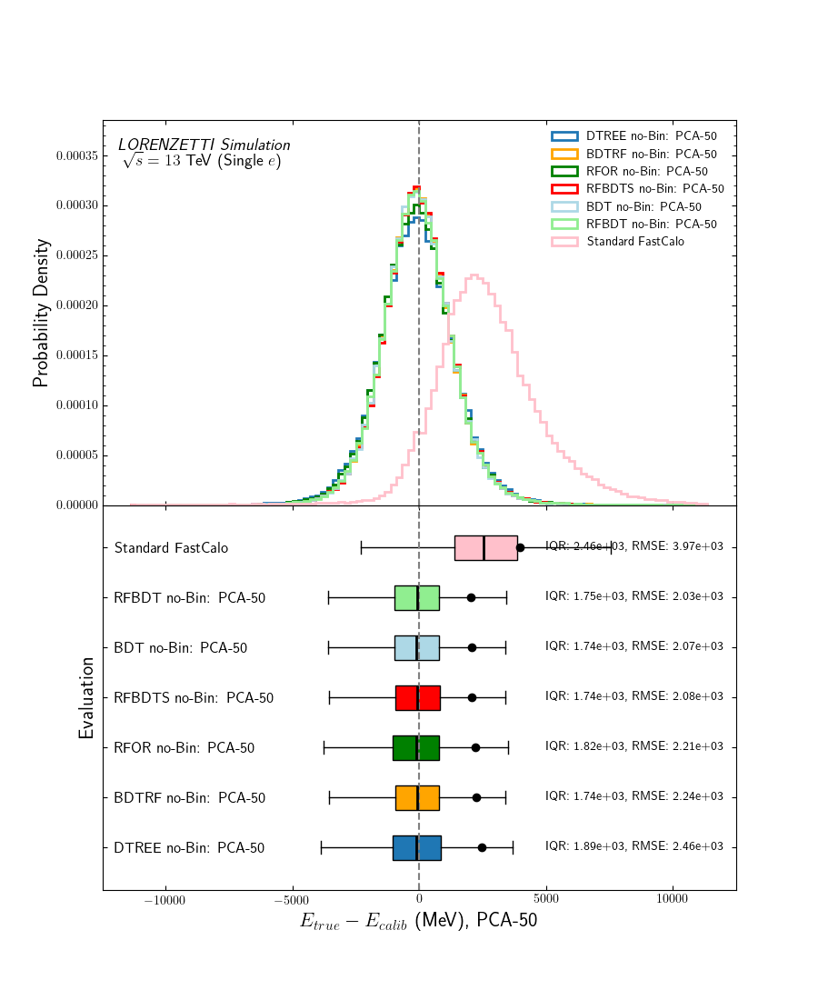

comparison_by_representation_Rings_2_01.png


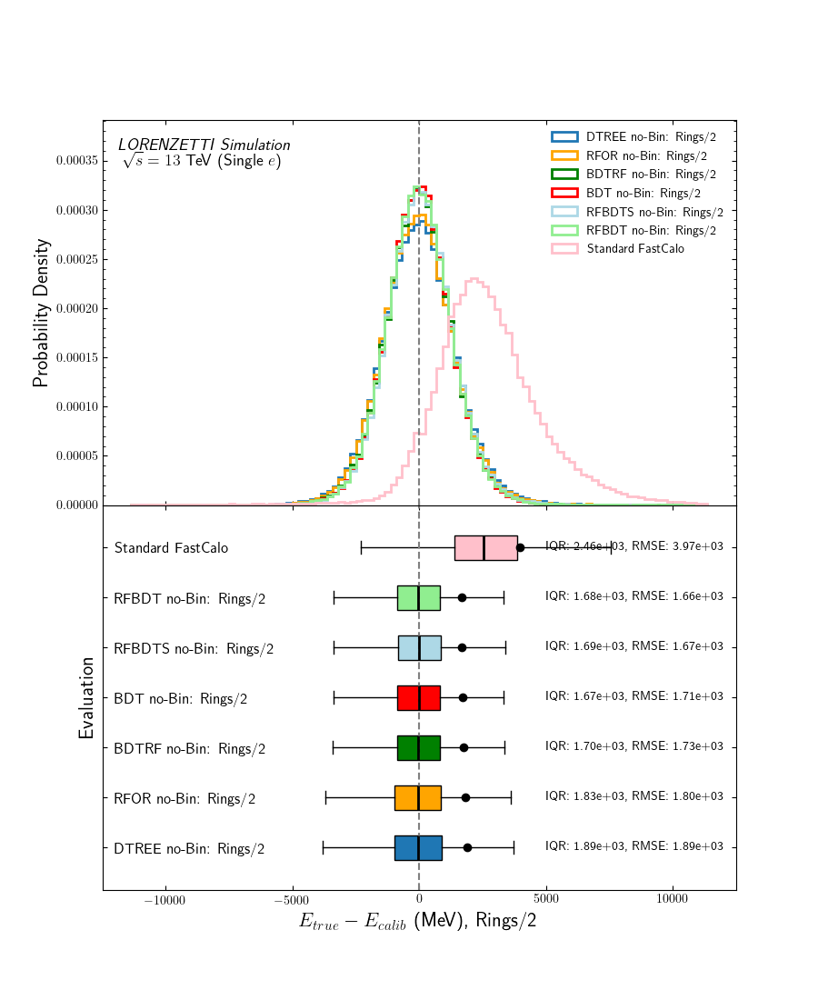

comparison_by_representation_Rings_1_100_01.png


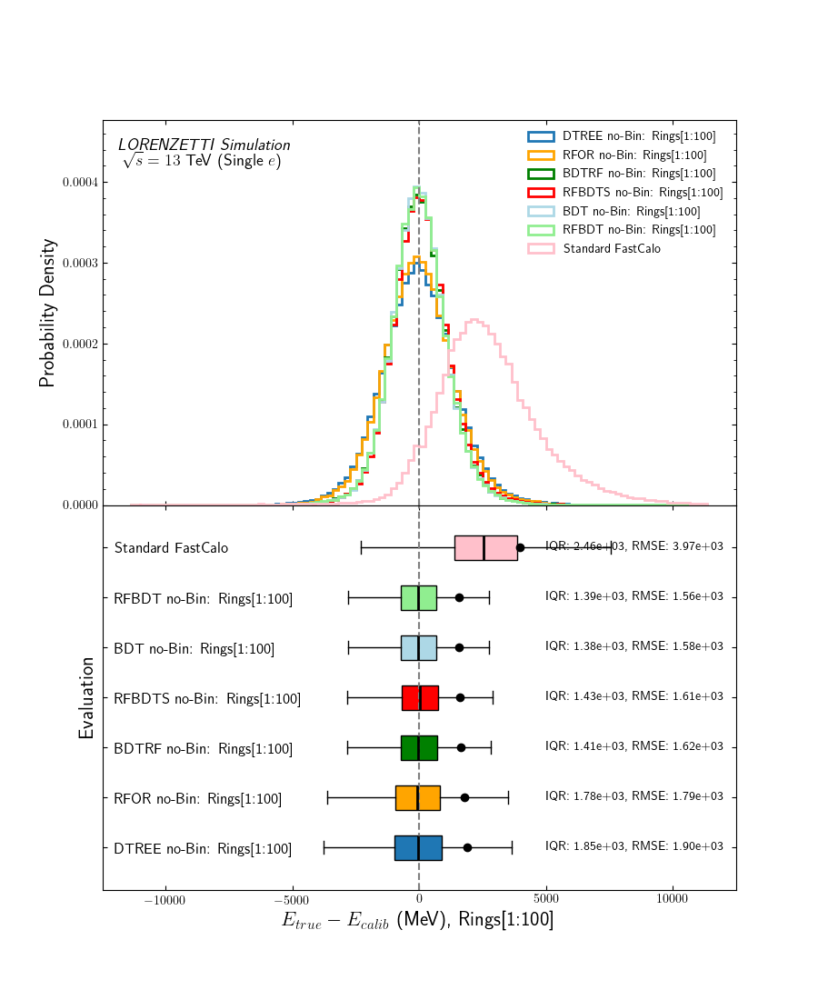

comparison_by_family_rings_cell747_01.png


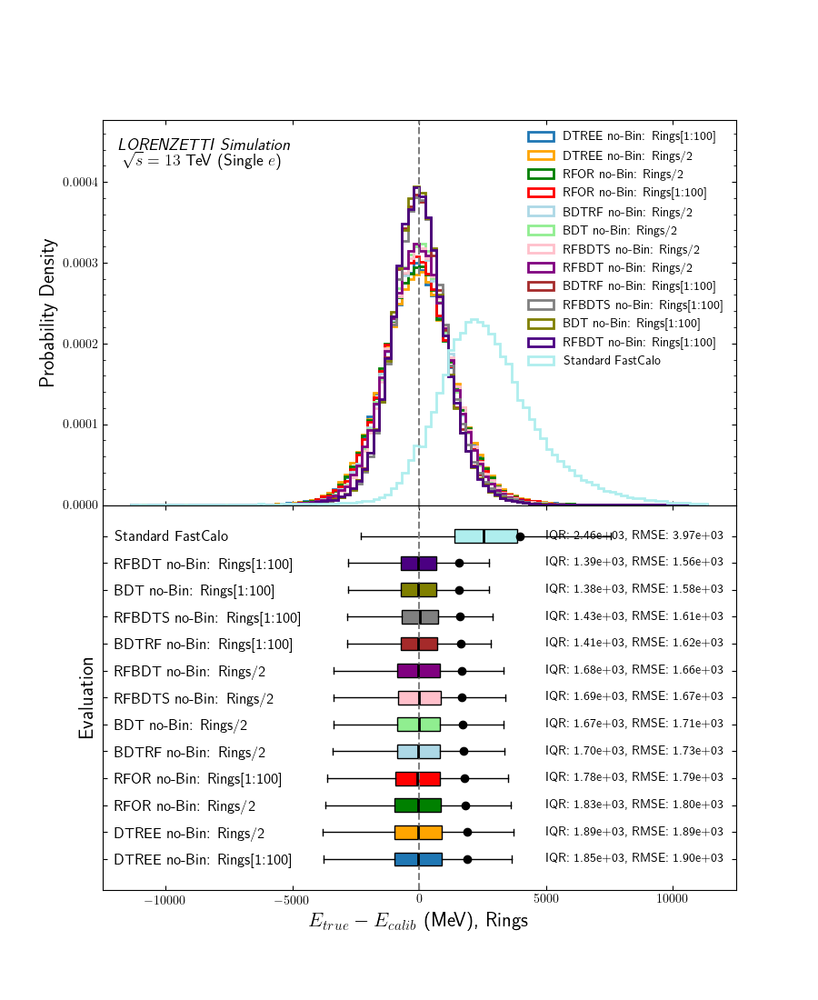

comparison_by_family_corr_cell747_01.png


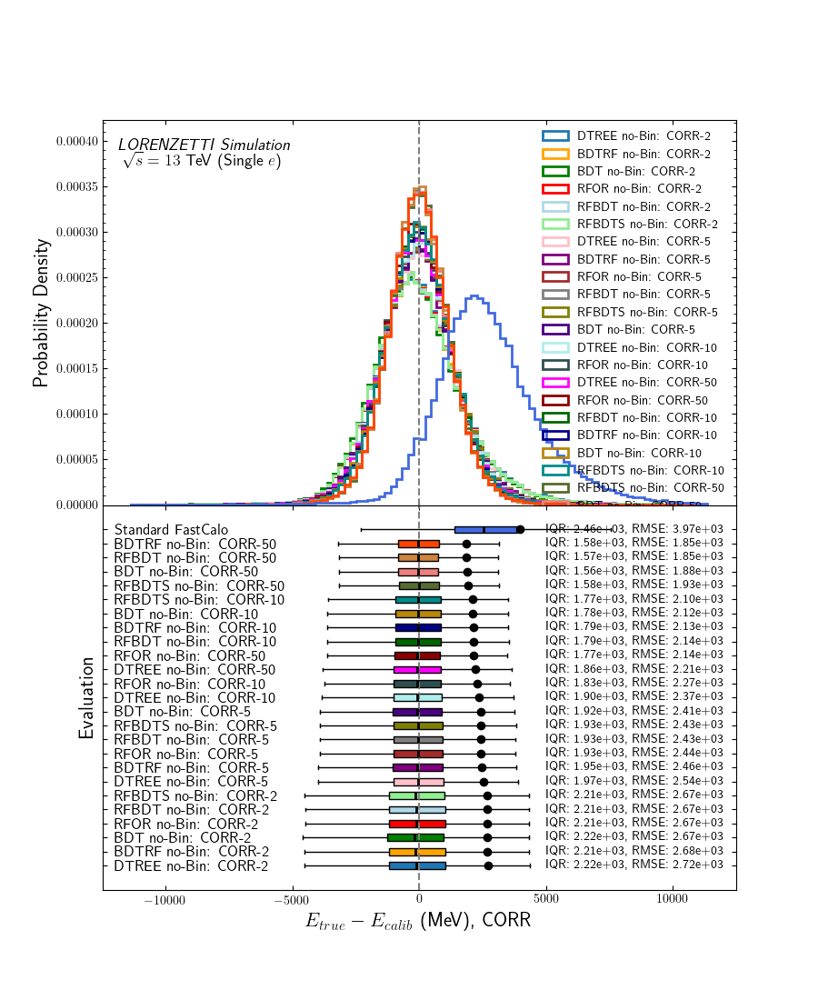

comparison_by_family_muti_cell747_01.png


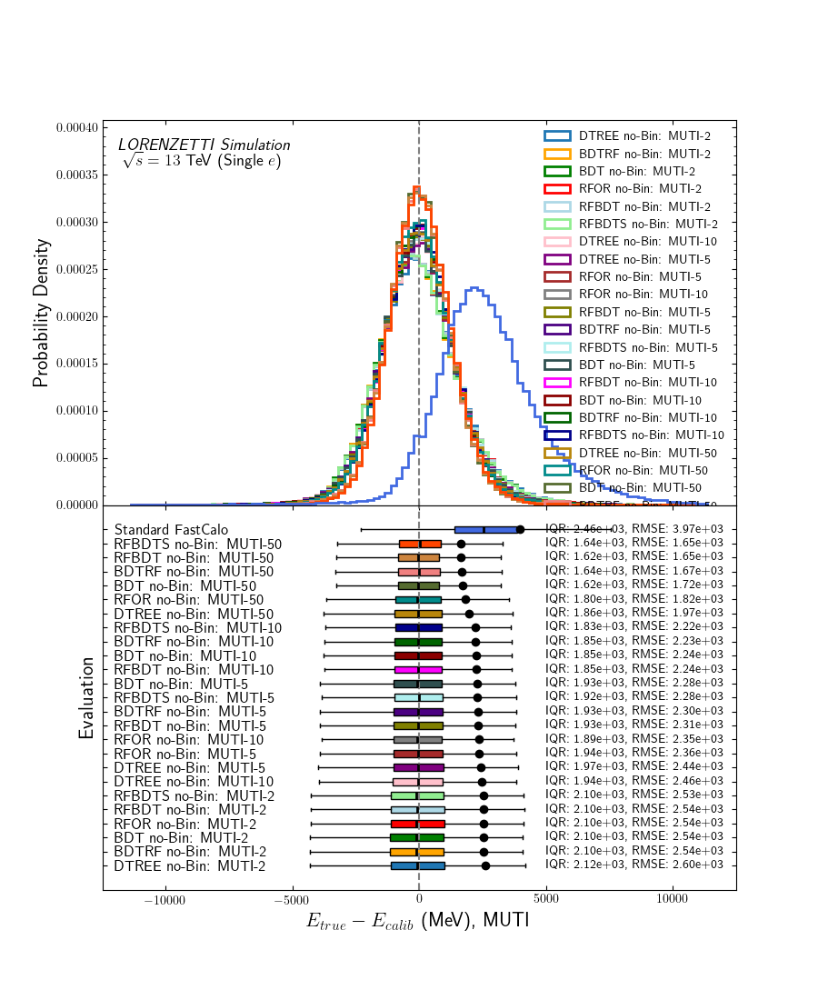

comparison_by_family_pca_cell747_01.png


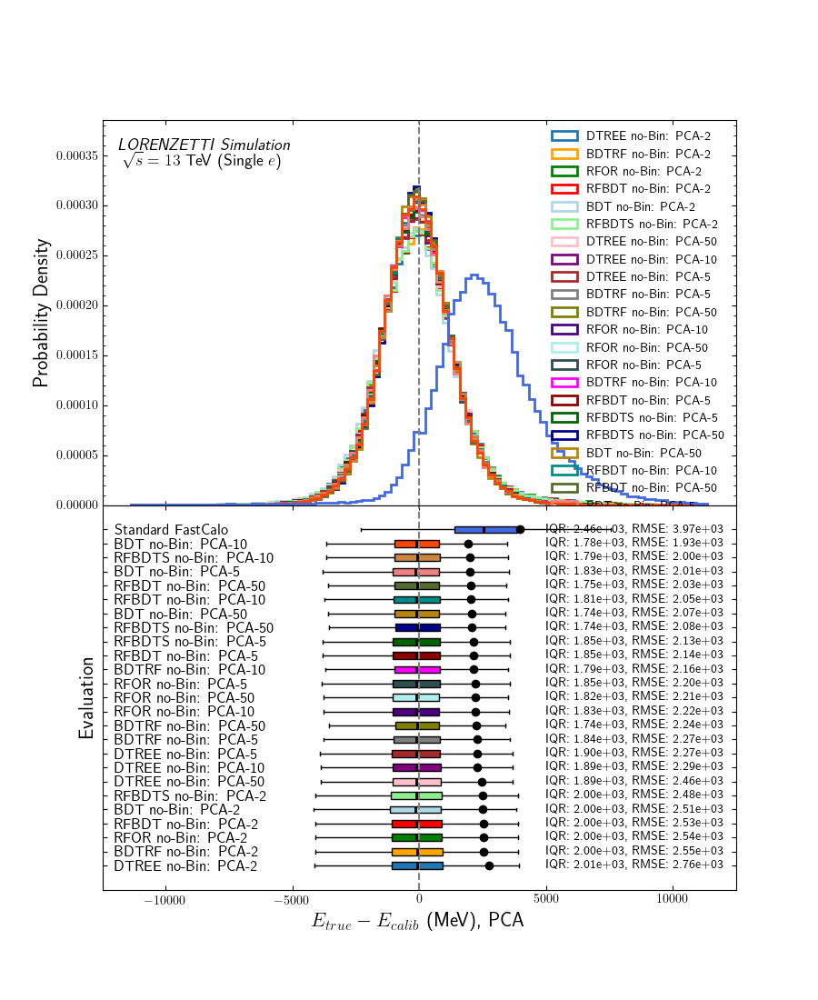

comparison_by_family_ica_cell747_01.png


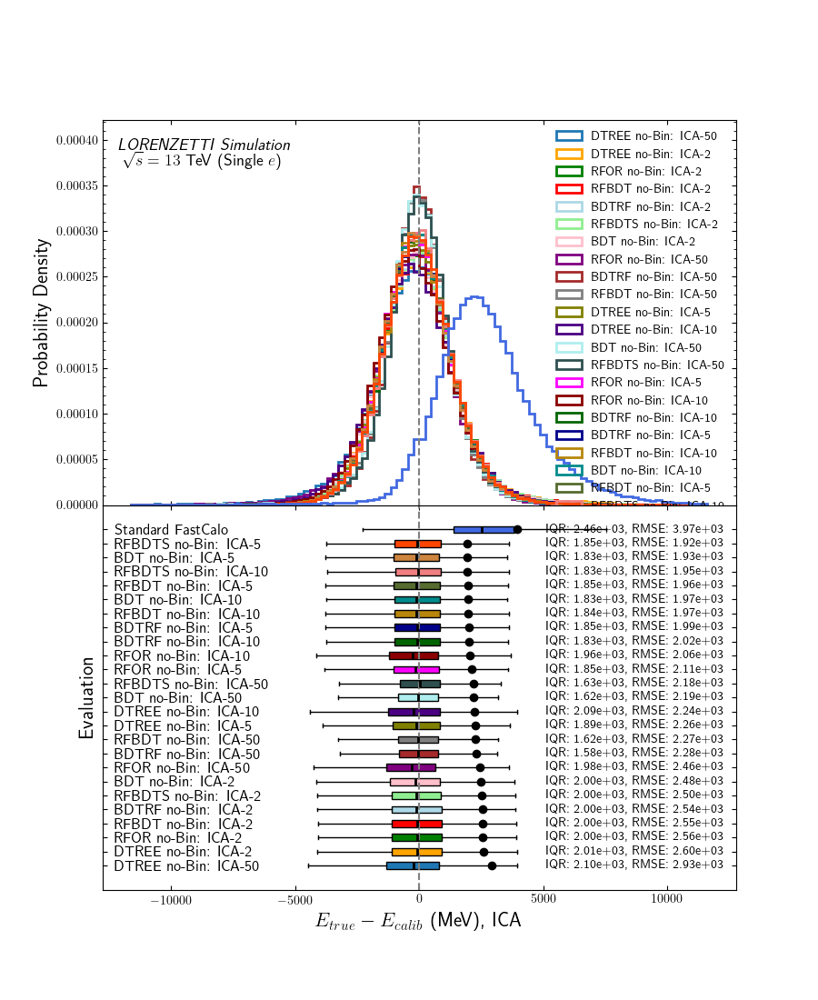

processing_times_cell708_01.png


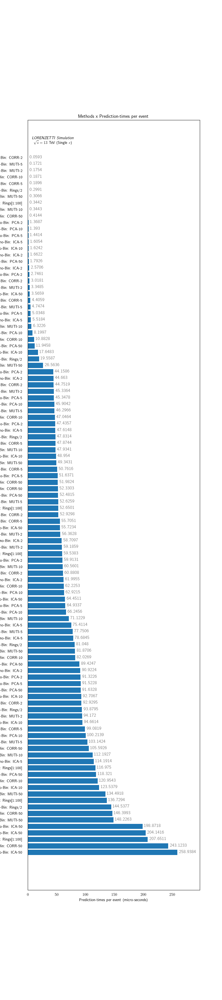

d0_vs_prediction_time_cell713_01.png


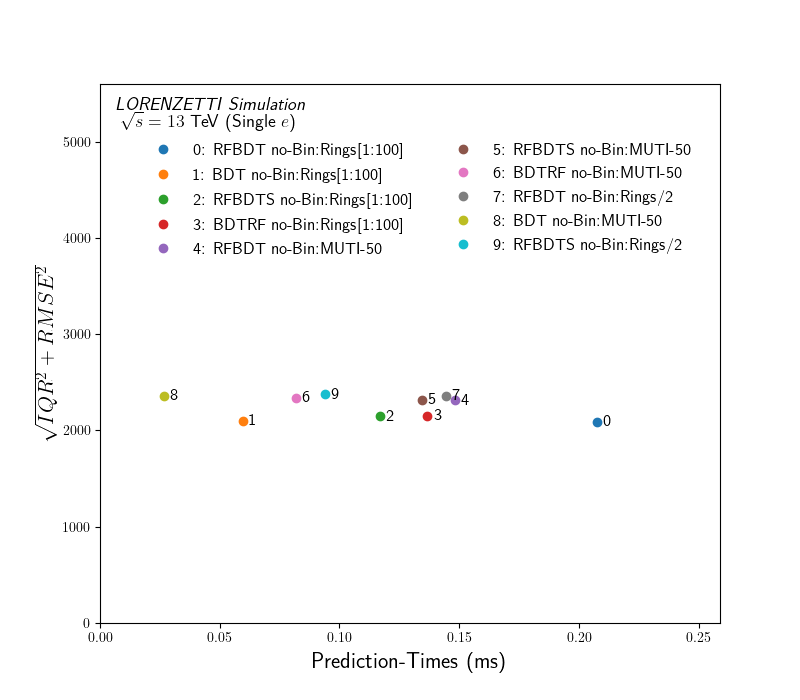

d0_vs_feature_count_cell722_01.png


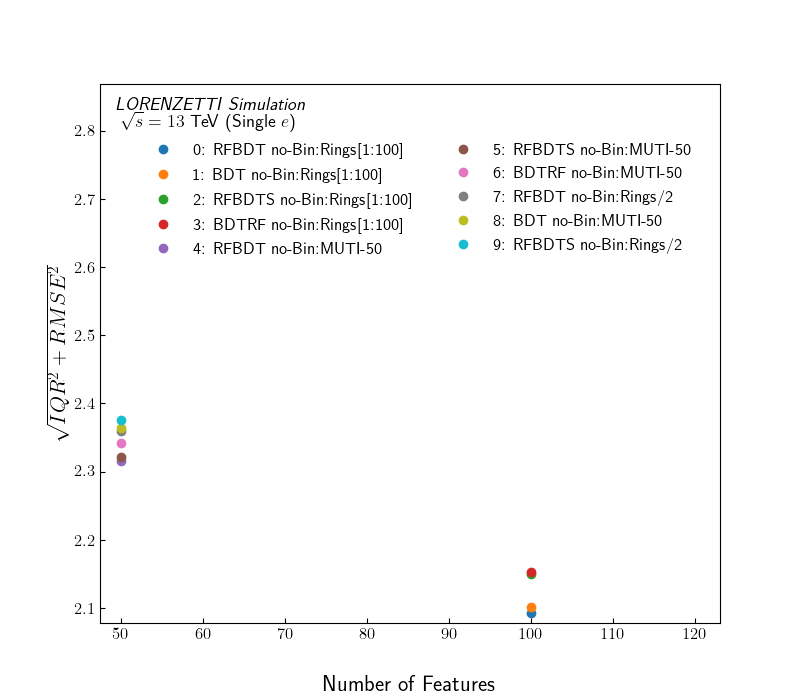

D0_ranked_cell733_01.png


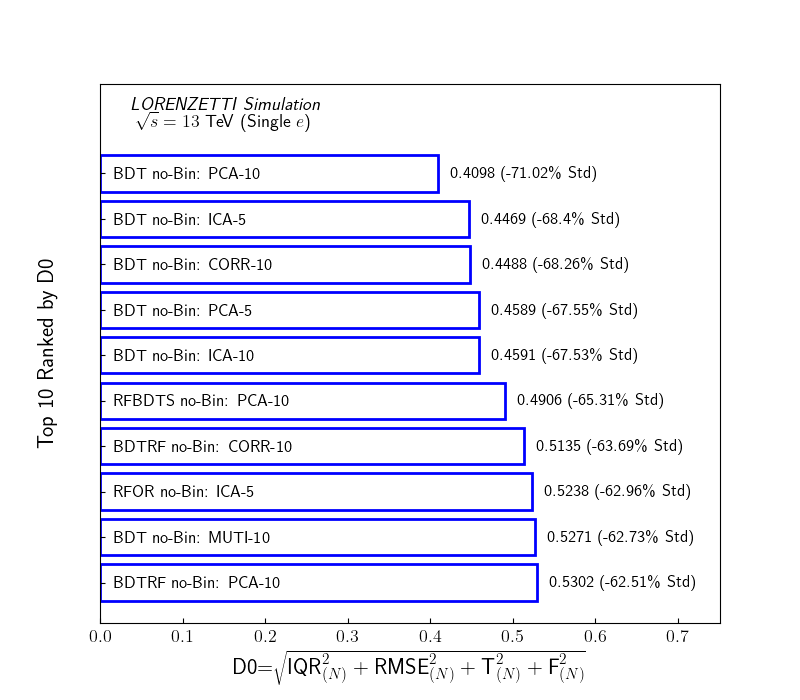

d0_ordered_by_D0_cell734_01.png


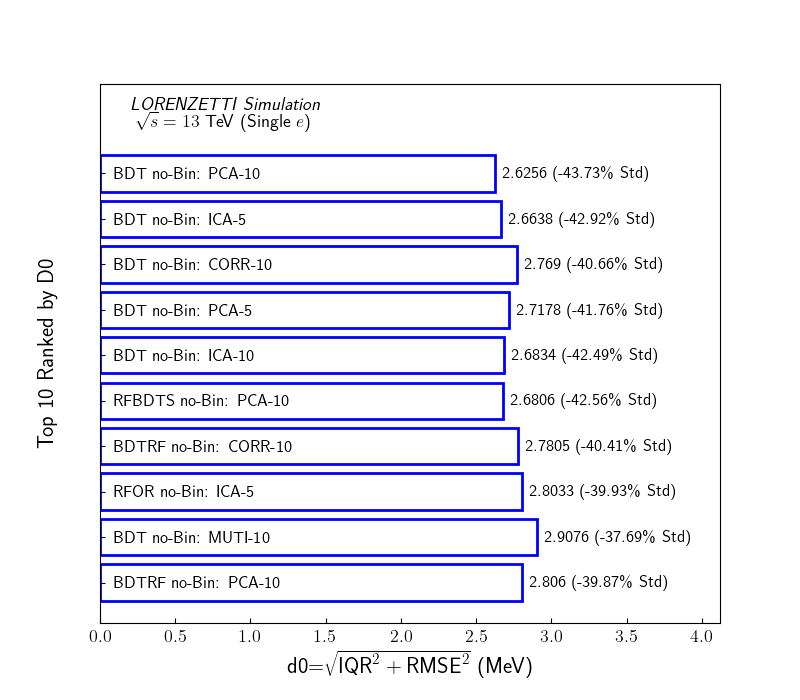

D0_ordered_by_d0_cell735_01.png


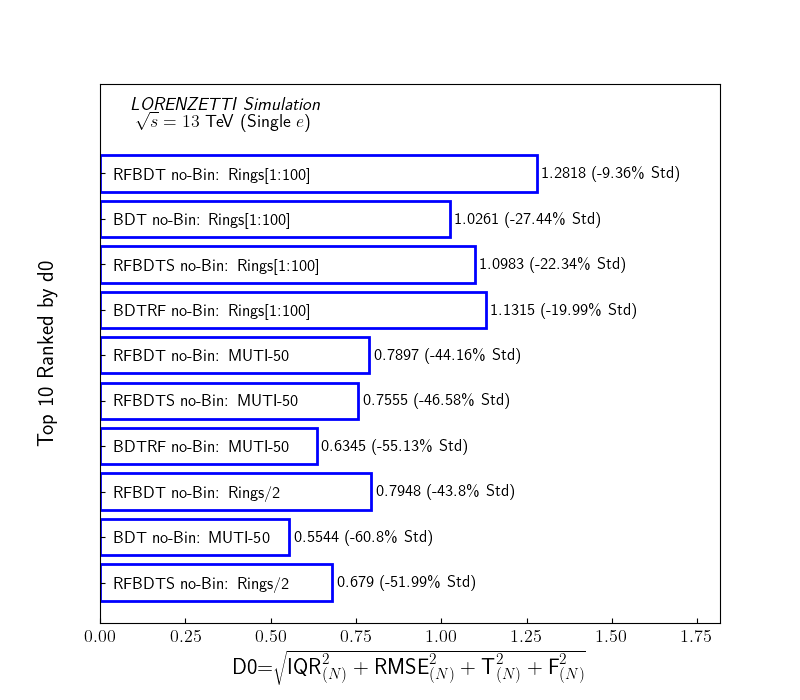

top_ten_by_d0_cells756_757_01.png


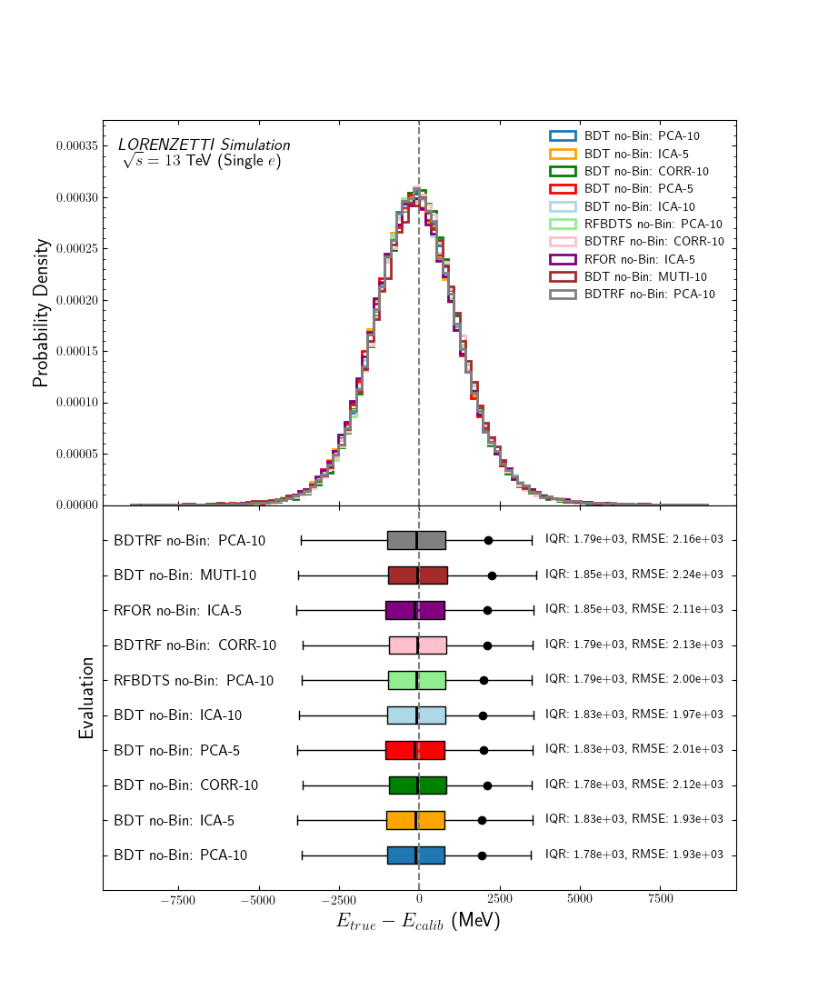

paired_difference_qq_cell789_01.png


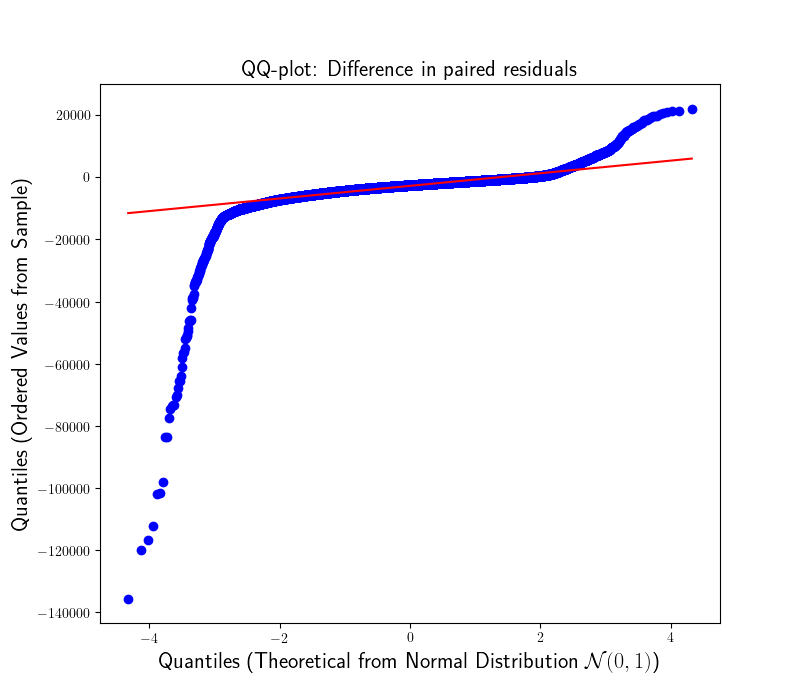

paired_qq_001_cell805_01.png


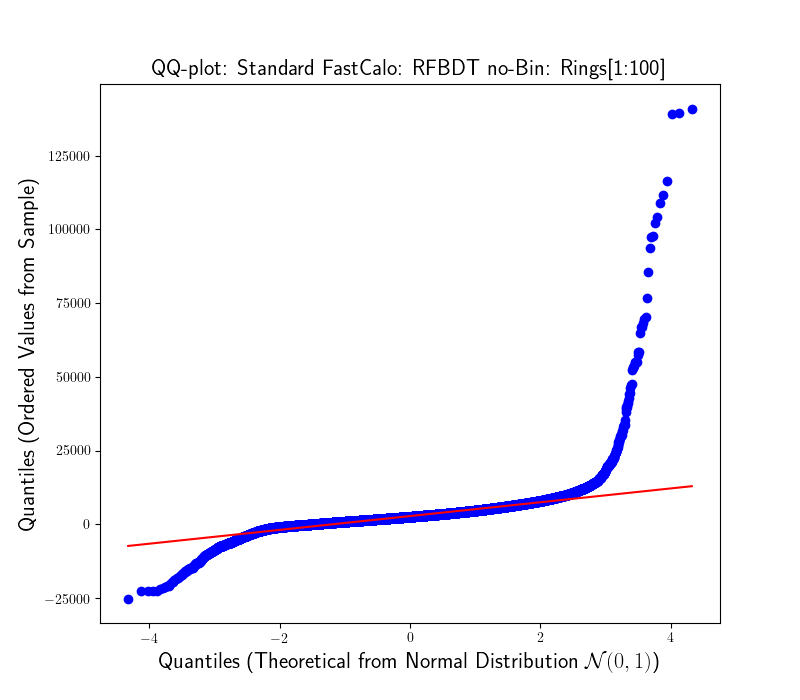

paired_qq_001_cell805_02.png


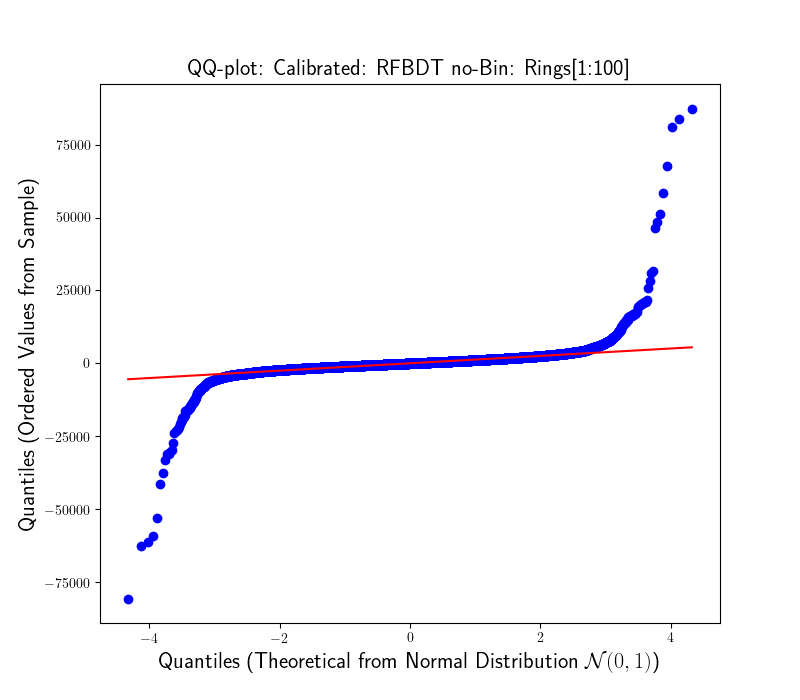

paired_qq_001_cell805_03.png


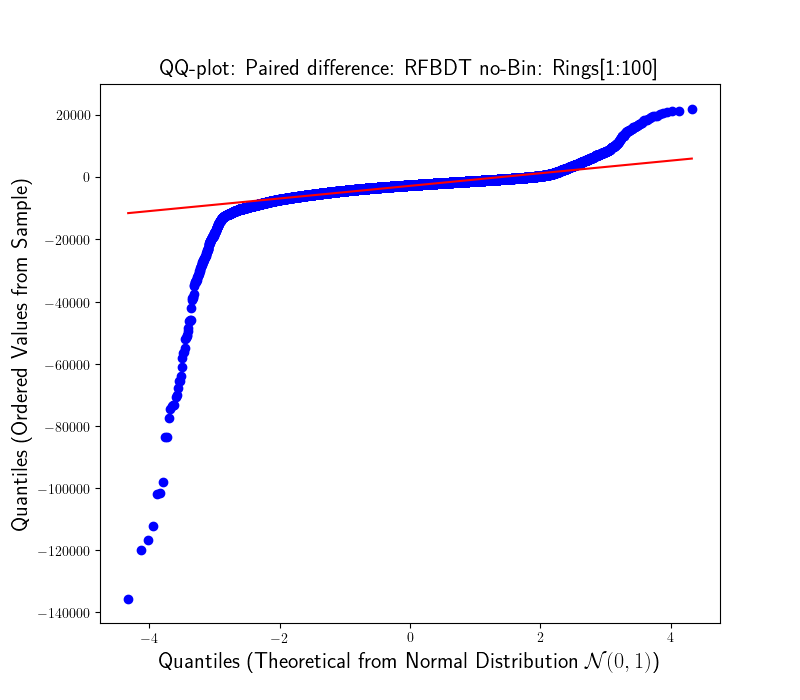

paired_qq_002_cell805_01.png


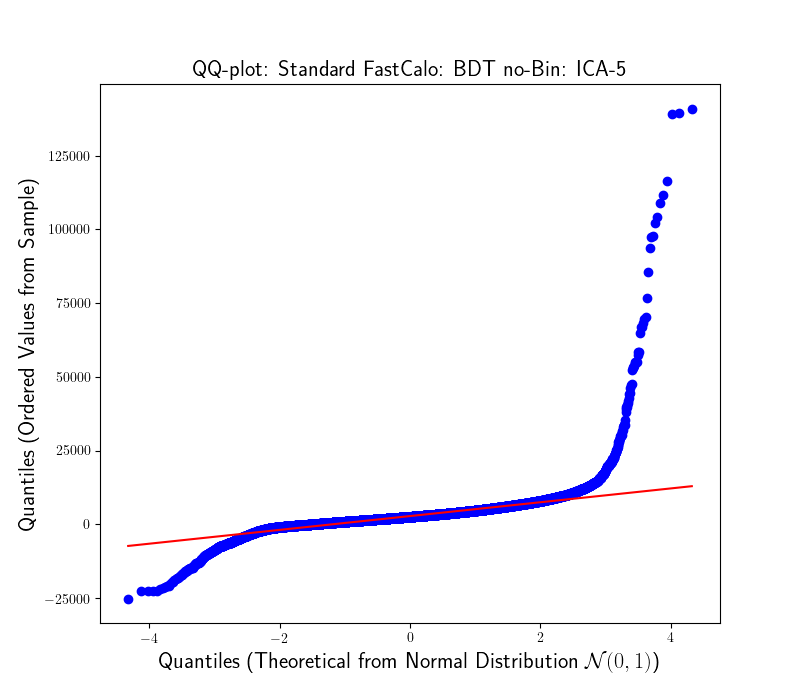

paired_qq_002_cell805_02.png


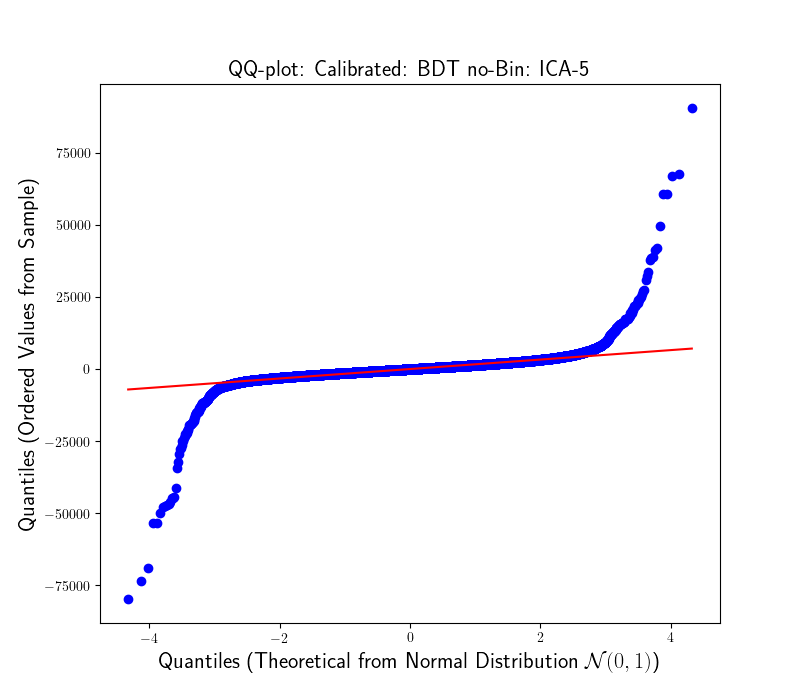

paired_qq_002_cell805_03.png


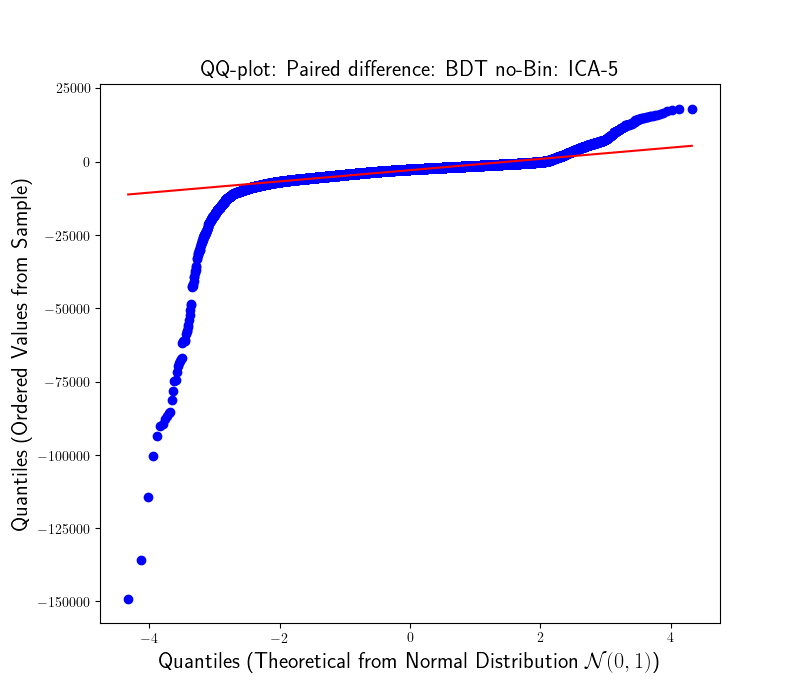

paired_qq_003_cell805_01.png


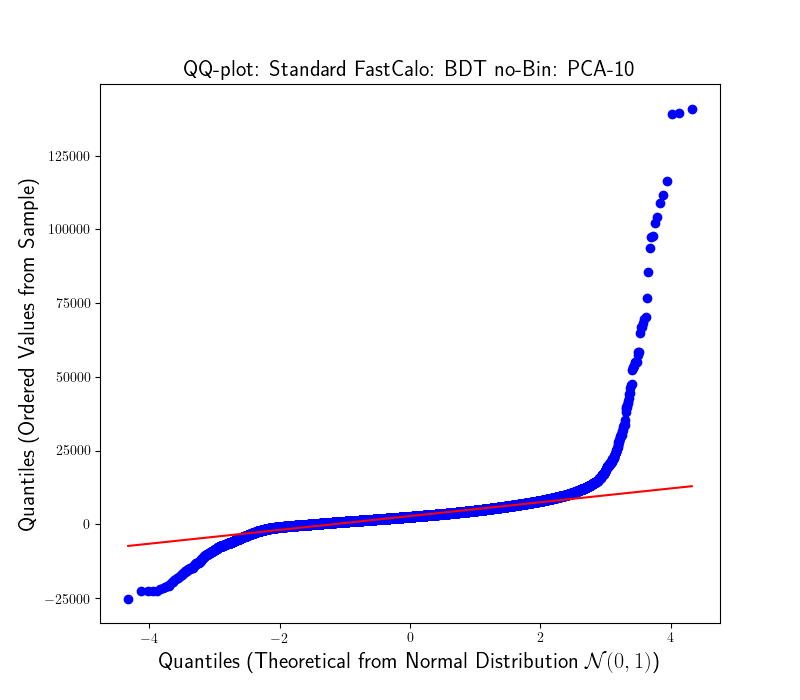

paired_qq_003_cell805_02.png


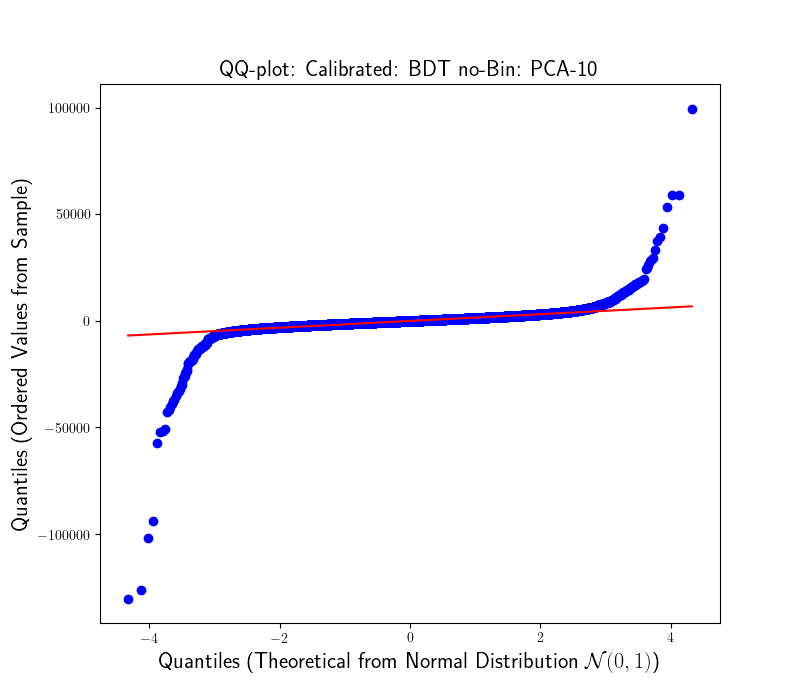

paired_qq_003_cell805_03.png


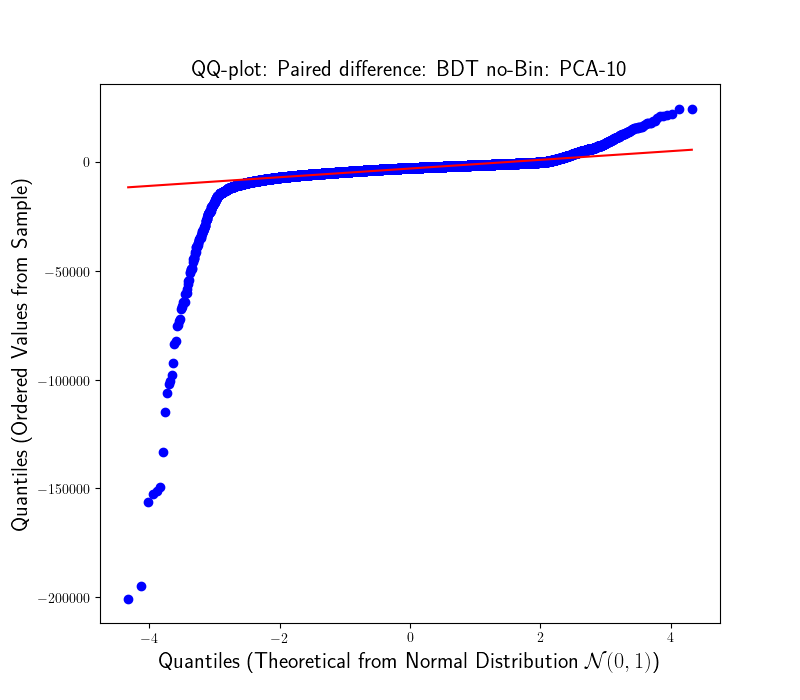

paired_qq_004_cell805_01.png


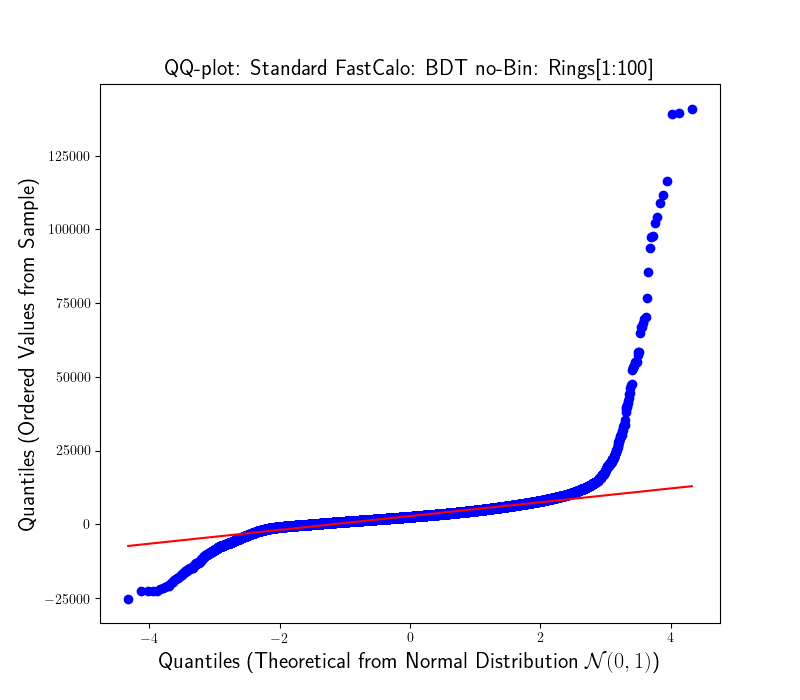

paired_qq_004_cell805_02.png


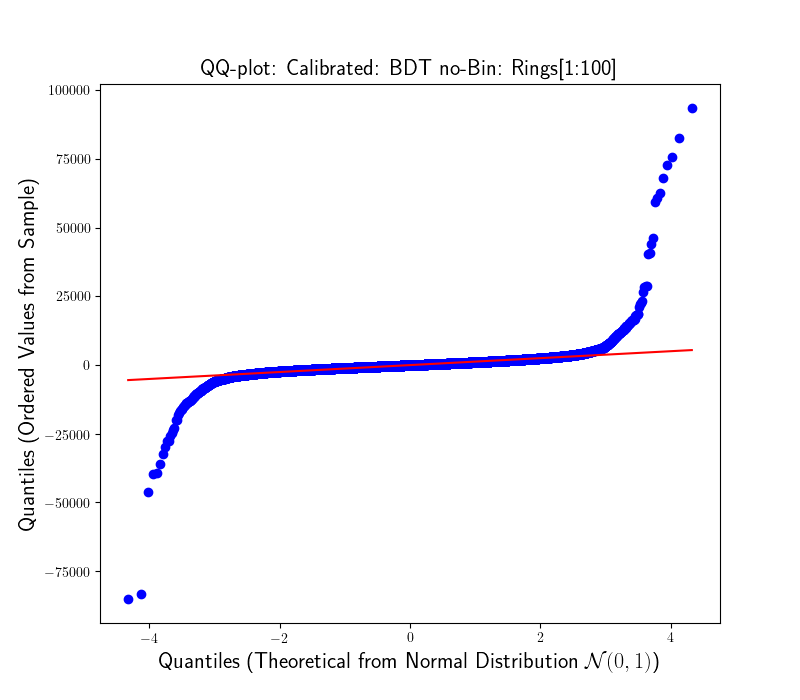

paired_qq_004_cell805_03.png


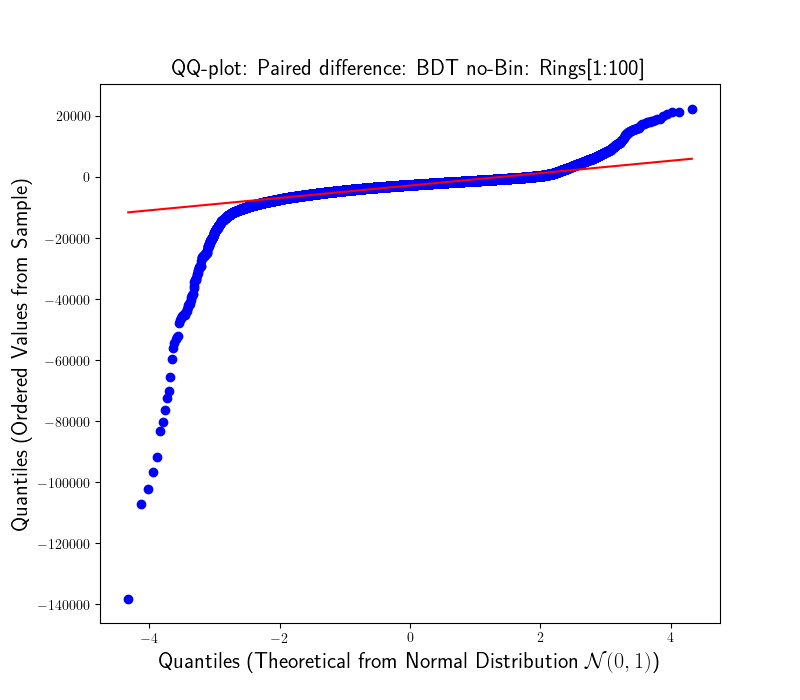

Displayed image files: 144


In [6]:
# Display every available data-generated panel by its article figure number.
# Original figure size, fonts, legends and color schemes come from source code.
from IPython.display import display, Image, Markdown
from pathlib import Path
FIGURE_ROWS=PAPER_REPORT['coverage']
seen=set()
for _,figure in FIGURE_ROWS.iterrows():
    display(Markdown(f"### Figure {int(figure['figure'])} — {figure['description']}"))
    if figure['status'] != 'generated':
        print('Status:', figure['status'])
        print('Unresolved inputs:', figure['missing_source_groups'])
    if figure['files']:
        for file in figure['files'].split(' | '):
            path=PLOT_OUTPUT/file
            if path.is_file():
                display(Image(filename=str(path)))
                seen.add(path.resolve())
# All other experimental configurations are still accessible; no models are
# silently dropped simply because they are not featured in the paper.
MORE_FIGURES=[p for p in PAPER_REPORT['files'] if p.resolve() not in seen]
if MORE_FIGURES:
    display(Markdown('### Additional archived configurations'))
    for path in MORE_FIGURES:
        print(path.name)
        display(Image(filename=str(path)))
print('Displayed image files:',len(PAPER_REPORT['files']))


## 6. Figure coverage and reproducibility checks


In [7]:
# A paper result figure is complete only when all its required source groups exist.
display(PAPER_REPORT['coverage'])
remaining=PAPER_REPORT['coverage'].query("status != 'generated'")
if len(remaining):
    display(Markdown(f"**{len(remaining)} paper figures have missing or partial inputs.**"))
    display(remaining[['figure','description','status','missing_source_groups','error']])
else:
    print('Every indexed paper result figure was produced from archived predictions and/or source events.')
print('Coverage index:', PLOT_OUTPUT/'paper_figure_coverage.csv')
print('Generated PNGs:',len(PAPER_REPORT['files']))
if not PAPER_REPORT['files']:
    raise FileNotFoundError('No figures generated. Inspect the saved result pickle directory and Lorenzetti dataset path.')


,paper,figure,description,status,files,missing_source_groups,error
0,measurement,5,Energy distributions and true/fast scatter,generated,source_diagnostics\original_true_fast_histogra...,,
1,measurement,6,Standardized error and distribution goodness-o...,generated,source_diagnostics\original_standardized_error...,,
2,measurement,7,True calibration factor vs eta and ET,generated,source_diagnostics\original_true_alpha_eta_01....,,
3,measurement,8,100 ring distributions,generated,source_diagnostics\original_100_ring_boxplot_0...,,
4,measurement,9,"CORR, MI, PCA and ICA feature map",generated,source_diagnostics\original_feature_relevance_...,,
5,measurement,10,Calibration residual distributions by represen...,generated,trained_model_figures\original_hist_boxplot_co...,,
6,measurement,11,Joint error and complexity ranking,generated,trained_model_figures\original_d0_ranking_01.png,,
7,measurement,12,IQR in eta and energy regions,generated,trained_model_figures\original_segmented_01.pn...,,
8,measurement,13,MAE and RMSE in eta and energy regions,generated,trained_model_figures\original_segmented_03.pn...,,
9,measurement,14,Calibration-factor regional boxplots,generated,trained_model_figures\original_segmented_boxpl...,,


Every indexed paper result figure was produced from archived predictions and/or source events.
Coverage index: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\results\replayed\measurement\paper_figures\paper_figure_coverage.csv
Generated PNGs: 144
